# Milestone 4 — Gaussian Simulation and Portfolio Optimization

**Research question:** How do Markowitz, Equal Risk Contribution (ERC), and minimum-CVaR portfolios differ when asset returns are Gaussian with constant volatility and correlation?

This is a **self-contained Milestone 4 implementation**. It retains the original **420 subtasks** (Tasks 33–68) and adds **83 subtasks** (Tasks 69–84) for explicit sanity checks and final visual generation. Each numbered subtask has its own code cell, with a Markdown explanation directly above it.

The notebook carries forward the existing project's necessary configuration, simulation, estimation, optimization, evaluation and reproducibility logic. It does **not** implement Milestones 5–9 or recreate the research activities in Milestones 1–3. The checks in Tasks 68–74 belong to Milestone 4 itself. Final visual generation is at the bottom in Tasks 75–84.

**How to run:** Use Python 3.11–3.13 with NumPy, SciPy, pandas, Matplotlib and IPython. Open in Jupyter, VS Code or Colab and select **Restart Kernel and Run All**. There are no local-package imports, external datasets, drive mounts, downloads or credentials. Install missing libraries in your environment before running; the notebook does not install anything automatically. Output files go into a new timestamped subfolder of `milestone4_results/` under the kernel's working directory.

**Scope and settings:** The four synthetic assets, seed, daily simple-return convention, risk aversion and independent/controlled comparison modes come from the existing project. Training, optimization and evaluation sizes are increased to 10,000, 10,000 and 50,000. These are explicit **development choices**, not calibrated asset forecasts or final approved thesis assumptions. The run uses estimated information, long-only fully invested weights, zero transaction costs and fixed daily target weights. Confidence levels are 95% and 99%; CVaR is optimized at 95%.

**Reading the results:** A mode contains three strategies; two modes therefore produce six columns. `true` denotes population parameters for simulation and validation, while `hat` or `opt` denotes information fitted from historical observations. No evaluation data enter fitting. Statistical flags are distinguished from deterministic failures.

## Notebook map

- [Part A — Define the asset distribution](#part-a): Tasks 33–38
- [Part B — Generate Gaussian returns](#part-b): Tasks 39–47
- [Part C — Markowitz optimization](#part-c): Tasks 48–50
- [Part D — ERC optimization](#part-d): Tasks 51–53
- [Part E — CVaR optimization](#part-e): Tasks 54–57
- [Part F — Independent evaluation and validation](#part-f): Tasks 58–68

Task headings explain the mathematical purpose. Subtask headings preserve the document's exact numbering. A few function, solver and plotting cells are longer than 2–3 lines because their Python bodies must be defined together; internal comments explain each logical block.
- [Part G — Explicit sanity checks](#part-g): Tasks 69–74
- [Part H — Final visual generation](#part-h): Tasks 75–84

## Setup — Import the notebook dependencies

NumPy handles arrays and random draws; SciPy supplies optimizers and probability distributions; pandas organizes results; Matplotlib draws figures. Standard-library modules support saving artifacts and running the clean-process reproduction. All scientific implementation remains visible in this notebook.

In [1]:
import hashlib
import inspect
import json
import platform
import subprocess
import sys
import tempfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt

# Numerical arrays, sparse optimization and distribution functions.
import numpy as np

# Tabular outputs and publication-ready figures stay inside this notebook.
import pandas as pd
import scipy
from IPython.display import Markdown, display
from scipy import sparse, stats
from scipy.optimize import OptimizeResult, linprog, minimize

## Setup — Small reusable utilities

`check` records deterministic pass/fail results and stops on failure. `near` handles floating-point comparisons. Independent generators use stable purpose identifiers. The other helpers display tables, serialize metadata and hash arrays without changing numerical precision. This is supporting infrastructure for Milestone 4, not a separate milestone implementation.

In [2]:
# Separate deterministic correctness checks from sampling-error diagnostics.
checks, statistical_flags = [], []


def check(name, condition, detail=""):
    passed = bool(condition)
    checks.append({"check": name, "passed": passed, "detail": str(detail)})
    if not passed:
        raise AssertionError(f"{name}: {detail}")


def near(a, b, atol=1e-10, rtol=1e-8):
    return bool(np.allclose(a, b, atol=atol, rtol=rtol))


# Stable identities reproduce the existing project's independent stream design.
def rng_for(seed, stream, replication=0):
    sequence = np.random.SeedSequence(int(seed), spawn_key=(replication, stream))
    return np.random.Generator(np.random.PCG64(sequence))


# A compact table renderer avoids permanently changing global display settings.
def show(data):
    with pd.option_context(
        "display.max_rows", 30, "display.max_columns", 18, "display.precision", 7
    ):
        display(data)


# Convert NumPy values without rounding the scientific data saved to disk.
def jsonable(value):
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, dict):
        return {str(k): jsonable(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [jsonable(v) for v in value]
    return value


def write_json(path, value):
    Path(path).write_text(json.dumps(jsonable(value), indent=2, allow_nan=False))


def array_hash(a):
    contiguous = np.ascontiguousarray(a)
    header = f"{contiguous.dtype}:{contiguous.shape}".encode()
    return hashlib.sha256(header + contiguous.tobytes()).hexdigest()


pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180, "font.size": 10})

## Setup — Record the execution environment

Package versions can affect numerical solver details. Record the versions actually running this notebook, so a reader can reproduce the environment. Random reproducibility is based on the explicit generators rather than the system time.

In [3]:
print(
    {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "scipy": scipy.__version__,
        "pandas": pd.__version__,
        "matplotlib": matplotlib.__version__,
    }
)

{'python': '3.13.2', 'numpy': '2.5.5', 'scipy': '1.18.1', 'pandas': '3.1.1', 'matplotlib': '3.11.2'}


<a id="part-a"></a>

## Part A Define The Asset Distribution

### Task 33 — Define the expected return vector for all simulated assets

We use the existing project's four synthetic assets, in the same order and daily decimal units. For the population model, $r_t\sim N(\mu,\Sigma)$. The suffix `true` identifies the data-generating parameters; optimization will use estimates from training observations. The larger sample sizes below are notebook development choices for more informative diagnostics, not supervisor-approved final settings.

#### Subtask 33.1 — Load the experiment configuration created in Milestones 1-3

This embedded configuration makes the notebook portable. It preserves the repository's seed, asset parameters, risk aversion and comparison modes, but uses 10,000 historical, 10,000 optimization and 50,000 evaluation observations. Only Milestone 4 is executed.

In [4]:
# 33.1. Load the experiment configuration created in Milestones 1-3.
config = {
    "name": "milestone4_gaussian",
    "seed": 20261030,
    "information_regime": "estimated",
    "return_type": "simple",
    "return_period": "daily",
    "input_units": "decimal",
    "volatility_period": "daily",
    "periods_per_year": 252,
    "history_observations": 10000,
    "optimization_scenarios": 10000,
    "evaluation_observations": 50000,
    "confidence": 0.95,
    "reporting_confidences": [0.95, 0.99],
    "risk_aversion": 5.0,
    "comparison_modes": ["independent", "controlled"],
    "markowitz_formulation": "utility",
    "lower_bound": 0.0,
    "upper_bound": 1.0,
    "leverage_limit": 1.0,
    "return_floor": None,
    "matrix_atol": 1e-12,
    "feasibility_tol": 1e-08,
    "erc_share_tol": 1e-08,
    "statistical_error_level": 0.01,
    "minimum_expected_tail_count": 50,
    "diagnostic_batches": 30,
    "diagnostic_sizes": [1000, 4000, 16000],
    "solver_maxiter": 2000,
    "solver_ftol": 1e-12,
    "output_root": "milestone4_results",
    "market": {
        "asset_names": ["Asset_A", "Asset_B", "Asset_C", "Asset_D"],
        "mean": [0.0002, 0.0003, 0.0004, 0.0005],
        "volatility": [0.008, 0.012, 0.016, 0.02],
        "correlation": [
            [1, 0.3, 0.2, 0.1],
            [0.3, 1, 0.4, 0.2],
            [0.2, 0.4, 1, 0.5],
            [0.1, 0.2, 0.5, 1],
        ],
    },
}
show(pd.Series({k: v for k, v in config.items() if k != "market"}, name="Setting"))

name                                 milestone4_gaussian
seed                                            20261030
information_regime                             estimated
return_type                                       simple
return_period                                      daily
input_units                                      decimal
volatility_period                                  daily
periods_per_year                                     252
history_observations                               10000
optimization_scenarios                             10000
evaluation_observations                            50000
confidence                                          0.95
reporting_confidences                       [0.95, 0.99]
risk_aversion                                        5.0
comparison_modes               [independent, controlled]
markowitz_formulation                            utility
lower_bound                                          0.0
upper_bound                    

#### Subtask 33.2 — Read the ordered asset identifiers into asset_names

We read the ordered asset identifiers into asset_names.

In [5]:
# 33.2. Read the ordered asset identifiers into asset_names.
asset_names = list(config["market"]["asset_names"])
print(asset_names)

['Asset_A', 'Asset_B', 'Asset_C', 'Asset_D']


#### Subtask 33.3 — Count the identifiers and store the number of assets as n_assets

We count the identifiers and store the number of assets as n_assets.

In [6]:
# 33.3. Count the identifiers and store the number of assets as n_assets.
n_assets = len(asset_names)
print("Number of assets:", n_assets)

Number of assets: 4


#### Subtask 33.4 — Reject an empty list or repeated asset identifiers

We reject an empty list or repeated asset identifiers.

In [7]:
# 33.4. Reject an empty list or repeated asset identifiers.
check("unique nonempty asset identifiers", n_assets > 0 and len(set(asset_names)) == n_assets)

#### Subtask 33.5 — Read the configured return type and simulation period

We read the configured return type and simulation period.

In [8]:
# 33.5. Read the configured return type and simulation period.
return_type, return_period = config["return_type"], config["return_period"]
print(return_type, return_period)

simple daily


#### Subtask 33.6 — Confirm that linear portfolio aggregation uses simple asset returns

We confirm that linear portfolio aggregation uses simple asset returns.

In [9]:
# 33.6. Confirm that linear portfolio aggregation uses simple asset returns.
check("linear simple-return aggregation", return_type == "simple")

#### Subtask 33.7 — Read each asset's expected return in the same asset order

We read each asset's expected return in the same asset order.

In [10]:
# 33.7. Read each asset's expected return in the same asset order.
mean_input = np.asarray(config["market"]["mean"], dtype=float)
show(pd.Series(mean_input, index=asset_names, name="Input mean"))

Asset_A    0.0002
Asset_B    0.0003
Asset_C    0.0004
Asset_D    0.0005
Name: Input mean, dtype: float64

#### Subtask 33.8 — Convert percentage inputs to decimals when the configuration requires it

We convert percentage inputs to decimals when the configuration requires it.

In [11]:
# 33.8. Convert percentage inputs to decimals when the configuration requires it.
mean_decimal = mean_input / 100 if config["input_units"] == "percent" else mean_input.copy()
check("recognized return units", config["input_units"] in ("percent", "decimal"))

#### Subtask 33.9 — Convert return frequency only using the approved model convention

No annual-to-daily conversion is needed. Dividing arithmetic means by 252 would be a modeling approximation; it is not applied silently.

In [12]:
# 33.9. Convert return frequency only using the approved model convention.
check("means already in daily units", return_period == "daily")
print("No frequency conversion: the embedded means are already daily arithmetic means.")

No frequency conversion: the embedded means are already daily arithmetic means.


#### Subtask 33.10 — Create the one-dimensional numeric vector mu_true

We create the one-dimensional numeric vector mu_true.

In [13]:
# 33.10. Create the one-dimensional numeric vector mu_true.
mu_true = mean_decimal.reshape(-1).copy()
print("mu_true =", mu_true)

mu_true = [0.0002 0.0003 0.0004 0.0005]


#### Subtask 33.11 — Check that mu_true has shape (n_assets,) and only finite values

We check that mu_true has shape (n_assets,) and only finite values.

In [14]:
# 33.11. Check that mu_true has shape (n_assets,) and only finite values.
check("valid expected-return vector", mu_true.shape == (n_assets,) and np.isfinite(mu_true).all())

#### Subtask 33.12 — Display each asset beside its mean and return-period label

We display each asset beside its mean and return-period label.

In [15]:
# 33.12. Display each asset beside its mean and return-period label.
asset_parameters = pd.DataFrame({"mean_daily": mu_true, "period": return_period}, index=asset_names)
show(asset_parameters)

,mean_daily,period
Asset_A,0.0002,daily
Asset_B,0.0003,daily
Asset_C,0.0004,daily
Asset_D,0.0005,daily


### Task 34 — Define the volatility of each simulated asset

The standard deviation $\sigma_i$ measures one-day return dispersion. Its square is the variance. Positive volatilities make correlation and normalized ERC shares well-defined; zero-volatility assets are rejected for this baseline.

#### Subtask 34.1 — Read the configured volatility for each asset in asset_names order

We read the configured volatility for each asset in asset_names order.

In [16]:
# 34.1. Read the configured volatility for each asset in asset_names order.
volatility_input = np.asarray(config["market"]["volatility"], dtype=float)
print(volatility_input)

[0.008 0.012 0.016 0.02 ]


#### Subtask 34.2 — Check the units and period attached to the volatility inputs

We check the units and period attached to the volatility inputs.

In [17]:
# 34.2. Check the units and period attached to the volatility inputs.
print("Volatility units:", config["input_units"], "| period:", config["volatility_period"])

Volatility units: decimal | period: daily


#### Subtask 34.3 — Convert percentage volatilities to decimals if needed

We convert percentage volatilities to decimals if needed.

In [18]:
# 34.3. Convert percentage volatilities to decimals if needed.
volatility_decimal = (
    volatility_input / 100 if config["input_units"] == "percent" else volatility_input.copy()
)

#### Subtask 34.4 — Apply square-root-of-time scaling only under the configured IID convention

We apply square-root-of-time scaling only under the configured IID convention.

In [19]:
# 34.4. Apply square-root-of-time scaling only under the configured IID convention.
check("volatility already matches simulation period", config["volatility_period"] == return_period)
print("No annualization or de-annualization is applied here.")

No annualization or de-annualization is applied here.


#### Subtask 34.5 — Create the one-dimensional numeric vector sigma_true

We create the one-dimensional numeric vector sigma_true.

In [20]:
# 34.5. Create the one-dimensional numeric vector sigma_true.
sigma_true = volatility_decimal.reshape(-1).copy()

#### Subtask 34.6 — Check that sigma_true has exactly one value per asset

We check that sigma_true has exactly one value per asset.

In [21]:
# 34.6. Check that sigma_true has exactly one value per asset.
check("volatility vector length", sigma_true.shape == (n_assets,))

#### Subtask 34.7 — Reject non-finite values and negative volatilities

We reject non-finite values and negative volatilities.

In [22]:
# 34.7. Reject non-finite values and negative volatilities.
check("finite nonnegative volatilities", np.isfinite(sigma_true).all() and np.all(sigma_true >= 0))

#### Subtask 34.8 — Identify any zero-volatility asset and apply the agreed special-case policy

We identify any zero-volatility asset and apply the agreed special-case policy.

In [23]:
# 34.8. Identify any zero-volatility asset and apply the agreed special-case policy.
zero_volatility_assets = [asset_names[i] for i in np.flatnonzero(sigma_true == 0)]
print("Zero-volatility assets:", zero_volatility_assets)

Zero-volatility assets: []


#### Subtask 34.9 — Require positive volatilities for the standard correlation and ERC workflow

We require positive volatilities for the standard correlation and ERC workflow.

In [24]:
# 34.9. Require positive volatilities for the standard correlation and ERC workflow.
check("positive volatility for standard ERC baseline", np.all(sigma_true > 0))

#### Subtask 34.10 — Square sigma_true to obtain the target asset variances

We square sigma_true to obtain the target asset variances.

In [25]:
# 34.10. Square sigma_true to obtain the target asset variances.
variance_true = sigma_true**2

#### Subtask 34.11 — Display means and volatilities together to check asset alignment

We display means and volatilities together to check asset alignment.

In [26]:
# 34.11. Display means and volatilities together to check asset alignment.
asset_parameters["volatility_daily"] = sigma_true
show(asset_parameters)

,mean_daily,period,volatility_daily
Asset_A,0.0002,daily,0.008
Asset_B,0.0003,daily,0.012
Asset_C,0.0004,daily,0.016
Asset_D,0.0005,daily,0.020


### Task 35 — Construct the target asset correlation matrix

The target correlation matrix $C$ describes cross-asset co-movement. We illustrate upper-triangle construction, then retain the supplied full matrix for validation so that asymmetry cannot be hidden by automatic repair.

#### Subtask 35.1 — Read the configured correlation specification

We read the configured correlation specification.

In [27]:
# 35.1. Read the configured correlation specification.
correlation_input = np.asarray(config["market"]["correlation"], dtype=float)

#### Subtask 35.2 — Create the row and column labels from asset_names

We create the row and column labels from asset_names.

In [28]:
# 35.2. Create the row and column labels from asset_names.
correlation_labels = pd.Index(asset_names, name="asset")

#### Subtask 35.3 — Allocate a square matrix with n_assets rows and columns

We allocate a square matrix with n_assets rows and columns.

In [29]:
# 35.3. Allocate a square matrix with n_assets rows and columns.
correlation_work = np.zeros((n_assets, n_assets))

#### Subtask 35.4 — Set every diagonal entry to one

We set every diagonal entry to one.

In [30]:
# 35.4. Set every diagonal entry to one.
np.fill_diagonal(correlation_work, 1.0)

#### Subtask 35.5 — Insert each configured off-diagonal correlation

We insert each configured off-diagonal correlation.

In [31]:
# 35.5. Insert each configured off-diagonal correlation.
upper_i, upper_j = np.triu_indices(n_assets, k=1)
correlation_work[upper_i, upper_j] = correlation_input[upper_i, upper_j]

#### Subtask 35.6 — Copy each upper-triangle value to its matching lower-triangle position

We copy each upper-triangle value to its matching lower-triangle position.

In [32]:
# 35.6. Copy each upper-triangle value to its matching lower-triangle position.
correlation_work[upper_j, upper_i] = correlation_work[upper_i, upper_j]

#### Subtask 35.7 — If a full matrix is supplied, preserve its values for validation in Task 36

This step handles a conditional case: If a full matrix is supplied, preserve its values for validation in Task 36.

In [33]:
# 35.7. If a full matrix is supplied, preserve its values for validation in Task 36.
# Validate the original full matrix, not an automatically repaired version.
corr_true = correlation_input.copy()

#### Subtask 35.8 — Store the resulting matrix as corr_true

We store the resulting matrix as corr_true.

In [34]:
# 35.8. Store the resulting matrix as corr_true.
check("constructed matrix agrees with supplied full matrix", near(correlation_work, corr_true))

#### Subtask 35.9 — Display corr_true with explicit row and column asset labels

We display corr_true with explicit row and column asset labels.

In [35]:
# 35.9. Display corr_true with explicit row and column asset labels.
show(pd.DataFrame(corr_true, index=correlation_labels, columns=correlation_labels))

asset,Asset_A,Asset_B,Asset_C,Asset_D
asset,,,,
Asset_A,1.0,0.3,0.2,0.1
Asset_B,0.3,1.0,0.4,0.2
Asset_C,0.2,0.4,1.0,0.5
Asset_D,0.1,0.2,0.5,1.0


### Task 36 — Verify symmetry unit diagonal and valid correlation entries

Symmetry, a unit diagonal and entries in $[-1,1]$ are necessary but insufficient. A valid correlation matrix must also be positive semidefinite: $v^TCv\geq0$ for every vector $v$. We check this through its eigenvalues.

#### Subtask 36.1 — Check that corr_true has shape (n_assets, n_assets)

We check that corr_true has shape (n_assets, n_assets).

In [36]:
# 36.1. Check that corr_true has shape (n_assets, n_assets).
check("correlation dimensions", corr_true.shape == (n_assets, n_assets))

#### Subtask 36.2 — Reject missing, infinite or nonnumeric entries

We reject missing, infinite or nonnumeric entries.

In [37]:
# 36.2. Reject missing, infinite or nonnumeric entries.
check("finite correlations", np.isfinite(corr_true).all())

#### Subtask 36.3 — Load the predefined floating-point matrix tolerance

We load the predefined floating-point matrix tolerance.

In [38]:
# 36.3. Load the predefined floating-point matrix tolerance.
matrix_atol = config["matrix_atol"]

#### Subtask 36.4 — Calculate the largest absolute difference between corr_true and corr_true.T

We calculate the largest absolute difference between corr_true and corr_true.T.

In [39]:
# 36.4. Calculate the largest absolute difference between corr_true and corr_true.T.
correlation_symmetry_error = np.max(np.abs(corr_true - corr_true.T))

#### Subtask 36.5 — Verify symmetry within the matrix tolerance

We verify symmetry within the matrix tolerance.

In [40]:
# 36.5. Verify symmetry within the matrix tolerance.
check("correlation symmetry", correlation_symmetry_error <= matrix_atol, correlation_symmetry_error)

#### Subtask 36.6 — Extract the diagonal and compare every entry with one

We extract the diagonal and compare every entry with one.

In [41]:
# 36.6. Extract the diagonal and compare every entry with one.
check("unit correlation diagonal", near(np.diag(corr_true), 1.0, atol=matrix_atol, rtol=0))

#### Subtask 36.7 — Check that all correlations lie between minus one and one within tolerance

We check that all correlations lie between minus one and one within tolerance.

In [42]:
# 36.7. Check that all correlations lie between minus one and one within tolerance.
check("correlation bounds", np.all(np.abs(corr_true) <= 1 + matrix_atol))

#### Subtask 36.8 — Calculate the eigenvalues of the symmetric correlation matrix

We calculate the eigenvalues of the symmetric correlation matrix.

In [43]:
# 36.8. Calculate the eigenvalues of the symmetric correlation matrix.
correlation_eigenvalues = np.linalg.eigvalsh(corr_true)

#### Subtask 36.9 — Reject a materially negative eigenvalue even when individual entries look valid

We reject a materially negative eigenvalue even when individual entries look valid.

In [44]:
# 36.9. Reject a materially negative eigenvalue even when individual entries look valid.
check("correlation positive semidefinite", correlation_eigenvalues.min() >= -matrix_atol)

#### Subtask 36.10 — Record the minimum eigenvalue and all validation outcomes

We record the minimum eigenvalue and all validation outcomes.

In [45]:
# 36.10. Record the minimum eigenvalue and all validation outcomes.
show(pd.DataFrame({"eigenvalue": correlation_eigenvalues}))
print("Minimum correlation eigenvalue:", correlation_eigenvalues.min())

Minimum correlation eigenvalue: 0.4473916343504297


,eigenvalue
0,0.4473916
1,0.6826592
2,0.9902764
3,1.8796728


### Task 37 — Calculate covariance from volatilities and correlations

With $D=\operatorname{diag}(\sigma_1,\ldots,\sigma_n)$, the covariance matrix is $\Sigma=DCD$. Entry $\Sigma_{ij}=\sigma_i\sigma_j C_{ij}$ is in squared daily return units.

#### Subtask 37.1 — Create the diagonal volatility matrix D from sigma_true

We create the diagonal volatility matrix D from sigma_true.

In [46]:
# 37.1. Create the diagonal volatility matrix D from sigma_true.
D = np.diag(sigma_true)

#### Subtask 37.2 — Check that D has shape (n_assets, n_assets)

We check that D has shape (n_assets, n_assets).

In [47]:
# 37.2. Check that D has shape (n_assets, n_assets).
check("volatility matrix dimensions", D.shape == (n_assets, n_assets))

#### Subtask 37.3 — Multiply D @ corr_true to obtain the first intermediate matrix

We multiply D @ corr_true to obtain the first intermediate matrix.

In [48]:
# 37.3. Multiply D @ corr_true to obtain the first intermediate matrix.
DC = D @ corr_true

#### Subtask 37.4 — Multiply that intermediate matrix by D to obtain cov_true

We multiply that intermediate matrix by D to obtain cov_true.

In [49]:
# 37.4. Multiply that intermediate matrix by D to obtain cov_true.
cov_true = DC @ D

#### Subtask 37.5 — Extract the diagonal of cov_true

We extract the diagonal of cov_true.

In [50]:
# 37.5. Extract the diagonal of cov_true.
covariance_diagonal = np.diag(cov_true)

#### Subtask 37.6 — Verify that it equals sigma_true squared within numerical tolerance

We verify that it equals sigma_true squared within numerical tolerance.

In [51]:
# 37.6. Verify that it equals sigma_true squared within numerical tolerance.
check("covariance diagonal equals variances", near(covariance_diagonal, variance_true))

#### Subtask 37.7 — Verify that cov_true is symmetric and finite

We verify that cov_true is symmetric and finite.

In [52]:
# 37.7. Verify that cov_true is symmetric and finite.
check("finite symmetric covariance", np.isfinite(cov_true).all() and near(cov_true, cov_true.T))

#### Subtask 37.8 — Check one off-diagonal entry against sigma_i * sigma_j * correlation_ij

We check one off-diagonal entry against sigma_i * sigma_j * correlation_ij.

In [53]:
# 37.8. Check one off-diagonal entry against sigma_i * sigma_j * correlation_ij.
check(
    "one covariance entry by hand",
    near(cov_true[0, 1], sigma_true[0] * sigma_true[1] * corr_true[0, 1]),
)

#### Subtask 37.9 — Display cov_true with the same asset labels as corr_true

We display cov_true with the same asset labels as corr_true.

In [54]:
# 37.9. Display cov_true with the same asset labels as corr_true.
show(pd.DataFrame(cov_true, index=asset_names, columns=asset_names))

,Asset_A,Asset_B,Asset_C,Asset_D
Asset_A,0.0000640,0.0000288,0.0000256,0.000016
Asset_B,0.0000288,0.0001440,0.0000768,0.000048
Asset_C,0.0000256,0.0000768,0.0002560,0.000160
Asset_D,0.0000160,0.0000480,0.0001600,0.000400


### Task 38 — Verify positive semidefiniteness and select a factorization

We need $AA^T=\Sigma$. With row-wise independent standard normal vectors collected in $Z$, correlated shocks are $ZA^T$. Cholesky is used for a positive-definite matrix; an eigenvalue factorization supports singular positive-semidefinite matrices without adding undisclosed regularization.

#### Subtask 38.1 — Calculate the symmetric eigenvalues of cov_true

We calculate the symmetric eigenvalues of cov_true.

In [55]:
# 38.1. Calculate the symmetric eigenvalues of cov_true.
covariance_eigenvalues = np.linalg.eigvalsh(cov_true)

#### Subtask 38.2 — Define an eigenvalue tolerance scaled to the magnitude of cov_true

We define an eigenvalue tolerance scaled to the magnitude of cov_true.

In [56]:
# 38.2. Define an eigenvalue tolerance scaled to the magnitude of cov_true.
eigen_tol = (
    100 * np.finfo(float).eps * n_assets * max(np.max(np.abs(cov_true)), np.finfo(float).tiny)
)

#### Subtask 38.3 — Reject eigenvalues below the negative tolerance

We reject eigenvalues below the negative tolerance.

In [57]:
# 38.3. Reject eigenvalues below the negative tolerance.
check("covariance positive semidefinite", covariance_eigenvalues.min() >= -eigen_tol)

#### Subtask 38.4 — Identify whether cov_true is positive definite or singular semidefinite

We identify whether cov_true is positive definite or singular semidefinite.

In [58]:
# 38.4. Identify whether cov_true is positive definite or singular semidefinite.
is_positive_definite = bool(covariance_eigenvalues.min() > eigen_tol)
print("Positive definite:", is_positive_definite)

Positive definite: True


#### Subtask 38.5 — For a positive-definite matrix, calculate its lower Cholesky factor A

This step handles a conditional case: For a positive-definite matrix, calculate its lower Cholesky factor A.

In [59]:
# 38.5. For a positive-definite matrix, calculate its lower Cholesky factor A.
A = np.linalg.cholesky(cov_true) if is_positive_definite else None
factorization_method = "Cholesky" if is_positive_definite else "eigenvalue factorization"

#### Subtask 38.6 — For a singular matrix, calculate eigenvalues and eigenvectors instead

This step handles a conditional case: For a singular matrix, calculate eigenvalues and eigenvectors instead.

In [60]:
# 38.6. For a singular matrix, calculate eigenvalues and eigenvectors instead.
eigenvalues, eigenvectors = np.linalg.eigh(cov_true)

#### Subtask 38.7 — Clip only tiny negative eigenvalues attributable to roundoff to zero

We clip only tiny negative eigenvalues attributable to roundoff to zero.

In [61]:
# 38.7. Clip only tiny negative eigenvalues attributable to roundoff to zero.
nonnegative_eigenvalues = np.maximum(eigenvalues, 0)
roundoff_correction = float(np.max(np.abs(nonnegative_eigenvalues - eigenvalues)))

#### Subtask 38.8 — For that branch, set A = Q @ diag(sqrt(eigenvalues))

This step handles a conditional case: For that branch, set A = Q @ diag(sqrt(eigenvalues)).

In [62]:
# 38.8. For that branch, set A = Q @ diag(sqrt(eigenvalues)).
if not is_positive_definite:
    A = eigenvectors @ np.diag(np.sqrt(nonnegative_eigenvalues))

#### Subtask 38.9 — Calculate the reconstructed covariance A @ A.T

We calculate the reconstructed covariance A @ A.T.

In [63]:
# 38.9. Calculate the reconstructed covariance A @ A.T.
covariance_reconstructed = A @ A.T

#### Subtask 38.10 — Compare the reconstruction with cov_true using the declared tolerance

We compare the reconstruction with cov_true using the declared tolerance.

In [64]:
# 38.10. Compare the reconstruction with cov_true using the declared tolerance.
check("factor reconstructs covariance", near(covariance_reconstructed, cov_true, atol=eigen_tol))

#### Subtask 38.11 — Record the factorization method and any roundoff correction

We record the factorization method and any roundoff correction.

In [65]:
# 38.11. Record the factorization method and any roundoff correction.
print("Factorization:", factorization_method, "| correction:", roundoff_correction)

Factorization: Cholesky | correction: 0.0


#### Subtask 38.12 — Store A for row-wise simulation using Z @ A.T

We store A for row-wise simulation using Z @ A.T.

In [66]:
# 38.12. Store A for row-wise simulation using Z @ A.T.
def psd_factor(cov):
    # Scale the symmetry and eigenvalue checks to the covariance magnitude.
    cov = np.asarray(cov, dtype=float)
    tol = 100 * np.finfo(float).eps * len(cov) * max(np.max(np.abs(cov)), np.finfo(float).tiny)
    if not np.isfinite(cov).all() or not np.allclose(cov, cov.T, atol=tol, rtol=0):
        raise ValueError("Covariance must be finite and symmetric")
    # Use Cholesky when positive definite; retain singular PSD support.
    values, vectors = np.linalg.eigh(cov)
    if values.min() < -tol:
        raise ValueError("Covariance is indefinite")
    if values.min() > tol:
        return np.linalg.cholesky(cov)
    return vectors @ np.diag(np.sqrt(np.maximum(values, 0)))


check("reusable factor matches baseline", near(psd_factor(cov_true), A))

<a id="part-b"></a>

## Part B Generate Gaussian Returns

### Task 39 — Set the training and evaluation scenario counts

A confidence level $\alpha$ leaves tail probability $1-\alpha$. An expected tail count $N(1-\alpha)$ makes the information available for tail estimation explicit. This notebook uses fresh fitted-model CVaR scenarios, matching the repository's information protocol; larger evaluation samples improve diagnosis but do not eliminate parameter-estimation error.

#### Subtask 39.1 — Read n_train from the approved configuration

We read n_train from the approved configuration.

In [67]:
# 39.1. Read n_train from the approved configuration.
n_train = config["history_observations"]

#### Subtask 39.2 — Read n_eval from the approved configuration

We read n_eval from the approved configuration.

In [68]:
# 39.2. Read n_eval from the approved configuration.
n_eval = config["evaluation_observations"]

#### Subtask 39.3 — Reject noninteger counts or counts below two

We reject noninteger counts or counts below two.

In [69]:
# 39.3. Reject noninteger counts or counts below two.
check(
    "integer scenario counts",
    all(isinstance(n, int) and not isinstance(n, bool) and n >= 2 for n in (n_train, n_eval)),
)
check("history supports full-rank covariance", n_train > n_assets)

#### Subtask 39.4 — Read the optimization and reporting confidence levels

We read the optimization and reporting confidence levels.

In [70]:
# 39.4. Read the optimization and reporting confidence levels.
alpha_opt = config["confidence"]
confidence_levels = np.asarray(config["reporting_confidences"])

#### Subtask 39.5 — Check that each confidence level lies strictly between zero and one

We check that each confidence level lies strictly between zero and one.

In [71]:
# 39.5. Check that each confidence level lies strictly between zero and one.
check(
    "valid confidence levels",
    0 < alpha_opt < 1 and np.all((confidence_levels > 0) & (confidence_levels < 1)),
)

#### Subtask 39.6 — Calculate n_train * (1 - confidence) for each training tail

We calculate n_train * (1 - confidence) for each training tail.

In [72]:
# 39.6. Calculate n_train * (1 - confidence) for each training tail.
training_tail_counts = n_train * (1 - confidence_levels)

#### Subtask 39.7 — Calculate n_eval * (1 - confidence) for each evaluation tail

We calculate n_eval * (1 - confidence) for each evaluation tail.

In [73]:
# 39.7. Calculate n_eval * (1 - confidence) for each evaluation tail.
evaluation_tail_counts = n_eval * (1 - confidence_levels)

#### Subtask 39.8 — Compare these expected tail counts with the predefined adequacy rule

We compare these expected tail counts with the predefined adequacy rule.

In [74]:
# 39.8. Compare these expected tail counts with the predefined adequacy rule.
minimum_tail = config["minimum_expected_tail_count"]
tail_count_table = pd.DataFrame(
    {
        "confidence": confidence_levels,
        "training_tail": training_tail_counts,
        "evaluation_tail": evaluation_tail_counts,
    }
)

#### Subtask 39.9 — Flag inadequate counts before fitting or interpreting tail-risk results

We flag inadequate counts before fitting or interpreting tail-risk results.

In [75]:
# 39.9. Flag inadequate counts before fitting or interpreting tail-risk results.
check(
    "adequate expected tail counts",
    np.all(training_tail_counts >= minimum_tail) and np.all(evaluation_tail_counts >= minimum_tail),
)
show(tail_count_table)

,confidence,training_tail,evaluation_tail
0,0.95,500.0,2500.0
1,0.99,100.0,500.0


#### Subtask 39.10 — Record whether training scenarios also serve as CVaR optimization scenarios

We record whether training scenarios also serve as CVaR optimization scenarios.

In [76]:
# 39.10. Record whether training scenarios also serve as CVaR optimization scenarios.
scenario_protocol = "fresh scenarios from the model fitted to history"
print("CVaR uses", scenario_protocol, "; it does not reuse evaluation rows.")

CVaR uses fresh scenarios from the model fitted to history ; it does not reuse evaluation rows.


#### Subtask 39.11 — If a separate optimization count is configured, record its model and stream

This step handles a conditional case: If a separate optimization count is configured, record its model and stream.

In [77]:
# 39.11. If a separate optimization count is configured, record its model and stream.
n_opt_config = config["optimization_scenarios"]
check(
    "optimization tail count",
    isinstance(n_opt_config, int) and n_opt_config * (1 - alpha_opt) >= minimum_tail,
)

### Task 40 — Initialize independent random number streams

Independent random streams are indexed by seed, replication and purpose, as in `randomness.py`. Re-requesting the same identity restarts its stream. We test replay using temporary generators, leaving production generators untouched. Different outputs alone do not prove independence; the construction is what separates the streams.

#### Subtask 40.1 — Read the master seed from the experiment configuration

We read the master seed from the experiment configuration.

In [78]:
# 40.1. Read the master seed from the experiment configuration.
master_seed = config["seed"]
check("valid seed", isinstance(master_seed, int) and master_seed >= 0)

#### Subtask 40.2 — Create a seed sequence from the master seed

We create a seed sequence from the master seed.

In [79]:
# 40.2. Create a seed sequence from the master seed.
root_sequence = np.random.SeedSequence(master_seed)

#### Subtask 40.3 — Spawn separate child sequences for training and evaluation

We spawn separate child sequences for training and evaluation.

In [80]:
# 40.3. Spawn separate child sequences for training and evaluation.
stream_ids = {"history": 0, "optimization": 1, "evaluation": 2, "diagnostics": 3, "convergence": 4}
child_sequences = {
    name: np.random.SeedSequence(master_seed, spawn_key=(0, i)) for name, i in stream_ids.items()
}

#### Subtask 40.4 — Reserve separate child sequences for diagnostics and optional optimization draws

We reserve separate child sequences for diagnostics and optional optimization draws.

In [81]:
# 40.4. Reserve separate child sequences for diagnostics and optional optimization draws.
diagnostic_sequence = child_sequences["diagnostics"]
optimization_sequence = child_sequences["optimization"]

#### Subtask 40.5 — Create one random-number generator per child sequence

We create one random-number generator per child sequence.

In [82]:
# 40.5. Create one random-number generator per child sequence.
generators = {
    name: np.random.Generator(np.random.PCG64(seq)) for name, seq in child_sequences.items()
}
rng_train, rng_eval = generators["history"], generators["evaluation"]

#### Subtask 40.6 — Record each stream's purpose and reproducibility identifiers

We record each stream's purpose and reproducibility identifiers.

In [83]:
# 40.6. Record each stream's purpose and reproducibility identifiers.
seed_metadata = {
    name: {"seed": master_seed, "spawn_key": [0, i], "bit_generator": "PCG64"}
    for name, i in stream_ids.items()
}
show(pd.DataFrame(seed_metadata).T)

,seed,spawn_key,bit_generator
history,20261030,"[0, 0]",PCG64
optimization,20261030,"[0, 1]",PCG64
evaluation,20261030,"[0, 2]",PCG64
diagnostics,20261030,"[0, 3]",PCG64
convergence,20261030,"[0, 4]",PCG64


#### Subtask 40.7 — Recreate a temporary training generator from its child sequence

We recreate a temporary training generator from its child sequence.

In [84]:
# 40.7. Recreate a temporary training generator from its child sequence.
test_rng_a = rng_for(master_seed, stream_ids["history"])

#### Subtask 40.8 — Verify that two temporary generators with that sequence reproduce equal draws

We verify that two temporary generators with that sequence reproduce equal draws.

In [85]:
# 40.8. Verify that two temporary generators with that sequence reproduce equal draws.
test_rng_b = rng_for(master_seed, stream_ids["history"])
check(
    "identical stream replays draws",
    np.array_equal(test_rng_a.normal(size=20), test_rng_b.normal(size=20)),
)

#### Subtask 40.9 — Discard the temporary test generators without advancing production streams

We discard the temporary test generators without advancing production streams.

In [86]:
# 40.9. Discard the temporary test generators without advancing production streams.
del test_rng_a, test_rng_b

#### Subtask 40.10 — Confirm that training and evaluation use different child sequences

We confirm that training and evaluation use different child sequences.

In [87]:
# 40.10. Confirm that training and evaluation use different child sequences.
check(
    "distinct stream identities",
    child_sequences["history"].spawn_key != child_sequences["evaluation"].spawn_key,
)

### Task 41 — Generate independent standard normal training observations

Every row of $Z$ is an independent $N(0,I)$ draw. The empirical means, variances and correlations will differ slightly from 0, 1 and 0. Forcing them to match exactly would change the random experiment.

#### Subtask 41.1 — Set the requested draw shape to (n_train, n_assets)

We set the requested draw shape to (n_train, n_assets).

In [88]:
# 41.1. Set the requested draw shape to (n_train, n_assets).
training_shape = (n_train, n_assets)

#### Subtask 41.2 — Draw standard normal values with the training generator

We draw standard normal values with the training generator.

In [89]:
# 41.2. Draw standard normal values with the training generator.
standard_draws = rng_train.standard_normal(training_shape)

#### Subtask 41.3 — Store the draws as Z_train without transforming them yet

We store the draws as Z_train without transforming them yet.

In [90]:
# 41.3. Store the draws as Z_train without transforming them yet.
Z_train = standard_draws.copy()

#### Subtask 41.4 — Verify the matrix shape and numeric data type

We verify the matrix shape and numeric data type.

In [91]:
# 41.4. Verify the matrix shape and numeric data type.
check(
    "standard-normal draw shape and dtype",
    Z_train.shape == training_shape and np.issubdtype(Z_train.dtype, np.floating),
)

#### Subtask 41.5 — Reject non-finite simulated values

We reject non-finite simulated values.

In [92]:
# 41.5. Reject non-finite simulated values.
check("finite standard-normal draws", np.isfinite(Z_train).all())

#### Subtask 41.6 — Calculate column means as a basic diagnostic

We calculate column means as a basic diagnostic.

In [93]:
# 41.6. Calculate column means as a basic diagnostic.
standard_means = Z_train.mean(axis=0)

#### Subtask 41.7 — Calculate column sample variances as a basic diagnostic

We calculate column sample variances as a basic diagnostic.

In [94]:
# 41.7. Calculate column sample variances as a basic diagnostic.
standard_variances = Z_train.var(axis=0, ddof=1)

#### Subtask 41.8 — Inspect cross-column correlations for unexpected dependence

We inspect cross-column correlations for unexpected dependence.

In [95]:
# 41.8. Inspect cross-column correlations for unexpected dependence.
standard_correlations = np.corrcoef(Z_train, rowvar=False)
show(pd.DataFrame(standard_correlations, index=asset_names, columns=asset_names))

,Asset_A,Asset_B,Asset_C,Asset_D
Asset_A,1.0000000,-0.0087745,-0.0053617,0.0093481
Asset_B,-0.0087745,1.0000000,0.0099947,-0.0122097
Asset_C,-0.0053617,0.0099947,1.0000000,-0.0000895
Asset_D,0.0093481,-0.0122097,-0.0000895,1.0000000


#### Subtask 41.9 — Record diagnostics without forcing sample means or variances to exact targets

We record diagnostics without forcing sample means or variances to exact targets.

In [96]:
# 41.9. Record diagnostics without forcing sample means or variances to exact targets.
show(pd.DataFrame({"mean": standard_means, "variance": standard_variances}, index=asset_names))
print("Finite-sample moments fluctuate; the draws have not been recentered or rescaled.")

Finite-sample moments fluctuate; the draws have not been recentered or rescaled.


,mean,variance
Asset_A,0.0099523,0.9949859
Asset_B,0.0117652,1.0170750
Asset_C,-0.0004433,1.0278740
Asset_D,0.0178392,1.0153689


### Task 42 — Transform observations into correlated Gaussian shocks

The transformation $ZA^T$ introduces the desired covariance because $\operatorname{Cov}(Az)=AA^T=\Sigma$. Multiplying by $A$ on the wrong side is a common implementation error; the reconstruction check in Task 38 fixes the convention.

#### Subtask 42.1 — Retrieve the factor A validated in Task 38

We retrieve the factor A validated in Task 38.

In [97]:
# 42.1. Retrieve the factor A validated in Task 38.
training_factor = A.copy()

#### Subtask 42.2 — Check that Z_train and A have compatible dimensions

We check that Z_train and A have compatible dimensions.

In [98]:
# 42.2. Check that Z_train and A have compatible dimensions.
check(
    "compatible factor dimensions",
    Z_train.shape[1] == training_factor.shape[0] == training_factor.shape[1],
)

#### Subtask 42.3 — Calculate shocks_train = Z_train @ A.T

We calculate shocks_train = Z_train @ A.T.

In [99]:
# 42.3. Calculate shocks_train = Z_train @ A.T.
shocks_train = Z_train @ training_factor.T

#### Subtask 42.4 — Verify that shocks_train retains shape (n_train, n_assets)

We verify that shocks_train retains shape (n_train, n_assets).

In [100]:
# 42.4. Verify that shocks_train retains shape (n_train, n_assets).
check("shock shape preserved", shocks_train.shape == (n_train, n_assets))

#### Subtask 42.5 — Check that every transformed value is finite

We check that every transformed value is finite.

In [101]:
# 42.5. Check that every transformed value is finite.
check("finite Gaussian shocks", np.isfinite(shocks_train).all())

#### Subtask 42.6 — Calculate the sample covariance of shocks_train with assets as columns

We calculate the sample covariance of shocks_train with assets as columns.

In [102]:
# 42.6. Calculate the sample covariance of shocks_train with assets as columns.
shock_covariance = np.cov(shocks_train, rowvar=False, ddof=1)

#### Subtask 42.7 — Compare its scale and pattern with cov_true as an initial diagnostic

We compare its scale and pattern with cov_true as an initial diagnostic.

In [103]:
# 42.7. Compare its scale and pattern with cov_true as an initial diagnostic.
show(pd.DataFrame(shock_covariance - cov_true, index=asset_names, columns=asset_names))

,Asset_A,Asset_B,Asset_C,Asset_D
Asset_A,-0.0000003,-0.0000010,-0.0000012,0.0000006
Asset_B,-0.0000010,0.0000014,0.0000020,-0.0000006
Asset_C,-0.0000012,0.0000020,0.0000073,0.0000038
Asset_D,0.0000006,-0.0000006,0.0000038,0.0000066


#### Subtask 42.8 — Keep shocks_train separate from the untransformed Z_train

We keep shocks_train separate from the untransformed Z_train.

In [104]:
# 42.8. Keep shocks_train separate from the untransformed Z_train.
check("separate arrays retained", not np.shares_memory(shocks_train, Z_train))

### Task 43 — Add expected returns to obtain asset returns

Asset returns are $R=\mathbf{1}\mu^T+ZA^T$. A Gaussian simple-return model has an unbounded left tail, so it can theoretically imply losses beyond 100%. We count and reject such observations rather than truncating the distribution. The current low-volatility synthetic settings make them extremely unlikely.

#### Subtask 43.1 — Check that mu_true aligns with the columns of shocks_train

We check that mu_true aligns with the columns of shocks_train.

In [105]:
# 43.1. Check that mu_true aligns with the columns of shocks_train.
check("mean aligns with shock columns", mu_true.shape == (shocks_train.shape[1],))

#### Subtask 43.2 — Add mu_true to each row of shocks_train using broadcasting

We add mu_true to each row of shocks_train using broadcasting.

In [106]:
# 43.2. Add mu_true to each row of shocks_train using broadcasting.
returns_with_mean = shocks_train + mu_true

#### Subtask 43.3 — Store the result as R_train

We store the result as R_train.

In [107]:
# 43.3. Store the result as R_train.
R_train = returns_with_mean.copy()

#### Subtask 43.4 — Check that R_train has shape (n_train, n_assets)

We check that R_train has shape (n_train, n_assets).

In [108]:
# 43.4. Check that R_train has shape (n_train, n_assets).
check("training return shape", R_train.shape == (n_train, n_assets))

#### Subtask 43.5 — Verify numerically that R_train - shocks_train equals the broadcast mean

We verify numerically that R_train - shocks_train equals the broadcast mean.

In [109]:
# 43.5. Verify numerically that R_train - shocks_train equals the broadcast mean.
check(
    "mean added to every row", near(R_train - shocks_train, np.broadcast_to(mu_true, R_train.shape))
)

#### Subtask 43.6 — Check that R_train contains only finite values

We check that R_train contains only finite values.

In [110]:
# 43.6. Check that R_train contains only finite values.
check("finite training returns", np.isfinite(R_train).all())

#### Subtask 43.7 — Attach the asset order and return-period metadata

We attach the asset order and return-period metadata.

In [111]:
# 43.7. Attach the asset order and return-period metadata.
return_metadata = {
    "asset_names": asset_names,
    "period": return_period,
    "units": "decimal",
    "return_type": return_type,
}

#### Subtask 43.8 — If these are simple returns, count draws below -1 as a model diagnostic

This step handles a conditional case: If these are simple returns, count draws below -1 as a model diagnostic.

In [112]:
# 43.8. If these are simple returns, count draws below -1 as a model diagnostic.
invalid_simple_training = int(np.sum(R_train <= -1))
print("Training asset returns at or below -100%:", invalid_simple_training)

Training asset returns at or below -100%: 0


#### Subtask 43.9 — Record that limitation without clipping draws and changing the Gaussian model

We record that limitation without clipping draws and changing the Gaussian model.

In [113]:
# 43.9. Record that limitation without clipping draws and changing the Gaussian model.
check("training simple returns admit positive wealth", invalid_simple_training == 0)
print("Gaussian tails are unbounded. Invalid paths are rejected, never clipped or redrawn.")

Gaussian tails are unbounded. Invalid paths are rejected, never clipped or redrawn.


### Task 44 — Compare simulated means with theoretical means

For IID Gaussian observations, $\hat\mu_i\sim N(\mu_i,\sigma_i^2/N)$. Hence $SE(\hat\mu_i)=\sigma_i/\sqrt{N}$. The standardized error compares discrepancies on a common sampling-error scale; it is more meaningful than percentage error when a true mean is near zero.

#### Subtask 44.1 — Average R_train down the scenario axis to obtain mu_hat

We average R_train down the scenario axis to obtain mu_hat.

In [114]:
# 44.1. Average R_train down the scenario axis to obtain mu_hat.
mu_hat = R_train.mean(axis=0)

#### Subtask 44.2 — Check that mu_hat has one entry per asset

We check that mu_hat has one entry per asset.

In [115]:
# 44.2. Check that mu_hat has one entry per asset.
check("estimated mean dimensions", mu_hat.shape == (n_assets,))

#### Subtask 44.3 — Calculate signed mean errors mu_hat - mu_true

We calculate signed mean errors mu_hat - mu_true.

In [116]:
# 44.3. Calculate signed mean errors mu_hat - mu_true.
mean_error = mu_hat - mu_true

#### Subtask 44.4 — Calculate absolute mean errors for a readable diagnostic table

We calculate absolute mean errors for a readable diagnostic table.

In [117]:
# 44.4. Calculate absolute mean errors for a readable diagnostic table.
absolute_mean_error = np.abs(mean_error)

#### Subtask 44.5 — Calculate each mean's theoretical standard error sigma_true / sqrt(n_train)

We calculate each mean's theoretical standard error sigma_true / sqrt(n_train).

In [118]:
# 44.5. Calculate each mean's theoretical standard error sigma_true / sqrt(n_train).
mean_standard_error = sigma_true / np.sqrt(n_train)

#### Subtask 44.6 — Divide mean errors by their standard errors to obtain standardized errors

We divide mean errors by their standard errors to obtain standardized errors.

In [119]:
# 44.6. Divide mean errors by their standard errors to obtain standardized errors.
mean_z_error = mean_error / mean_standard_error

#### Subtask 44.7 — Create a table of theoretical means, sample means, errors and standard errors

We create a table of theoretical means, sample means, errors and standard errors.

In [120]:
# 44.7. Create a table of theoretical means, sample means, errors and standard errors.
mean_diagnostics = pd.DataFrame(
    {
        "true_mean": mu_true,
        "sample_mean": mu_hat,
        "error": mean_error,
        "standard_error": mean_standard_error,
        "z_error": mean_z_error,
    },
    index=asset_names,
)
show(mean_diagnostics)

,true_mean,sample_mean,error,standard_error,z_error
Asset_A,0.0002,0.0002796,0.0000796,0.00008,0.9952331
Asset_B,0.0003,0.0004705,0.0001705,0.00012,1.4208953
Asset_C,0.0004,0.0004925,0.0000925,0.00016,0.5779190
Asset_D,0.0005,0.0008668,0.0003668,0.00020,1.8338823


#### Subtask 44.8 — Leave zero-scale special cases to their explicit deterministic checks

We leave zero-scale special cases to their explicit deterministic checks.

In [121]:
# 44.8. Leave zero-scale special cases to their explicit deterministic checks.
check("nonzero mean standard errors", np.all(mean_standard_error > 0))

### Task 45 — Compare simulated covariance and correlation matrices

The unbiased covariance estimator uses denominator $N-1$, with rows as observations and columns as assets. Correlations divide the covariance entries by the corresponding sample standard deviations. We retain estimates and signed errors separately.

#### Subtask 45.1 — Estimate cov_hat from R_train using sample covariance with ddof = 1

We estimate cov_hat from R_train using sample covariance with ddof = 1.

In [122]:
# 45.1. Estimate cov_hat from R_train using sample covariance with ddof = 1.
cov_hat = np.cov(R_train, rowvar=False, ddof=1)

#### Subtask 45.2 — Set the covariance routine to treat columns as assets

We set the covariance routine to treat columns as assets.

In [123]:
# 45.2. Set the covariance routine to treat columns as assets.
check("columnwise covariance convention", near(cov_hat, np.cov(R_train.T, ddof=1)))

#### Subtask 45.3 — Check the resulting matrix shape and finiteness

We check the resulting matrix shape and finiteness.

In [124]:
# 45.3. Check the resulting matrix shape and finiteness.
check(
    "sample covariance shape and finiteness",
    cov_hat.shape == (n_assets, n_assets) and np.isfinite(cov_hat).all(),
)

#### Subtask 45.4 — Calculate sample volatilities from the diagonal of cov_hat

We calculate sample volatilities from the diagonal of cov_hat.

In [125]:
# 45.4. Calculate sample volatilities from the diagonal of cov_hat.
sigma_hat = np.sqrt(np.diag(cov_hat))

#### Subtask 45.5 — Reject undefined sample correlations caused by zero sample variance

We reject undefined sample correlations caused by zero sample variance.

In [126]:
# 45.5. Reject undefined sample correlations caused by zero sample variance.
check("positive sample variances", np.all(sigma_hat > 0))

#### Subtask 45.6 — Calculate corr_hat using the same asset order

We calculate corr_hat using the same asset order.

In [127]:
# 45.6. Calculate corr_hat using the same asset order.
corr_hat = np.corrcoef(R_train, rowvar=False)

#### Subtask 45.7 — Subtract cov_true from cov_hat to obtain covariance errors

We subtract cov_true from cov_hat to obtain covariance errors.

In [128]:
# 45.7. Subtract cov_true from cov_hat to obtain covariance errors.
covariance_errors = cov_hat - cov_true

#### Subtask 45.8 — Subtract corr_true from corr_hat to obtain correlation errors

We subtract corr_true from corr_hat to obtain correlation errors.

In [129]:
# 45.8. Subtract corr_true from corr_hat to obtain correlation errors.
correlation_errors = corr_hat - corr_true

#### Subtask 45.9 — Extract unique off-diagonal pairs to avoid duplicate diagnostic entries

We extract unique off-diagonal pairs to avoid duplicate diagnostic entries.

In [130]:
# 45.9. Extract unique off-diagonal pairs to avoid duplicate diagnostic entries.
unique_pairs = list(zip(*np.triu_indices(n_assets, k=1)))

#### Subtask 45.10 — Display target and estimated matrices with identical labels

We display target and estimated matrices with identical labels.

In [131]:
# 45.10. Display target and estimated matrices with identical labels.
show(pd.DataFrame(cov_hat, index=asset_names, columns=asset_names))
show(pd.DataFrame(correlation_errors, index=asset_names, columns=asset_names))

,Asset_A,Asset_B,Asset_C,Asset_D
Asset_A,0.0000637,0.0000278,0.0000244,0.0000166
Asset_B,0.0000278,0.0001454,0.0000788,0.0000474
Asset_C,0.0000244,0.0000788,0.0002633,0.0001638
Asset_D,0.0000166,0.0000474,0.0001638,0.0004066


,Asset_A,Asset_B,Asset_C,Asset_D
Asset_A,0.0000000,-0.0106428,-0.0112964,3.0077801e-03
Asset_B,-0.0106428,0.0000000,0.0025310,-5.2380853e-03
Asset_C,-0.0112964,0.0025310,0.0000000,7.6614265e-04
Asset_D,0.0030078,-0.0052381,0.0007661,-2.2204460e-16


### Task 46 — Test simulated moments against Monte Carlo tolerances

We predeclare a 1% family error rate. Bonferroni bands cover the mean/covariance family approximately; correlations form a separately labeled diagnostic family. Under Gaussian sampling, $SE(\hat\Sigma_{ij})=\sqrt{(\Sigma_{ij}^2+\Sigma_{ii}\Sigma_{jj})/(N-1)}$. Covariance normal bands and Fisher correlation bands are approximations. Statistical flags are recorded, while deterministic identity failures stop execution.

#### Subtask 46.1 — Read the predefined statistical error level for moment diagnostics

We read the predefined statistical error level for moment diagnostics.

In [132]:
# 46.1. Read the predefined statistical error level for moment diagnostics.
family_error = config["statistical_error_level"]

#### Subtask 46.2 — Count the mean and unique covariance comparisons being tested

We count the mean and unique covariance comparisons being tested.

In [133]:
# 46.2. Count the mean and unique covariance comparisons being tested.
unique_covariance = np.triu_indices(n_assets)
n_moment_tests = n_assets + len(unique_covariance[0])

#### Subtask 46.3 — Apply the chosen multiple-comparison adjustment to that error level

We apply the chosen multiple-comparison adjustment to that error level.

In [134]:
# 46.3. Apply the chosen multiple-comparison adjustment to that error level.
per_test_error = family_error / n_moment_tests

#### Subtask 46.4 — Derive the corresponding normal critical value for approximate checks

We derive the corresponding normal critical value for approximate checks.

In [135]:
# 46.4. Derive the corresponding normal critical value for approximate checks.
moment_critical = stats.norm.ppf(1 - per_test_error / 2)

#### Subtask 46.5 — Compare each absolute mean error with its critical value times standard error

We compare each absolute mean error with its critical value times standard error.

In [136]:
# 46.5. Compare each absolute mean error with its critical value times standard error.
mean_pass = absolute_mean_error <= moment_critical * mean_standard_error

#### Subtask 46.6 — For covariance entry i,j, compute cov_ij squared + cov_ii * cov_jj

This step handles a conditional case: For covariance entry i,j, compute cov_ij squared + cov_ii * cov_jj.

In [137]:
# 46.6. For covariance entry i,j, compute cov_ij squared + cov_ii * cov_jj.
covariance_variance_numerator = cov_true**2 + np.outer(np.diag(cov_true), np.diag(cov_true))

#### Subtask 46.7 — Divide that quantity by n_train - 1 and take its square root

We divide that quantity by n_train - 1 and take its square root.

In [138]:
# 46.7. Divide that quantity by n_train - 1 and take its square root.
covariance_standard_error = np.sqrt(covariance_variance_numerator / (n_train - 1))

#### Subtask 46.8 — Use this Gaussian covariance standard error to scale covariance errors

We use this Gaussian covariance standard error to scale covariance errors.

In [139]:
# 46.8. Use this Gaussian covariance standard error to scale covariance errors.
covariance_z_error = covariance_errors / covariance_standard_error

#### Subtask 46.9 — Flag covariance errors outside the predefined approximate uncertainty bands

We flag covariance errors outside the predefined approximate uncertainty bands.

In [140]:
# 46.9. Flag covariance errors outside the predefined approximate uncertainty bands.
covariance_pass = np.abs(covariance_z_error[unique_covariance]) <= moment_critical

#### Subtask 46.10 — If formally testing correlations, use a declared uncertainty method separately

This step handles a conditional case: If formally testing correlations, use a declared uncertainty method separately.

In [141]:
# 46.10. If formally testing correlations, use a declared uncertainty method separately.
correlation_critical = stats.norm.ppf(1 - family_error / (2 * len(unique_pairs)))

#### Subtask 46.11 — For interior correlations, Fisher transformation is an approximate option

This step handles a conditional case: For interior correlations, Fisher transformation is an approximate option.

In [142]:
# 46.11. For interior correlations, Fisher transformation is an approximate option.
fisher_rows = []
for i, j in unique_pairs:
    if abs(corr_true[i, j]) < 1 and abs(corr_hat[i, j]) < 1:
        z_error = (np.arctanh(corr_hat[i, j]) - np.arctanh(corr_true[i, j])) * np.sqrt(n_train - 3)
        fisher_rows.append(
            {
                "pair": f"{asset_names[i]} / {asset_names[j]}",
                "z_error": z_error,
                "within_band": abs(z_error) <= correlation_critical,
            }
        )

#### Subtask 46.12 — Handle exact correlations of plus or minus one as singular special cases

We handle exact correlations of plus or minus one as singular special cases.

In [143]:
# 46.12. Handle exact correlations of plus or minus one as singular special cases.
perfect_pairs = [(i, j) for i, j in unique_pairs if abs(corr_true[i, j]) >= 1 - matrix_atol]
for i, j in perfect_pairs:
    check(f"perfect-correlation identity {i},{j}", near(corr_hat[i, j], corr_true[i, j]))

#### Subtask 46.13 — Record every estimate, tolerance and diagnostic flag

We record every estimate, tolerance and diagnostic flag.

In [144]:
# 46.13. Record every estimate, tolerance and diagnostic flag.
mean_diagnostics["within_band"] = mean_pass
cov_diagnostics = pd.DataFrame(
    {
        "i": unique_covariance[0],
        "j": unique_covariance[1],
        "error": covariance_errors[unique_covariance],
        "SE": covariance_standard_error[unique_covariance],
        "z_error": covariance_z_error[unique_covariance],
        "within_band": covariance_pass,
    }
)
show(mean_diagnostics)
show(cov_diagnostics)
show(pd.DataFrame(fisher_rows))

,true_mean,sample_mean,error,standard_error,z_error,within_band
Asset_A,0.0002,0.0002796,0.0000796,0.00008,0.9952331,True
Asset_B,0.0003,0.0004705,0.0001705,0.00012,1.4208953,True
Asset_C,0.0004,0.0004925,0.0000925,0.00016,0.5779190,True
Asset_D,0.0005,0.0008668,0.0003668,0.00020,1.8338823,True


,i,j,error,SE,z_error,within_band
0,0,0,-0.0000003,0.0000009,-0.3545354,True
1,0,1,-0.0000010,0.0000010,-0.9505526,True
2,0,2,-0.0000012,0.0000013,-0.8920485,True
3,0,3,0.0000006,0.0000016,0.3570401,True
4,1,1,0.0000014,0.0000020,0.7095320,True
5,1,2,0.0000020,0.0000021,0.9552896,True
6,1,3,-0.0000006,0.0000024,-0.2612816,True
7,2,2,0.0000073,0.0000036,2.0220240,True
8,2,3,0.0000038,0.0000036,1.0753942,True
9,3,3,0.0000066,0.0000057,1.1596839,True


,pair,z_error,within_band
0,Asset_A / Asset_B,-1.1653238,True
1,Asset_A / Asset_C,-1.1738195,True
2,Asset_A / Asset_D,0.3038639,True
3,Asset_B / Asset_C,0.3016317,True
4,Asset_B / Asset_D,-0.5449627,True
5,Asset_C / Asset_D,0.1021893,True


#### Subtask 46.14 — Distinguish stochastic flags from failed deterministic matrix identities

We distinguish stochastic flags from failed deterministic matrix identities.

In [145]:
# 46.14. Distinguish stochastic flags from failed deterministic matrix identities.
statistical_flags += [
    {"diagnostic": "training means", "flagged": int((~mean_pass).sum())},
    {"diagnostic": "training covariance", "flagged": int((~covariance_pass).sum())},
    {
        "diagnostic": "training correlation",
        "flagged": sum(not row["within_band"] for row in fisher_rows),
    },
]

#### Subtask 46.15 — Investigate flagged results without repeatedly changing seeds until they pass

We investigate flagged results without repeatedly changing seeds until they pass.

In [146]:
# 46.15. Investigate flagged results without repeatedly changing seeds until they pass.
print("Sampling-error flags:", statistical_flags)
print("Keep this seed and investigate any flags; a flag is not automatically a coding error.")

Sampling-error flags: [{'diagnostic': 'training means', 'flagged': 0}, {'diagnostic': 'training covariance', 'flagged': 0}, {'diagnostic': 'training correlation', 'flagged': 0}]
Keep this seed and investigate any flags; a flag is not automatically a coding error.


### Task 47 — Generate separate independent evaluation scenarios

Evaluation draws use the same population distribution but a different random stream. They are frozen and never supplied to fitting. CVaR optimization draws instead use $N(\hat\mu,\hat\Sigma)$: their random innovations are fresh, but their parameters depend on training history. This distinction prevents an accidental oracle advantage.

#### Subtask 47.1 — Retrieve the evaluation generator created in Task 40

We retrieve the evaluation generator created in Task 40.

In [147]:
# 47.1. Retrieve the evaluation generator created in Task 40.
evaluation_generator = rng_eval

#### Subtask 47.2 — Draw Z_eval with shape (n_eval, n_assets)

We draw Z_eval with shape (n_eval, n_assets).

In [148]:
# 47.2. Draw Z_eval with shape (n_eval, n_assets).
Z_eval = evaluation_generator.standard_normal((n_eval, n_assets))

#### Subtask 47.3 — Calculate shocks_eval = Z_eval @ A.T

We calculate shocks_eval = Z_eval @ A.T.

In [149]:
# 47.3. Calculate shocks_eval = Z_eval @ A.T.
shocks_eval = Z_eval @ A.T

#### Subtask 47.4 — Add mu_true to obtain R_eval

We add mu_true to obtain R_eval.

In [150]:
# 47.4. Add mu_true to obtain R_eval.
R_eval = shocks_eval + mu_true

#### Subtask 47.5 — Check the evaluation shape, finiteness and asset order

We check the evaluation shape, finiteness and asset order.

In [151]:
# 47.5. Check the evaluation shape, finiteness and asset order.
check("valid evaluation matrix", R_eval.shape == (n_eval, n_assets) and np.isfinite(R_eval).all())
check("evaluation simple returns admit positive wealth", np.all(R_eval > -1))

#### Subtask 47.6 — Record evaluation stream identifiers alongside training stream identifiers

We record evaluation stream identifiers alongside training stream identifiers.

In [152]:
# 47.6. Record evaluation stream identifiers alongside training stream identifiers.
print("History:", seed_metadata["history"], "\nEvaluation:", seed_metadata["evaluation"])

History: {'seed': 20261030, 'spawn_key': [0, 0], 'bit_generator': 'PCG64'} 
Evaluation: {'seed': 20261030, 'spawn_key': [0, 2], 'bit_generator': 'PCG64'}


#### Subtask 47.7 — Confirm independence by the stream construction, not by unequal array values

We confirm independence by the stream construction, not by unequal array values.

In [153]:
# 47.7. Confirm independence by the stream construction, not by unequal array values.
check(
    "independent evaluation stream identity",
    seed_metadata["history"]["spawn_key"] != seed_metadata["evaluation"]["spawn_key"],
)

#### Subtask 47.8 — Store R_eval for later use by all three fitted strategies

We store R_eval for later use by all three fitted strategies.

In [154]:
# 47.8. Store R_eval for later use by all three fitted strategies.
R_eval.setflags(write=False)
evaluation_hash_before_fitting = array_hash(R_eval)

#### Subtask 47.9 — Keep evaluation returns out of fitting, tuning and threshold selection

We keep evaluation returns out of fitting, tuning and threshold selection.

In [155]:
# 47.9. Keep evaluation returns out of fitting, tuning and threshold selection.
fit_input_names = ["R_train", "config", "optimization RNG"]
print("Permitted fitting inputs:", fit_input_names)

Permitted fitting inputs: ['R_train', 'config', 'optimization RNG']


#### Subtask 47.10 — If required, generate a separate optimization sample with its reserved stream

This step handles a conditional case: If required, generate a separate optimization sample with its reserved stream.

In [156]:
# 47.10. If required, generate a separate optimization sample with its reserved stream.
# The fitted-model sample depends on history, with fresh random innovations.
optimization_mean = mu_hat.copy()
optimization_covariance = cov_hat.copy()
R_opt_pending = (
    generators["optimization"].standard_normal((n_opt_config, n_assets))
    @ psd_factor(optimization_covariance).T
    + optimization_mean
)
check(
    "valid fitted-model scenarios", np.isfinite(R_opt_pending).all() and np.all(R_opt_pending > -1)
)

<a id="part-c"></a>

## Part C Markowitz Optimization

### Task 48 — Implement the constrained Markowitz objective

The primary Markowitz problem minimizes $(\gamma/2)w^T\hat\Sigma w-\hat\mu^Tw$ on the unit simplex, with $\gamma=5$. This is the repository's independent comparison. Later we also minimize variance at the ERC portfolio's fitted mean, preserving the existing controlled comparison. Both use estimated inputs, not population parameters.

#### Subtask 48.1 — Read whether the run uses known parameters or training estimates

We read whether the run uses known parameters or training estimates.

In [157]:
# 48.1. Read whether the run uses known parameters or training estimates.
information_regime = config["information_regime"]
check("documented estimated-information regime", information_regime == "estimated")

#### Subtask 48.2 — Set mu_opt to mu_true or mu_hat according to that information regime

We set mu_opt to mu_true or mu_hat according to that information regime.

In [158]:
# 48.2. Set mu_opt to mu_true or mu_hat according to that information regime.
mu_opt = mu_hat.copy()

#### Subtask 48.3 — Set cov_opt to cov_true or cov_hat using the same regime

We set cov_opt to cov_true or cov_hat using the same regime.

In [159]:
# 48.3. Set cov_opt to cov_true or cov_hat using the same regime.
cov_opt = cov_hat.copy()

#### Subtask 48.4 — If both regimes are required, create separate labeled runs of Parts C-F

This step handles a conditional case: If both regimes are required, create separate labeled runs of Parts C-F.

In [160]:
# 48.4. If both regimes are required, create separate labeled runs of Parts C-F.
print(
    "One information regime: estimated. Both independent and controlled strategy comparisons are retained."
)

One information regime: estimated. Both independent and controlled strategy comparisons are retained.


#### Subtask 48.5 — Validate the dimensions, symmetry and definiteness of cov_opt

We validate the dimensions, symmetry and definiteness of cov_opt.

In [161]:
# 48.5. Validate the dimensions, symmetry and definiteness of cov_opt.
check(
    "valid fitted covariance",
    cov_opt.shape == (n_assets, n_assets)
    and near(cov_opt, cov_opt.T)
    and np.linalg.eigvalsh(cov_opt).min() > 0,
)

#### Subtask 48.6 — Read the chosen Markowitz formulation from the configuration

We read the chosen Markowitz formulation from the configuration.

In [162]:
# 48.6. Read the chosen Markowitz formulation from the configuration.
markowitz_formulation = config["markowitz_formulation"]
gamma = config["risk_aversion"]
check("positive utility risk aversion", gamma > 0 and markowitz_formulation == "utility")

#### Subtask 48.7 — Define a helper returning portfolio mean w @ mu_opt

We define a helper returning portfolio mean w @ mu_opt.

In [163]:
# 48.7. Define a helper returning portfolio mean w @ mu_opt.
def portfolio_mean(w, mu):
    return float(np.asarray(w) @ np.asarray(mu))

#### Subtask 48.8 — Define a helper returning portfolio variance w @ cov_opt @ w

We define a helper returning portfolio variance w @ cov_opt @ w.

In [164]:
# 48.8. Define a helper returning portfolio variance w @ cov_opt @ w.
def portfolio_variance(w, cov):
    return float(np.asarray(w) @ np.asarray(cov) @ np.asarray(w))

#### Subtask 48.9 — For minimum variance, return portfolio variance as the objective

This step handles a conditional case: For minimum variance, return portfolio variance as the objective.

In [165]:
# 48.9. For minimum variance, return portfolio variance as the objective.
def minimum_variance_objective(w, cov):
    return portfolio_variance(w, cov)

#### Subtask 48.10 — For a return-floor formulation, keep variance as the objective

This step handles a conditional case: For a return-floor formulation, keep variance as the objective.

In [166]:
# 48.10. For a return-floor formulation, keep variance as the objective.
print(
    "A return floor is inactive in the primary run. The controlled comparison later uses an equality target set by ERC."
)

A return floor is inactive in the primary run. The controlled comparison later uses an equality target set by ERC.


#### Subtask 48.11 — For utility, implement the configured variance and mean tradeoff explicitly

This step handles a conditional case: For utility, implement the configured variance and mean tradeoff explicitly.

In [167]:
# 48.11. For utility, implement the configured variance and mean tradeoff explicitly.
def markowitz_utility_loss(w, mu, cov, gamma):
    return 0.5 * gamma * portfolio_variance(w, cov) - portfolio_mean(w, mu)

#### Subtask 48.12 — Record the utility coefficient's convention to avoid a factor-of-two ambiguity

We record the utility coefficient's convention to avoid a factor-of-two ambiguity.

In [168]:
# 48.12. Record the utility coefficient's convention to avoid a factor-of-two ambiguity.
print("Minimize (gamma/2)*variance - mean; gamma =", gamma)

Minimize (gamma/2)*variance - mean; gamma = 5.0


#### Subtask 48.13 — Check each helper on a manually specified feasible weight vector

We check each helper on a manually specified feasible weight vector.

In [169]:
# 48.13. Check each helper on a manually specified feasible weight vector.
w_equal = np.full(n_assets, 1 / n_assets)
manual_mean, manual_variance = portfolio_mean(w_equal, mu_opt), portfolio_variance(w_equal, cov_opt)

#### Subtask 48.14 — Compare the helper outputs with direct matrix calculations

We compare the helper outputs with direct matrix calculations.

In [170]:
# 48.14. Compare the helper outputs with direct matrix calculations.
check("mean helper agrees with direct calculation", near(manual_mean, np.sum(w_equal * mu_opt)))
check(
    "variance helper agrees with direct calculation",
    near(manual_variance, np.sum(np.outer(w_equal, w_equal) * cov_opt)),
)

### Task 49 — Solve for the Markowitz portfolio weights

We solve the convex problem with analytical gradients and explicit budget and bound constraints. Objective scaling improves conditioning but does not change the optimizer. A reusable solver is defined in one cell because a Python function body cannot span notebook cells; comments explain its internal blocks.

#### Subtask 49.1 — Read the common budget, lower bounds, upper bounds and leverage limit

We read the common budget, lower bounds, upper bounds and leverage limit.

In [171]:
# 49.1. Read the common budget, lower bounds, upper bounds and leverage limit.
lower, upper, leverage_limit = (
    config["lower_bound"],
    config["upper_bound"],
    config["leverage_limit"],
)

#### Subtask 49.2 — Construct the equality constraint sum(w) = 1

We construct the equality constraint sum(w) = 1.

In [172]:
# 49.2. Construct the equality constraint sum(w) = 1.
budget_constraint = {
    "type": "eq",
    "fun": lambda w: float(w.sum() - 1),
    "jac": lambda w: np.ones(len(w)),
}

#### Subtask 49.3 — Construct the configured bounds and leverage constraint, when applicable

We construct the configured bounds and leverage constraint, when applicable.

In [173]:
# 49.3. Construct the configured bounds and leverage constraint, when applicable.
weight_bounds = [(lower, upper)] * n_assets
check("baseline is long-only unit-simplex", lower == 0 and upper == 1 and leverage_limit == 1)

#### Subtask 49.4 — Read any common return floor and express it as w @ mu_opt >= target

We read any common return floor and express it as w @ mu_opt >= target.

In [174]:
# 49.4. Read any common return floor and express it as w @ mu_opt >= target.
return_floor = config["return_floor"]
check("no extra return floor in independent comparison", return_floor is None)

#### Subtask 49.5 — Check whether the full common constraint set has a feasible solution

We check whether the full common constraint set has a feasible solution.

In [175]:
# 49.5. Check whether the full common constraint set has a feasible solution.
check("simplex is feasible", n_assets * lower <= 1 <= n_assets * upper)

#### Subtask 49.6 — Construct a feasible initial weight vector for a numerical solver

We construct a feasible initial weight vector for a numerical solver.

In [176]:
# 49.6. Construct a feasible initial weight vector for a numerical solver.
w_start = w_equal.copy()
check(
    "feasible initial point",
    near(w_start.sum(), 1) and np.all(w_start >= lower) and np.all(w_start <= upper),
)

#### Subtask 49.7 — Select a solver suitable for the chosen convex formulation

We select a solver suitable for the chosen convex formulation.

In [177]:
# 49.7. Select a solver suitable for the chosen convex formulation.
markowitz_solver = "SLSQP"

#### Subtask 49.8 — Read solver tolerances and the iteration limit from the configuration

We read solver tolerances and the iteration limit from the configuration.

In [178]:
# 49.8. Read solver tolerances and the iteration limit from the configuration.
solver_options = {"ftol": config["solver_ftol"], "maxiter": config["solver_maxiter"]}

#### Subtask 49.9 — Pass the objective, constraints, bounds and initial point to the solver

We pass the objective, constraints, bounds and initial point to the solver.

In [179]:
# 49.9. Pass the objective, constraints, bounds and initial point to the solver.
def solve_markowitz(mu, cov, gamma=5.0, target=None):
    # Use only explicitly passed fitting inputs; no evaluation observations.
    mu, cov = np.asarray(mu), np.asarray(cov)
    n = len(mu)
    if cov.shape != (n, n) or not np.isfinite(mu).all() or not np.isfinite(cov).all():
        raise ValueError("Invalid Markowitz input dimensions or values")
    # Independent utility and controlled minimum variance are convex problems.
    q = 0.5 * gamma if target is None else 1.0
    linear = mu if target is None else np.zeros(n)
    scale = max(q * np.max(np.abs(cov)), np.max(np.abs(linear)), np.finfo(float).tiny)

    def objective(w):
        return float((q * (w @ cov @ w) - linear @ w) / scale)

    def gradient(w):
        return (2 * q * cov @ w - linear) / scale

    # All strategies share the unit budget and long-only weight bounds.
    constraints = [{"type": "eq", "fun": lambda w: float(w.sum() - 1), "jac": lambda w: np.ones(n)}]
    start = np.full(n, 1 / n)
    if target is not None:
        mean_scale = max(np.max(np.abs(mu)), abs(target), np.finfo(float).tiny)
        if target < mu.min() - 1e-12 or target > mu.max() + 1e-12:
            raise ValueError("Infeasible controlled mean target")
        # Omit a constant-mean equality that is redundant with the budget.
        if np.ptp(mu) > mean_scale * 1e-12:
            constraints.append(
                {
                    "type": "eq",
                    "fun": lambda w: float((mu @ w - target) / mean_scale),
                    "jac": lambda w: mu / mean_scale,
                }
            )
            lo, hi = int(np.argmin(mu)), int(np.argmax(mu))
            share = (target - mu[lo]) / (mu[hi] - mu[lo])
            start = np.zeros(n)
            start[hi] = share
            start[lo] = 1 - share
    # Scale for conditioning, and return the original-unit objective as well.
    result = minimize(
        objective,
        start,
        jac=gradient,
        method="SLSQP",
        bounds=[(0, 1)] * n,
        constraints=constraints,
        options={"ftol": 1e-12, "maxiter": 2000},
    )
    if not result.success:
        raise RuntimeError("Markowitz failed: " + result.message)
    result["original_objective"] = float(result.fun * scale)
    result["objective_scale"] = float(scale)
    return result


markowitz_result = solve_markowitz(mu_opt, cov_opt, gamma)

#### Subtask 49.10 — Capture the raw result, termination message and objective value

We capture the raw result, termination message and objective value.

In [180]:
# 49.10. Capture the raw result, termination message and objective value.
show(
    pd.Series(
        {
            "success": markowitz_result.success,
            "message": markowitz_result.message,
            "objective": markowitz_result.original_objective,
            "iterations": markowitz_result.nit,
        }
    )
)

success                                       True
message       Optimization terminated successfully
objective                                -0.000317
iterations                                       8
dtype: object

#### Subtask 49.11 — Extract candidate weights only when the result provides them

We extract candidate weights only when the result provides them.

In [181]:
# 49.11. Extract candidate weights only when the result provides them.
check("Markowitz candidate exists", markowitz_result.x is not None)

#### Subtask 49.12 — Store candidate weights as w_markowitz_pending for independent validation

We store candidate weights as w_markowitz_pending for independent validation.

In [182]:
# 49.12. Store candidate weights as w_markowitz_pending for independent validation.
w_markowitz_pending = markowitz_result.x.copy()

### Task 50 — Verify solver success and portfolio constraints

Solver success is only one check. We independently verify feasibility, recompute the objective, compare with a feasible benchmark and calculate a simplex first-order optimality gap. Raw weights are retained; no clipping or renormalization is used to hide infeasibility.

#### Subtask 50.1 — Inspect the solver termination status and convergence message

We inspect the solver termination status and convergence message.

In [183]:
# 50.1. Inspect the solver termination status and convergence message.
check("Markowitz solver success", markowitz_result.success, markowitz_result.message)

#### Subtask 50.2 — Reject missing or non-finite candidate weights

We reject missing or non-finite candidate weights.

In [184]:
# 50.2. Reject missing or non-finite candidate weights.
check("finite Markowitz weights", np.isfinite(w_markowitz_pending).all())

#### Subtask 50.3 — Check that the weight vector has shape (n_assets,)

We check that the weight vector has shape (n_assets,).

In [185]:
# 50.3. Check that the weight vector has shape (n_assets,).
check("Markowitz weight shape", w_markowitz_pending.shape == (n_assets,))

#### Subtask 50.4 — Calculate the budget residual abs(sum(w) - 1)

We calculate the budget residual abs(sum(w) - 1).

In [186]:
# 50.4. Calculate the budget residual abs(sum(w) - 1).
markowitz_budget_error = abs(w_markowitz_pending.sum() - 1)

#### Subtask 50.5 — Calculate the largest lower-bound and upper-bound violations

We calculate the largest lower-bound and upper-bound violations.

In [187]:
# 50.5. Calculate the largest lower-bound and upper-bound violations.
markowitz_bound_error = max(
    0.0, float((lower - w_markowitz_pending).max()), float((w_markowitz_pending - upper).max())
)

#### Subtask 50.6 — Recalculate gross leverage and any common return-floor residual

We recalculate gross leverage and any common return-floor residual.

In [188]:
# 50.6. Recalculate gross leverage and any common return-floor residual.
markowitz_leverage = np.abs(w_markowitz_pending).sum()
markowitz_floor_shortfall = (
    0.0 if return_floor is None else max(0.0, return_floor - mu_opt @ w_markowitz_pending)
)

#### Subtask 50.7 — Compare all feasibility residuals with the declared solver tolerance

We compare all feasibility residuals with the declared solver tolerance.

In [189]:
# 50.7. Compare all feasibility residuals with the declared solver tolerance.
def weight_residuals(w, mu=None, target=None):
    w = np.asarray(w)
    if w.ndim != 1 or not np.isfinite(w).all():
        raise ValueError("Invalid weights")
    residuals = {
        "budget": float(abs(w.sum() - 1)),
        "bounds": float(max(0.0, -w.min(), w.max() - 1)),
        "leverage": float(max(0.0, np.abs(w).sum() - 1)),
    }
    if target is not None:
        residuals["target"] = float(abs(mu @ w - target))
    return residuals


feasibility_tol = config["feasibility_tol"]
check(
    "Markowitz feasibility", max(weight_residuals(w_markowitz_pending).values()) <= feasibility_tol
)

#### Subtask 50.8 — Recompute the objective directly from the candidate weights

We recompute the objective directly from the candidate weights.

In [190]:
# 50.8. Recompute the objective directly from the candidate weights.
markowitz_objective_direct = markowitz_utility_loss(w_markowitz_pending, mu_opt, cov_opt, gamma)

#### Subtask 50.9 — Compare that value with the objective reported by the solver

We compare that value with the objective reported by the solver.

In [191]:
# 50.9. Compare that value with the objective reported by the solver.
check(
    "Markowitz reported objective",
    near(markowitz_objective_direct, markowitz_result.original_objective, atol=1e-11),
)

#### Subtask 50.10 — Check that a valid solution is no worse than a feasible starting benchmark

We check that a valid solution is no worse than a feasible starting benchmark.

In [192]:
# 50.10. Check that a valid solution is no worse than a feasible starting benchmark.
check(
    "Markowitz improves feasible benchmark",
    markowitz_objective_direct <= markowitz_utility_loss(w_start, mu_opt, cov_opt, gamma) + 1e-10,
)

#### Subtask 50.11 — Inspect available optimality residuals as well as the success flag

We inspect available optimality residuals as well as the success flag.

In [193]:
# 50.11. Inspect available optimality residuals as well as the success flag.
# The minimum linearized objective over the simplex gives a convex optimality gap.
markowitz_gradient = gamma * cov_opt @ w_markowitz_pending - mu_opt
markowitz_gap = float(markowitz_gradient @ w_markowitz_pending - markowitz_gradient.min())
check("Markowitz simplex optimality gap", markowitz_gap <= 1e-8, markowitz_gap)

#### Subtask 50.12 — Reject an invalid result without silently clipping or renormalizing weights

We reject an invalid result without silently clipping or renormalizing weights.

In [194]:
# 50.12. Reject an invalid result without silently clipping or renormalizing weights.
check("raw Markowitz weights retained", np.array_equal(w_markowitz_pending, markowitz_result.x))

#### Subtask 50.13 — Promote a validated candidate to w_markowitz and save its diagnostics

We promote a validated candidate to w_markowitz and save its diagnostics.

In [195]:
# 50.13. Promote a validated candidate to w_markowitz and save its diagnostics.
w_markowitz = w_markowitz_pending.copy()
markowitz_diagnostics = {
    **weight_residuals(w_markowitz),
    "optimality_gap": markowitz_gap,
    "objective": markowitz_objective_direct,
    "success": True,
}
show(pd.Series(w_markowitz, index=asset_names, name="Markowitz weight"))

Asset_A    3.3409381e-01
Asset_B    3.4152354e-01
Asset_C    9.3157742e-18
Asset_D    3.2438265e-01
Name: Markowitz weight, dtype: float64

<a id="part-d"></a>

## Part D Equal Risk Contribution Optimization

### Task 51 — Implement the ERC objective using volatility risk contributions

Volatility contributions are $RC_i=w_i(\hat\Sigma w)_i/\sigma_p$, where $\sigma_p=\sqrt{w^T\hat\Sigma w}$. They sum to $\sigma_p$. ERC requires $RC_i/\sigma_p=1/n$, not equal capital weights. We display the normalized squared-error objective, then use the repository's more stable convex risk-budget formulation to find its zero.

#### Subtask 51.1 — Retrieve cov_opt from the current information regime

We retrieve cov_opt from the current information regime.

In [196]:
# 51.1. Retrieve cov_opt from the current information regime.
erc_covariance = cov_opt.copy()

#### Subtask 51.2 — Check that the approved bounds are compatible with the intended ERC model

We check that the approved bounds are compatible with the intended ERC model.

In [197]:
# 51.2. Check that the approved bounds are compatible with the intended ERC model.
check("ERC supported constraints", lower == 0 and upper == 1 and return_floor is None)

#### Subtask 51.3 — Document separately any permitted short-selling variant of ERC

We document separately any permitted short-selling variant of ERC.

In [198]:
# 51.3. Document separately any permitted short-selling variant of ERC.
print("Standard positive ERC only; short-selling variants are outside this Milestone 4 baseline.")

Standard positive ERC only; short-selling variants are outside this Milestone 4 baseline.


#### Subtask 51.4 — Create equal target risk shares b_i = 1 / n_assets

We create equal target risk shares b_i = 1 / n_assets.

In [199]:
# 51.4. Create equal target risk shares b_i = 1 / n_assets.
risk_budgets = np.full(n_assets, 1 / n_assets)

#### Subtask 51.5 — Define a helper that calculates cov_times_w = cov_opt @ w

We define a helper that calculates cov_times_w = cov_opt @ w.

In [200]:
# 51.5. Define a helper that calculates cov_times_w = cov_opt @ w.
def covariance_times_weights(w, cov):
    return cov @ w

#### Subtask 51.6 — Calculate portfolio variance as w @ cov_times_w

We calculate portfolio variance as w @ cov_times_w.

In [201]:
# 51.6. Calculate portfolio variance as w @ cov_times_w.
erc_test_cov_w = covariance_times_weights(w_equal, erc_covariance)
erc_test_variance = float(w_equal @ erc_test_cov_w)

#### Subtask 51.7 — Reject nonpositive portfolio variance for the normalized ERC objective

We reject nonpositive portfolio variance for the normalized ERC objective.

In [202]:
# 51.7. Reject nonpositive portfolio variance for the normalized ERC objective.
check("positive variance for ERC shares", erc_test_variance > 0)

#### Subtask 51.8 — Take the square root to obtain portfolio volatility sigma_p

We take the square root to obtain portfolio volatility sigma_p.

In [203]:
# 51.8. Take the square root to obtain portfolio volatility sigma_p.
erc_test_sigma = np.sqrt(erc_test_variance)

#### Subtask 51.9 — Divide cov_times_w by sigma_p to obtain marginal volatility contributions

We divide cov_times_w by sigma_p to obtain marginal volatility contributions.

In [204]:
# 51.9. Divide cov_times_w by sigma_p to obtain marginal volatility contributions.
erc_test_marginal = erc_test_cov_w / erc_test_sigma

#### Subtask 51.10 — Multiply marginal contributions by w elementwise to obtain RC

We multiply marginal contributions by w elementwise to obtain RC.

In [205]:
# 51.10. Multiply marginal contributions by w elementwise to obtain RC.
erc_test_RC = w_equal * erc_test_marginal

#### Subtask 51.11 — Verify on a positive-variance example that sum(RC) equals sigma_p

We verify on a positive-variance example that sum(RC) equals sigma_p.

In [206]:
# 51.11. Verify on a positive-variance example that sum(RC) equals sigma_p.
check("Euler volatility decomposition", near(erc_test_RC.sum(), erc_test_sigma))

#### Subtask 51.12 — Divide RC by sigma_p to obtain normalized risk shares

We divide RC by sigma_p to obtain normalized risk shares.

In [207]:
# 51.12. Divide RC by sigma_p to obtain normalized risk shares.
erc_test_shares = erc_test_RC / erc_test_sigma

#### Subtask 51.13 — Subtract b from the normalized risk shares to obtain the residual vector

We subtract b from the normalized risk shares to obtain the residual vector.

In [208]:
# 51.13. Subtract b from the normalized risk shares to obtain the residual vector.
erc_test_residuals = erc_test_shares - risk_budgets

#### Subtask 51.14 — Square and sum the residuals to define a scale-independent ERC objective

We square and sum the residuals to define a scale-independent ERC objective.

In [209]:
# 51.14. Square and sum the residuals to define a scale-independent ERC objective.
def erc_objective(w, cov):
    variance = float(w @ cov @ w)
    if variance <= 0:
        raise ValueError("ERC shares require positive portfolio variance")
    shares = w * (cov @ w) / variance
    return float(np.sum((shares - 1 / len(w)) ** 2))


print("Equal-capital risk-share mismatch:", erc_objective(w_equal, cov_opt))

Equal-capital risk-share mismatch: 0.06023527011950613


#### Subtask 51.15 — Verify that equal positive contributions yield an objective near zero

We verify that equal positive contributions yield an objective near zero.

In [210]:
# 51.15. Verify that equal positive contributions yield an objective near zero.
check(
    "zero ERC objective for symmetric example",
    erc_objective(np.array([0.5, 0.5]), np.eye(2)) < 1e-20,
)

### Task 52 — Solve for the ERC portfolio weights

As in the existing `optimization.py`, solve $\min_{x_i>0}\frac12x^TSx-\sum_i b_i\log x_i$, with scaled covariance $S$ and $b_i=1/n$. The Newton step solves a positive-definite Hessian system. The final normalization $w=x/(\mathbf{1}^Tx)$ produces the ERC portfolio; the contribution checks remain independent of the solver.

#### Subtask 52.1 — Reuse the common budget, bounds, leverage and any return constraint

We reuse the common budget, bounds, leverage and any return constraint.

In [211]:
# 52.1. Reuse the common budget, bounds, leverage and any return constraint.
erc_constraints = {
    "budget": 1.0,
    "bounds": weight_bounds,
    "leverage": leverage_limit,
    "return_floor": return_floor,
}

#### Subtask 52.2 — Build a feasible starting point with positive portfolio variance

We build a feasible starting point with positive portfolio variance.

In [212]:
# 52.2. Build a feasible starting point with positive portfolio variance.
erc_start = w_equal.copy()
check("ERC initial variance positive", portfolio_variance(erc_start, cov_opt) > 0)

#### Subtask 52.3 — Use inverse-volatility weights as one candidate when they are feasible

We use inverse-volatility weights as one candidate when they are feasible.

In [213]:
# 52.3. Use inverse-volatility weights as one candidate when they are feasible.
inverse_volatility_start = 1 / np.sqrt(np.diag(cov_opt))
inverse_volatility_start /= inverse_volatility_start.sum()

#### Subtask 52.4 — Configure the nonlinear solver tolerances and iteration limit

We configure the nonlinear solver tolerances and iteration limit.

In [214]:
# 52.4. Configure the nonlinear solver tolerances and iteration limit.
erc_solver_settings = {
    "method": "damped Newton risk budgeting",
    "residual_tolerance": 1e-11,
    "maxiter": 1000,
}

#### Subtask 52.5 — Pass the ERC objective and common constraints to the solver

We pass the ERC objective and common constraints to the solver.

In [215]:
# 52.5. Pass the ERC objective and common constraints to the solver.
def solve_erc(cov):
    # Positive definiteness ensures a stable strictly convex risk-budget problem.
    cov = np.asarray(cov, dtype=float)
    if np.linalg.eigvalsh(cov).min() <= 0:
        raise ValueError("ERC needs positive-definite covariance")
    S = cov / np.max(np.diag(cov))
    b = np.full(len(cov), 1 / len(cov))
    x = np.sqrt(b / np.diag(S))

    def objective(z):
        return float(0.5 * z @ S @ z - b @ np.log(z))

    for iteration in range(1000):
        # First-order conditions are x_i (Sx)_i = b_i.
        error = float(np.max(np.abs(x * (S @ x) - b)))
        if error <= 1e-11:
            break
        gradient = S @ x - b / x
        direction = np.linalg.solve(S + np.diag(b / x**2), -gradient)
        # Backtracking keeps every risk-budget variable strictly positive.
        step = 1.0
        declining = direction < 0
        if declining.any():
            step = min(step, float(0.99 * np.min(-x[declining] / direction[declining])))
        current, slope = objective(x), float(gradient @ direction)
        for backtrack in range(80):
            candidate = x + step * direction
            if np.all(candidate > 0):
                value = objective(candidate)
                residual = float(np.max(np.abs(candidate * (S @ candidate) - b)))
                rounding = 8 * np.finfo(float).eps * max(1.0, abs(current))
                if value <= current + 1e-4 * step * slope or (
                    value <= current + rounding and residual < error
                ):
                    x = candidate
                    break
            step *= 0.5
        else:
            raise RuntimeError("ERC line search failed")
    else:
        raise RuntimeError("ERC iterations exhausted")
    # Normalizing positive x preserves relative risk contributions.
    w = x / x.sum()
    return OptimizeResult(
        x=w,
        success=True,
        status=0,
        message="Risk-budget equations converged",
        nit=iteration,
        fun=erc_objective(w, cov),
        budget_residual=error,
    )


erc_result = solve_erc(cov_opt)

#### Subtask 52.6 — Capture the termination status, message and candidate weights

We capture the termination status, message and candidate weights.

In [216]:
# 52.6. Capture the termination status, message and candidate weights.
show(
    pd.Series(
        {
            "success": erc_result.success,
            "iterations": erc_result.nit,
            "share_objective": erc_result.fun,
        }
    )
)

success            True
iterations            5
share_objective     0.0
dtype: object

#### Subtask 52.7 — If using multiple starts, generate them without evaluation data

This step handles a conditional case: If using multiple starts, generate them without evaluation data.

In [217]:
# 52.7. If using multiple starts, generate them without evaluation data.
print("Multiple starts are unnecessary for this strictly convex positive risk-budget formulation.")

Multiple starts are unnecessary for this strictly convex positive risk-budget formulation.


#### Subtask 52.8 — Evaluate feasibility and risk-share residuals for each returned candidate

We evaluate feasibility and risk-share residuals for each returned candidate.

In [218]:
# 52.8. Evaluate feasibility and risk-share residuals for each returned candidate.
erc_candidate_residuals = weight_residuals(erc_result.x)
check("ERC candidate feasible", max(erc_candidate_residuals.values()) <= feasibility_tol)

#### Subtask 52.9 — Choose the feasible candidate with the smallest validated ERC objective

We choose the feasible candidate with the smallest validated ERC objective.

In [219]:
# 52.9. Choose the feasible candidate with the smallest validated ERC objective.
erc_best = erc_result

#### Subtask 52.10 — Store the candidate and start identifier for Task 53

We store the candidate and start identifier for Task 53.

In [220]:
# 52.10. Store the candidate and start identifier for Task 53.
w_erc_pending = erc_best.x.copy()
erc_start_identifier = "positive inverse-scale risk-budget initialization"

#### Subtask 52.11 — Report failure if no feasible candidate is available

We report failure if no feasible candidate is available.

In [221]:
# 52.11. Report failure if no feasible candidate is available.
check("a feasible ERC candidate exists", erc_best.success and np.isfinite(w_erc_pending).all())

### Task 53 — Verify equal contributions and portfolio constraints

We recompute all risk contributions from the returned weights and covariance. A valid unit-budget portfolio need not be ERC; equal risk shares must pass their own tolerance. The extra two-asset diagonal-covariance example checks an analytical solution, rather than only repeating the solver's own calculation.

#### Subtask 53.1 — Check the candidate's shape and finite entries

We check the candidate's shape and finite entries.

In [222]:
# 53.1. Check the candidate's shape and finite entries.
check(
    "ERC shape and finiteness",
    w_erc_pending.shape == (n_assets,) and np.isfinite(w_erc_pending).all(),
)

#### Subtask 53.2 — Recheck the common budget, bounds, leverage and return floor

We recheck the common budget, bounds, leverage and return floor.

In [223]:
# 53.2. Recheck the common budget, bounds, leverage and return floor.
check("ERC common constraints", max(weight_residuals(w_erc_pending).values()) <= feasibility_tol)

#### Subtask 53.3 — Recompute portfolio volatility directly from cov_opt

We recompute portfolio volatility directly from cov_opt.

In [224]:
# 53.3. Recompute portfolio volatility directly from cov_opt.
erc_sigma = np.sqrt(w_erc_pending @ cov_opt @ w_erc_pending)

#### Subtask 53.4 — Recompute every asset's volatility risk contribution independently

We recompute every asset's volatility risk contribution independently.

In [225]:
# 53.4. Recompute every asset's volatility risk contribution independently.
erc_RC = w_erc_pending * (cov_opt @ w_erc_pending) / erc_sigma

#### Subtask 53.5 — Verify that the sum of contributions equals portfolio volatility

We verify that the sum of contributions equals portfolio volatility.

In [226]:
# 53.5. Verify that the sum of contributions equals portfolio volatility.
check("ERC contributions sum to volatility", near(erc_RC.sum(), erc_sigma))

#### Subtask 53.6 — Calculate the equal-contribution target sigma_p / n_assets

We calculate the equal-contribution target sigma_p / n_assets.

In [227]:
# 53.6. Calculate the equal-contribution target sigma_p / n_assets.
erc_target_RC = erc_sigma / n_assets

#### Subtask 53.7 — Calculate each contribution's deviation from that target

We calculate each contribution's deviation from that target.

In [228]:
# 53.7. Calculate each contribution's deviation from that target.
erc_RC_errors = erc_RC - erc_target_RC

#### Subtask 53.8 — Normalize contributions by sigma_p to obtain risk shares

We normalize contributions by sigma_p to obtain risk shares.

In [229]:
# 53.8. Normalize contributions by sigma_p to obtain risk shares.
erc_shares = erc_RC / erc_sigma

#### Subtask 53.9 — Calculate the maximum deviation from the target share 1 / n_assets

We calculate the maximum deviation from the target share 1 / n_assets.

In [230]:
# 53.9. Calculate the maximum deviation from the target share 1 / n_assets.
erc_max_share_error = float(np.max(np.abs(erc_shares - 1 / n_assets)))

#### Subtask 53.10 — Compare that deviation with the predefined ERC equality tolerance

We compare that deviation with the predefined ERC equality tolerance.

In [231]:
# 53.10. Compare that deviation with the predefined ERC equality tolerance.
check("equal ERC risk shares", erc_max_share_error <= config["erc_share_tol"], erc_max_share_error)

#### Subtask 53.11 — Check for materially negative contributions in the standard positive ERC case

We check for materially negative contributions in the standard positive ERC case.

In [232]:
# 53.11. Check for materially negative contributions in the standard positive ERC case.
check("positive ERC contributions", np.all(erc_RC >= -1e-12))

#### Subtask 53.12 — Create a diagnostic table of weights, contributions and target shares

We create a diagnostic table of weights, contributions and target shares.

In [233]:
# 53.12. Create a diagnostic table of weights, contributions and target shares.
erc_diagnostics_table = pd.DataFrame(
    {
        "weight": w_erc_pending,
        "RC": erc_RC,
        "target_RC": erc_target_RC,
        "risk_share": erc_shares,
        "target_share": risk_budgets,
    },
    index=asset_names,
)
show(erc_diagnostics_table)

,weight,RC,target_RC,risk_share,target_share
Asset_A,0.4232541,0.0020745,0.0020745,0.25,0.25
Asset_B,0.2496223,0.0020745,0.0020745,0.25,0.25
Asset_C,0.1710745,0.0020745,0.0020745,0.25,0.25
Asset_D,0.1560491,0.0020745,0.0020745,0.25,0.25


#### Subtask 53.13 — If constraints prevent equality, label the result constrained risk budgeting

This step handles a conditional case: If constraints prevent equality, label the result constrained risk budgeting.

In [234]:
# 53.13. If constraints prevent equality, label the result constrained risk budgeting.
erc_classification = (
    "exact ERC within tolerance"
    if erc_max_share_error <= config["erc_share_tol"]
    else "constrained risk-budget approximation"
)
print(erc_classification)

exact ERC within tolerance


#### Subtask 53.14 — Do not mark that approximation as a successfully validated exact ERC portfolio

We do not mark that approximation as a successfully validated exact ERC portfolio.

In [235]:
# 53.14. Do not mark that approximation as a successfully validated exact ERC portfolio.
check("ERC is not mislabeled approximation", erc_classification == "exact ERC within tolerance")

#### Subtask 53.15 — Store w_erc only after the intended ERC acceptance conditions are met

We store w_erc only after the intended ERC acceptance conditions are met.

In [236]:
# 53.15. Store w_erc only after the intended ERC acceptance conditions are met.
w_erc = w_erc_pending.copy()
# An uncorrelated two-asset portfolio has analytical inverse-volatility ERC weights.
erc_hand = solve_erc(np.diag([0.01**2, 0.02**2])).x
check("ERC inverse-volatility backstop", near(erc_hand, [2 / 3, 1 / 3], atol=1e-8))

<a id="part-e"></a>

## Part E Cvar Optimization

### Task 54 — Implement the portfolio loss calculation

Portfolio loss is $L_s(w)=-r_s^Tw$, so a negative return is a positive loss. Scenario rows have equal probability. The CVaR solver sees only fitted-model scenarios, never evaluation observations.

#### Subtask 54.1 — Select R_opt as the configured training or separate optimization scenario matrix

We select R_opt as the configured training or separate optimization scenario matrix.

In [237]:
# 54.1. Select R_opt as the configured training or separate optimization scenario matrix.
R_opt = R_opt_pending.copy()

#### Subtask 54.2 — Confirm that R_opt was produced without using evaluation observations

We confirm that R_opt was produced without using evaluation observations.

In [238]:
# 54.2. Confirm that R_opt was produced without using evaluation observations.
check(
    "optimization uses distinct stream",
    seed_metadata["optimization"]["spawn_key"] != seed_metadata["evaluation"]["spawn_key"],
)

#### Subtask 54.3 — For estimated-model scenarios, use only training-fitted model parameters

This step handles a conditional case: For estimated-model scenarios, use only training-fitted model parameters.

In [239]:
# 54.3. For estimated-model scenarios, use only training-fitted model parameters.
check(
    "scenario parameters fitted from history",
    near(optimization_mean, R_train.mean(axis=0))
    and near(optimization_covariance, np.cov(R_train, rowvar=False, ddof=1)),
)

#### Subtask 54.4 — Check the scenario matrix's shape, asset order and finite entries

We check the scenario matrix's shape, asset order and finite entries.

In [240]:
# 54.4. Check the scenario matrix's shape, asset order and finite entries.
check(
    "optimization scenario dimensions and finiteness",
    R_opt.shape[1] == n_assets and np.isfinite(R_opt).all(),
)

#### Subtask 54.5 — Read its scenario count into n_opt

We read its scenario count into n_opt.

In [241]:
# 54.5. Read its scenario count into n_opt.
n_opt = R_opt.shape[0]

#### Subtask 54.6 — Define a helper calculating portfolio returns R_opt @ w

We define a helper calculating portfolio returns R_opt @ w.

Validate dimensions, finite inputs and the long-only unit budget before aggregation.

In [242]:
# 54.6. Validate and aggregate portfolio scenario returns.
def portfolio_scenario_returns(returns, w):
    returns, w = np.asarray(returns, dtype=float), np.asarray(w, dtype=float)
    if returns.ndim != 2 or w.ndim != 1 or returns.shape[1] != len(w):
        raise ValueError('Scenario columns must match the one-dimensional weight vector')
    if not np.isfinite(returns).all() or not np.isfinite(w).all():
        raise ValueError('Scenario returns and portfolio weights must be finite')
    # This notebook uses long-only, fully invested portfolios throughout.
    if not np.isclose(w.sum(), 1.0, atol=1e-8, rtol=0) or np.any(w < -1e-8):
        raise ValueError('Portfolio weights must be nonnegative and sum to one')
    return returns @ w

#### Subtask 54.7 — Negate portfolio returns to obtain the loss vector

We negate portfolio returns to obtain the loss vector.

In [243]:
# 54.7. Negate portfolio returns to obtain the loss vector.
def portfolio_losses(returns, w):
    return -portfolio_scenario_returns(returns, w)

#### Subtask 54.8 — Verify that the loss vector has shape (n_opt,)

We verify that the loss vector has shape (n_opt,).

In [244]:
# 54.8. Verify that the loss vector has shape (n_opt,).
check("portfolio loss shape", portfolio_losses(R_opt, w_equal).shape == (n_opt,))

#### Subtask 54.9 — Check a manually computed loss for one scenario and one weight vector

We check a manually computed loss for one scenario and one weight vector.

In [245]:
# 54.9. Check a manually computed loss for one scenario and one weight vector.
check(
    "manual one-scenario portfolio loss",
    near(portfolio_losses(R_opt[:1], w_equal)[0], -sum(R_opt[0] * w_equal)),
)

#### Subtask 54.10 — Verify that a negative portfolio return produces a positive loss

We verify that a negative portfolio return produces a positive loss.

In [246]:
# 54.10. Verify that a negative portfolio return produces a positive loss.
check(
    "loss sign convention",
    near(portfolio_losses(np.array([[-0.02, 0.01]]), np.array([0.75, 0.25])), [0.0125]),
)

#### Subtask 54.11 — Check that zero asset returns produce zero portfolio loss

We check that zero asset returns produce zero portfolio loss.

In [247]:
# 54.11. Check that zero asset returns produce zero portfolio loss.
check("zero returns give zero loss", near(portfolio_losses(np.zeros((2, n_assets)), w_equal), 0))

### Task 55 — Implement the scenario based CVaR formulation

The Rockafellar–Uryasev linear program is $\min_{w,t,u}\;t+\frac{1}{N(1-\alpha)}\sum_su_s$, subject to $u_s\geq-r_s^Tw-t$, $u_s\geq0$, $\mathbf{1}^Tw=1$ and $w\geq0$. The threshold $t$ may be negative. Sparse matrices avoid allocating a dense $N\times N$ identity.

#### Subtask 55.1 — Read the configured optimization confidence level alpha_opt

We read the configured optimization confidence level alpha_opt.

In [248]:
# 55.1. Read the configured optimization confidence level alpha_opt.
alpha_opt = config["confidence"]

#### Subtask 55.2 — Check that alpha_opt lies strictly between zero and one

We check that alpha_opt lies strictly between zero and one.

In [249]:
# 55.2. Check that alpha_opt lies strictly between zero and one.
check("valid optimization confidence", 0 < alpha_opt < 1)

#### Subtask 55.3 — Define the decision-vector layout as weights, threshold t and excess losses u

We define the decision-vector layout as weights, threshold t and excess losses u.

In [250]:
# 55.3. Define the decision-vector layout as weights, threshold t and excess losses u.
variable_layout = {
    "weights": (0, n_assets),
    "threshold": n_assets,
    "excess": (n_assets + 1, n_assets + 1 + n_opt),
}

#### Subtask 55.4 — Create n_assets weight variables and one free threshold variable t

We create n_assets weight variables and one free threshold variable t.

In [251]:
# 55.4. Create n_assets weight variables and one free threshold variable t.
weight_slice, threshold_index = slice(0, n_assets), n_assets

#### Subtask 55.5 — Create one nonnegative excess-loss variable u_s per optimization scenario

We create one nonnegative excess-loss variable u_s per optimization scenario.

In [252]:
# 55.5. Create one nonnegative excess-loss variable u_s per optimization scenario.
excess_slice = slice(n_assets + 1, n_assets + 1 + n_opt)
n_variables = n_assets + 1 + n_opt

#### Subtask 55.6 — Assign objective coefficient one to t

We assign objective coefficient one to t.

In [253]:
# 55.6. Assign objective coefficient one to t.
lp_objective = np.zeros(n_variables)
lp_objective[threshold_index] = 1.0

#### Subtask 55.7 — Assign coefficient 1 / ((1 - alpha_opt) * n_opt) to each u_s

We assign coefficient 1 / ((1 - alpha_opt) * n_opt) to each u_s.

In [254]:
# 55.7. Assign coefficient 1 / ((1 - alpha_opt) * n_opt) to each u_s.
lp_objective[excess_slice] = 1 / ((1 - alpha_opt) * n_opt)

#### Subtask 55.8 — Assign zero direct objective coefficients to the weight variables

We assign zero direct objective coefficients to the weight variables.

In [255]:
# 55.8. Assign zero direct objective coefficients to the weight variables.
check("no direct weight coefficient", np.all(lp_objective[weight_slice] == 0))

#### Subtask 55.9 — For each scenario, encode -R_opt[s] @ w - t - u_s <= 0

This step handles a conditional case: For each scenario, encode -R_opt[s] @ w - t - u_s <= 0.

In [256]:
# 55.9. For each scenario, encode -R_opt[s] @ w - t - u_s <= 0.
A_ub = sparse.hstack(
    [-sparse.csr_matrix(R_opt), -sparse.csr_matrix(np.ones((n_opt, 1))), -sparse.eye(n_opt)],
    format="csr",
)
b_ub = np.zeros(n_opt)

#### Subtask 55.10 — Add the common budget equality sum(w) = 1

We add the common budget equality sum(w) = 1.

In [257]:
# 55.10. Add the common budget equality sum(w) = 1.
A_eq = sparse.csr_matrix(np.r_[np.ones(n_assets), np.zeros(1 + n_opt)][None, :])
b_eq = np.array([1.0])

#### Subtask 55.11 — Apply the common bounds and any return-floor constraint using mu_opt

We apply the common bounds and any return-floor constraint using mu_opt.

In [258]:
# 55.11. Apply the common bounds and any return-floor constraint using mu_opt.
lp_bounds = weight_bounds + [(None, None)] + [(0, None)] * n_opt
print("Primary LP: unit budget, long-only bounds, no return floor.")

Primary LP: unit budget, long-only bounds, no return floor.


#### Subtask 55.12 — If leverage is bounded, add absolute-weight auxiliary variables as needed

This step handles a conditional case: If leverage is bounded, add absolute-weight auxiliary variables as needed.

In [259]:
# 55.12. If leverage is bounded, add absolute-weight auxiliary variables as needed.
check("leverage constraint redundant on positive unit simplex", lower == 0 and leverage_limit == 1)

#### Subtask 55.13 — Keep t unbounded below and above; do not force VaR to be nonnegative

We keep t unbounded below and above; do not force VaR to be nonnegative.

In [260]:
# 55.13. Keep t unbounded below and above; do not force VaR to be nonnegative.
check("CVaR threshold is unrestricted", lp_bounds[threshold_index] == (None, None))

#### Subtask 55.14 — Assemble objective coefficients, constraint matrices and variable bounds

We assemble objective coefficients, constraint matrices and variable bounds.

In [261]:
# 55.14. Assemble objective coefficients, constraint matrices and variable bounds.
def cvar_problem(returns, alpha, mu=None, target=None):
    # The LP decision vector is [weights, threshold, excess losses].
    returns = np.asarray(returns, dtype=float)
    if returns.ndim != 2 or not np.isfinite(returns).all() or not 0 < alpha < 1:
        raise ValueError("Invalid CVaR scenarios or confidence")
    N, n = returns.shape
    c = np.r_[np.zeros(n), 1.0, np.full(N, 1 / ((1 - alpha) * N))]
    # Excess constraints encode -r_s w - t - u_s <= 0 in sparse form.
    inequality = sparse.hstack(
        [-sparse.csr_matrix(returns), -sparse.csr_matrix(np.ones((N, 1))), -sparse.eye(N)],
        format="csr",
    )
    equality = sparse.csr_matrix(np.r_[np.ones(n), np.zeros(1 + N)][None, :])
    rhs = np.array([1.0])
    # A controlled mean target uses historical estimated means, not scenario means.
    if target is not None:
        mu = np.asarray(mu)
        scale = max(np.max(np.abs(mu)), abs(target), np.finfo(float).tiny)
        equality = sparse.vstack(
            [equality, sparse.csr_matrix(np.r_[mu / scale, np.zeros(1 + N)][None, :])], format="csr"
        )
        rhs = np.r_[rhs, target / scale]
    bounds = [(0, 1)] * n + [(None, None)] + [(0, None)] * N
    return {
        "c": c,
        "A_ub": inequality,
        "b_ub": np.zeros(N),
        "A_eq": equality,
        "b_eq": rhs,
        "bounds": bounds,
    }


lp_problem = {
    "c": lp_objective,
    "A_ub": A_ub,
    "b_ub": b_ub,
    "A_eq": A_eq,
    "b_eq": b_eq,
    "bounds": lp_bounds,
}

#### Subtask 55.15 — Check the number of rows and columns in every optimization array

We check the number of rows and columns in every optimization array.

In [262]:
# 55.15. Check the number of rows and columns in every optimization array.
check(
    "LP matrix dimensions",
    A_ub.shape == (n_opt, n_variables)
    and A_eq.shape == (1, n_variables)
    and len(lp_objective) == n_variables,
)

#### Subtask 55.16 — Verify one scenario constraint manually on a small candidate example

We verify one scenario constraint manually on a small candidate example.

In [263]:
# 55.16. Verify one scenario constraint manually on a small candidate example.
toy_threshold = 0.0
toy_excess = np.maximum(portfolio_losses(R_opt, w_equal) - toy_threshold, 0)
toy_lp_vector = np.r_[w_equal, toy_threshold, toy_excess]
check(
    "manual LP scenario constraint",
    near((A_ub @ toy_lp_vector)[0], -R_opt[0] @ w_equal - toy_threshold - toy_excess[0]),
)

### Task 56 — Solve for the CVaR minimizing weights

HiGHS solves the sparse linear program. We preserve the full primal solution, status and objective so Task 57 can check scenario feasibility and the objective independently. The returned threshold is a fitting quantity, not an out-of-sample risk estimate.

#### Subtask 56.1 — Select a linear-programming solver for the assembled formulation

We select a linear-programming solver for the assembled formulation.

In [264]:
# 56.1. Select a linear-programming solver for the assembled formulation.
cvar_solver = "highs"

#### Subtask 56.2 — Set feasibility tolerances and other approved solver options

We set feasibility tolerances and other approved solver options.

In [265]:
# 56.2. Set feasibility tolerances and other approved solver options.
cvar_solver_options = {"primal_feasibility_tolerance": 1e-9, "dual_feasibility_tolerance": 1e-9}

#### Subtask 56.3 — Submit the objective, equality constraints, inequalities and bounds

We submit the objective, equality constraints, inequalities and bounds.

In [266]:
# 56.3. Submit the objective, equality constraints, inequalities and bounds.
def solve_cvar_lp(returns, alpha, mu=None, target=None):
    # The same assembly is used for primary, controlled and replay solves.
    problem = cvar_problem(returns, alpha, mu, target)
    solved = linprog(
        **problem,
        method="highs",
        options={"primal_feasibility_tolerance": 1e-9, "dual_feasibility_tolerance": 1e-9},
    )
    if not solved.success:
        raise RuntimeError("CVaR solve failed: " + solved.message)
    return solved


cvar_result = linprog(**lp_problem, method=cvar_solver, options=cvar_solver_options)

#### Subtask 56.4 — Record solver status, message and objective value

We record solver status, message and objective value.

In [267]:
# 56.4. Record solver status, message and objective value.
show(
    pd.Series(
        {
            "success": cvar_result.success,
            "status": cvar_result.status,
            "message": cvar_result.message,
            "objective": cvar_result.fun,
        }
    )
)

success                                                                 True
status                                                                     0
message      Optimization terminated successfully. (HiGHS Status 7: Optimal)
objective                                                          0.0145847
dtype: object

#### Subtask 56.5 — Reject results that contain no valid decision vector

We reject results that contain no valid decision vector.

In [268]:
# 56.5. Reject results that contain no valid decision vector.
check(
    "CVaR solver returned a vector",
    cvar_result.success and cvar_result.x is not None,
    cvar_result.message,
)

#### Subtask 56.6 — Extract the candidate asset weights using the documented variable positions

We extract the candidate asset weights using the documented variable positions.

In [269]:
# 56.6. Extract the candidate asset weights using the documented variable positions.
w_cvar_pending = cvar_result.x[weight_slice].copy()

#### Subtask 56.7 — Extract the fitted threshold t and scenario excess variables u

We extract the fitted threshold t and scenario excess variables u.

In [270]:
# 56.7. Extract the fitted threshold t and scenario excess variables u.
t_cvar = float(cvar_result.x[threshold_index])
u_cvar = cvar_result.x[excess_slice].copy()

#### Subtask 56.8 — Keep any leverage auxiliary variables separate from portfolio weights

We keep any leverage auxiliary variables separate from portfolio weights.

In [271]:
# 56.8. Keep any leverage auxiliary variables separate from portfolio weights.
check("no extra leverage variables needed", cvar_result.x.size == n_assets + 1 + n_opt)

#### Subtask 56.9 — Store all raw outputs for independent validation in Task 57

We store all raw outputs for independent validation in Task 57.

In [272]:
# 56.9. Store all raw outputs for independent validation in Task 57.
cvar_raw_variables = cvar_result.x.copy()

#### Subtask 56.10 — Record alpha_opt and the optimization scenario count with the result

We record alpha_opt and the optimization scenario count with the result.

In [273]:
# 56.10. Record alpha_opt and the optimization scenario count with the result.
cvar_fit_metadata = {
    "confidence": alpha_opt,
    "scenario_count": n_opt,
    "stream": seed_metadata["optimization"],
}

### Task 57 — Verify the CVaR solution and portfolio constraints

We verify both the scenario inequalities and strong duality. An independent sorted-loss calculation includes fractional probability mass at the tail boundary. This avoids the incorrect shortcut of averaging all observations greater than or equal to VaR, which can overcount ties or a noninteger tail size.

#### Subtask 57.1 — Confirm solver success and finite decision variables

We confirm solver success and finite decision variables.

In [274]:
# 57.1. Confirm solver success and finite decision variables.
check("CVaR success and finite variables", cvar_result.success and np.isfinite(cvar_result.x).all())

#### Subtask 57.2 — Recheck budget, weight bounds, leverage and any common return floor

We recheck budget, weight bounds, leverage and any common return floor.

In [275]:
# 57.2. Recheck budget, weight bounds, leverage and any common return floor.
check("CVaR weight feasibility", max(weight_residuals(w_cvar_pending).values()) <= feasibility_tol)

#### Subtask 57.3 — Recalculate scenario losses from R_opt and candidate weights

We recalculate scenario losses from R_opt and candidate weights.

In [276]:
# 57.3. Recalculate scenario losses from R_opt and candidate weights.
optimization_losses = portfolio_losses(R_opt, w_cvar_pending)

#### Subtask 57.4 — Calculate required excesses as maximum(loss - t, 0)

We calculate required excesses as maximum(loss - t, 0).

In [277]:
# 57.4. Calculate required excesses as maximum(loss - t, 0).
required_excess = np.maximum(optimization_losses - t_cvar, 0)

#### Subtask 57.5 — Check that every returned u is nonnegative within tolerance

We check that every returned u is nonnegative within tolerance.

In [278]:
# 57.5. Check that every returned u is nonnegative within tolerance.
check("nonnegative CVaR excess variables", u_cvar.min() >= -feasibility_tol)

#### Subtask 57.6 — Check that every u is at least loss - t within tolerance

We check that every u is at least loss - t within tolerance.

In [279]:
# 57.6. Check that every u is at least loss - t within tolerance.
check("CVaR excess constraints", np.max(optimization_losses - t_cvar - u_cvar) <= feasibility_tol)

#### Subtask 57.7 — Recompute t + mean(u) / (1 - alpha_opt)

We recompute t + mean(u) / (1 - alpha_opt).

In [280]:
# 57.7. Recompute t + mean(u) / (1 - alpha_opt).
cvar_lp_recomputed = t_cvar + u_cvar.mean() / (1 - alpha_opt)

#### Subtask 57.8 — Compare that value with the solver-reported objective

We compare that value with the solver-reported objective.

In [281]:
# 57.8. Compare that value with the solver-reported objective.
check("CVaR reported LP objective", near(cvar_lp_recomputed, cvar_result.fun, atol=1e-9))

#### Subtask 57.9 — Recompute the objective using the required excesses instead of returned u

We recompute the objective using the required excesses instead of returned u.

In [282]:
# 57.9. Recompute the objective using the required excesses instead of returned u.
cvar_required_recomputed = t_cvar + required_excess.mean() / (1 - alpha_opt)

#### Subtask 57.10 — Compare this value with the returned-u objective within solver tolerance

We compare this value with the returned-u objective within solver tolerance.

In [283]:
# 57.10. Compare this value with the returned-u objective within solver tolerance.
check(
    "CVaR excess objective consistency",
    near(cvar_required_recomputed, cvar_lp_recomputed, atol=1e-8),
)

#### Subtask 57.11 — Independently compute finite-sample CVaR from sorted losses as in Task 63

We independently compute finite-sample CVaR from sorted losses as in Task 63.

In [284]:
# 57.11. Independently compute finite-sample CVaR from sorted losses as in Task 63.
def tail_average(losses, alpha):
    # Integrate exactly 1-alpha of the empirical probability mass.
    x = np.sort(np.asarray(losses, dtype=float))
    if x.ndim != 1 or x.size == 0 or not np.isfinite(x).all() or not 0 < alpha < 1:
        raise ValueError("Invalid empirical tail inputs")
    mass = x.size * (1 - alpha)
    if abs(mass - round(mass)) <= 1e-12 * max(1.0, mass):
        mass = float(round(mass))
    q = int(np.floor(mass))
    f = mass - q
    total = float(x[-q:].sum()) if q else 0.0
    if f > 0:
        total += f * x[-q - 1]
    return total / mass


cvar_from_sorted = tail_average(optimization_losses, alpha_opt)

#### Subtask 57.12 — Compare sorted-loss CVaR with the optimized objective

We compare sorted-loss CVaR with the optimized objective.

In [285]:
# 57.12. Compare sorted-loss CVaR with the optimized objective.
check("sorted-loss CVaR equals LP objective", near(cvar_from_sorted, cvar_result.fun, atol=1e-8))

#### Subtask 57.13 — Check available primal and dual residuals or the optimality gap

We check available primal and dual residuals or the optimality gap.

In [286]:
# 57.13. Check available primal and dual residuals or the optimality gap.
# For HiGHS, dual multipliers and finite bound contributions reconstruct dual value.
lp_dual_value = float(b_ub @ cvar_result.ineqlin.marginals + b_eq @ cvar_result.eqlin.marginals)
for k, (lo, hi) in enumerate(lp_bounds):
    if lo is not None:
        lp_dual_value += lo * cvar_result.lower.marginals[k]
    if hi is not None:
        lp_dual_value += hi * cvar_result.upper.marginals[k]
cvar_duality_gap = abs(float(cvar_result.fun) - lp_dual_value)
check("CVaR primal dual agreement", cvar_duality_gap <= 1e-8, cvar_duality_gap)

#### Subtask 57.14 — Compare the solution with a known feasible portfolio on the same scenarios

We compare the solution with a known feasible portfolio on the same scenarios.

In [287]:
# 57.14. Compare the solution with a known feasible portfolio on the same scenarios.
cvar_equal_weight = tail_average(portfolio_losses(R_opt, w_equal), alpha_opt)
check("CVaR improves feasible equal weights", cvar_result.fun <= cvar_equal_weight + 1e-8)

#### Subtask 57.15 — Store validated weights as w_cvar and retain all solver diagnostics

We store validated weights as w_cvar and retain all solver diagnostics.

In [288]:
# 57.15. Store validated weights as w_cvar and retain all solver diagnostics.
w_cvar = w_cvar_pending.copy()
cvar_diagnostics = {
    **weight_residuals(w_cvar),
    "objective": float(cvar_result.fun),
    "duality_gap": cvar_duality_gap,
    "success": True,
}
show(pd.Series(w_cvar, index=asset_names, name="CVaR weight"))

Asset_A    0.7134880
Asset_B    0.1694630
Asset_C    0.0483925
Asset_D    0.0686565
Name: CVaR weight, dtype: float64

<a id="part-f"></a>

## Part F Independent Portfolio Evaluation

### Task 58 — Combine optimized weights into a comparison table

Each mode contains exactly three strategies. We combine them in a six-column matrix $W$, with mode and strategy labels. The controlled comparison sets $m=\hat\mu^Tw_{ERC}$, then imposes $\hat\mu^Tw=m$ for minimum variance and minimum CVaR; ERC itself is feasible by construction. This is not a second information regime.

#### Subtask 58.1 — Require validated Markowitz, ERC and CVaR results for the current run

All primary solutions have passed validation. The controlled solutions reuse the same historical moments and fitted-model scenarios. For an exactly Gaussian population at a fixed mean, CVaR is increasing in volatility, so the controlled variance and population-CVaR minimizers coincide; finite-scenario solutions need not be identical.

In [289]:
# 58.1. Require validated Markowitz, ERC and CVaR results for the current run.
check(
    "all primary portfolios accepted",
    all(np.isfinite(w).all() for w in (w_markowitz, w_erc, w_cvar)),
)
# Preserve the repository's controlled comparison at ERC's fitted mean.
controlled_target = float(mu_opt @ w_erc)
controlled_markowitz = solve_markowitz(mu_opt, cov_opt, gamma, target=controlled_target)
controlled_cvar = solve_cvar_lp(R_opt, alpha_opt, mu_opt, target=controlled_target)
controlled_weights = [controlled_markowitz.x, w_erc, controlled_cvar.x[:n_assets]]
for w in controlled_weights:
    check(
        "controlled common target and constraints",
        max(weight_residuals(w, mu_opt, controlled_target).values()) <= feasibility_tol,
    )

#### Subtask 58.2 — Set a fixed strategy order: Markowitz, ERC, CVaR

We set a fixed strategy order: Markowitz, ERC, CVaR.

In [290]:
# 58.2. Set a fixed strategy order: Markowitz, ERC, CVaR.
strategy_order = ["Markowitz", "ERC", "CVaR"]
mode_order = config["comparison_modes"]
portfolio_labels = [(mode, strategy) for mode in mode_order for strategy in strategy_order]

#### Subtask 58.3 — Check that every weight vector follows asset_names order

We check that every weight vector follows asset_names order.

In [291]:
# 58.3. Check that every weight vector follows asset_names order.
weight_vectors = [w_markowitz, w_erc, w_cvar] + [np.asarray(w).copy() for w in controlled_weights]
check("all strategies follow asset order", all(w.shape == (n_assets,) for w in weight_vectors))

#### Subtask 58.4 — Stack the three vectors as columns of W

We stack the three vectors as columns of W.

In [292]:
# 58.4. Stack the three vectors as columns of W.
W = np.column_stack(weight_vectors)

#### Subtask 58.5 — Verify that W has shape (n_assets, 3)

The granular outline describes one three-strategy comparison. Here we retain both existing comparison modes, so each mode has three columns and the combined array has six.

In [293]:
# 58.5. Verify that W has shape (n_assets, 3).
check("three strategies per comparison mode", W.shape == (n_assets, 3 * len(mode_order)))

#### Subtask 58.6 — Create a table indexed by asset with one column per strategy

We create a table indexed by asset with one column per strategy.

In [294]:
# 58.6. Create a table indexed by asset with one column per strategy.
portfolio_columns = pd.MultiIndex.from_tuples(portfolio_labels, names=["mode", "strategy"])
weights_table = pd.DataFrame(W, index=asset_names, columns=portfolio_columns)
show(weights_table)

mode        independent                           controlled             \
strategy      Markowitz        ERC       CVaR      Markowitz        ERC   
Asset_A   3.3409381e-01  0.4232541  0.7134880  5.1467651e-01  0.4232541   
Asset_B   3.4152354e-01  0.2496223  0.1694630  2.7575455e-01  0.2496223   
Asset_C   9.3157742e-18  0.1710745  0.0483925  6.0462906e-18  0.1710745   
Asset_D   3.2438265e-01  0.1560491  0.0686565  2.0956894e-01  0.1560491   

mode                 
strategy       CVaR  
Asset_A   0.5190168  
Asset_B   0.2693234  
Asset_C   0.0000000  
Asset_D   0.2116597

#### Subtask 58.7 — Add the information regime and common constraint identifiers to metadata

We add the information regime and common constraint identifiers to metadata.

In [295]:
# 58.7. Add the information regime and common constraint identifiers to metadata.
comparison_metadata = {
    "information_regime": information_regime,
    "constraints": "long-only; sum=1",
    "controlled_mean_target": controlled_target,
    "mode_order": mode_order,
}

#### Subtask 58.8 — Verify each column's budget and bounds once more

We verify each column's budget and bounds once more.

In [296]:
# 58.8. Verify each column's budget and bounds once more.
for mode_i, mode in enumerate(mode_order):
    for j, strategy in enumerate(strategy_order):
        target = controlled_target if mode == "controlled" else None
        check(
            f"final weights {mode}/{strategy}",
            max(weight_residuals(W[:, 3 * mode_i + j], mu_opt, target).values()) <= feasibility_tol,
        )

#### Subtask 58.9 — Freeze W so later metrics cannot silently change the fitted portfolios

We freeze W so later metrics cannot silently change the fitted portfolios.

In [297]:
# 58.9. Freeze W so later metrics cannot silently change the fitted portfolios.
W.setflags(write=False)
weights_hash_before_evaluation = array_hash(W)

### Task 59 — Apply all portfolios to the same evaluation scenarios

Portfolio returns are $P=R_{eval}W$ and losses are $L=-P$. Every column uses the same evaluation rows, so strategy comparisons are paired. Fixed target weights are restored each day at zero transaction cost, as in the baseline repository; this is not a rolling re-optimization or a drifting buy-and-hold portfolio.

#### Subtask 59.1 — Retrieve the previously reserved R_eval

We retrieve the previously reserved R_eval.

In [298]:
# 59.1. Retrieve the previously reserved R_eval.
evaluation_asset_returns = R_eval

#### Subtask 59.2 — Verify its asset order matches the rows of W

We verify its asset order matches the rows of W.

In [299]:
# 59.2. Verify its asset order matches the rows of W.
check("evaluation assets align with weights", evaluation_asset_returns.shape[1] == W.shape[0])

#### Subtask 59.3 — Multiply R_eval @ W to obtain evaluation portfolio returns P_eval

We multiply R_eval @ W to obtain evaluation portfolio returns P_eval.

In [300]:
# 59.3. Multiply R_eval @ W to obtain evaluation portfolio returns P_eval.
P_eval = evaluation_asset_returns @ W

#### Subtask 59.4 — Check that P_eval has shape (n_eval, 3)

We check that P_eval has shape (n_eval, 3).

In [301]:
# 59.4. Check that P_eval has shape (n_eval, 3).
check(
    "evaluation shape for both three-strategy modes", P_eval.shape == (n_eval, 3 * len(mode_order))
)

#### Subtask 59.5 — Negate P_eval to obtain evaluation portfolio losses L_eval

We negate P_eval to obtain evaluation portfolio losses L_eval.

In [302]:
# 59.5. Negate P_eval to obtain evaluation portfolio losses L_eval.
L_eval = -P_eval

#### Subtask 59.6 — Check all portfolio returns and losses for finite values

We check all portfolio returns and losses for finite values.

In [303]:
# 59.6. Check all portfolio returns and losses for finite values.
check("finite portfolio evaluation arrays", np.isfinite(P_eval).all() and np.isfinite(L_eval).all())

#### Subtask 59.7 — Verify one scenario-strategy result using a direct weighted sum

We verify one scenario-strategy result using a direct weighted sum.

In [304]:
# 59.7. Verify one scenario-strategy result using a direct weighted sum.
check("manual evaluation weighted return", near(P_eval[0, 0], sum(R_eval[0] * W[:, 0])))

#### Subtask 59.8 — Retain the common scenario row identifiers for paired strategy comparisons

We retain the common scenario row identifiers for paired strategy comparisons.

In [305]:
# 59.8. Retain the common scenario row identifiers for paired strategy comparisons.
evaluation_row_ids = np.arange(n_eval)
check("frozen weights unchanged during evaluation", array_hash(W) == weights_hash_before_evaluation)
check(
    "evaluation draws unchanged during fitting",
    array_hash(R_eval) == evaluation_hash_before_fitting,
)

### Task 60 — Calculate each portfolio mean return

Conditional on the fitted weights, the mean's Monte Carlo standard error is $s_p/\sqrt{N_{eval}}$. These 95% intervals quantify evaluation sampling uncertainty for these fixed portfolios. They do not include the uncertainty from drawing a different training sample and fitting new weights.

#### Subtask 60.1 — Average P_eval down the scenario axis

We average P_eval down the scenario axis.

In [306]:
# 60.1. Average P_eval down the scenario axis.
mean_eval = P_eval.mean(axis=0)

#### Subtask 60.2 — Store the three evaluation means with their strategy labels

We store the three evaluation means with their strategy labels.

In [307]:
# 60.2. Store the three evaluation means with their strategy labels.
mean_series = pd.Series(mean_eval, index=portfolio_columns, name="mean_daily")

#### Subtask 60.3 — Calculate theoretical means as W.T @ mu_true

We calculate theoretical means as W.T @ mu_true.

In [308]:
# 60.3. Calculate theoretical means as W.T @ mu_true.
mean_true_portfolio = W.T @ mu_true

#### Subtask 60.4 — Subtract theoretical means from simulated means

We subtract theoretical means from simulated means.

In [309]:
# 60.4. Subtract theoretical means from simulated means.
portfolio_mean_error = mean_eval - mean_true_portfolio

#### Subtask 60.5 — Calculate each mean's standard error from its sample SD divided by sqrt(n_eval)

We calculate each mean's standard error from its sample SD divided by sqrt(n_eval).

In [310]:
# 60.5. Calculate each mean's standard error from its sample SD divided by sqrt(n_eval).
mean_eval_se = P_eval.std(axis=0, ddof=1) / np.sqrt(n_eval)

#### Subtask 60.6 — Create uncertainty intervals using the declared confidence convention

We create uncertainty intervals using the declared confidence convention.

In [311]:
# 60.6. Create uncertainty intervals using the declared confidence convention.
mean_interval_critical = stats.norm.ppf(0.975)
mean_intervals = np.column_stack(
    [
        mean_eval - mean_interval_critical * mean_eval_se,
        mean_eval + mean_interval_critical * mean_eval_se,
    ]
)

#### Subtask 60.7 — Label all means and intervals with the simulated return period

We label all means and intervals with the simulated return period.

In [312]:
# 60.7. Label all means and intervals with the simulated return period.
mean_table = pd.DataFrame(
    {
        "sample_mean_daily": mean_eval,
        "true_mean_daily": mean_true_portfolio,
        "SE": mean_eval_se,
        "CI95_low": mean_intervals[:, 0],
        "CI95_high": mean_intervals[:, 1],
    },
    index=portfolio_columns,
)
show(mean_table)

sample_mean_daily  true_mean_daily         SE  \
mode        strategy                                                   
independent Markowitz          0.0002237        0.0003315  0.0000417   
            ERC                0.0001961        0.0003060  0.0000370   
            CVaR               0.0001510        0.0002472  0.0000326   
controlled  Markowitz          0.0001888        0.0002904  0.0000354   
            ERC                0.0001961        0.0003060  0.0000370   
            CVaR               0.0001890        0.0002904  0.0000354   

                        CI95_low  CI95_high  
mode        strategy                         
independent Markowitz  0.0001421  0.0003054  
            ERC        0.0001235  0.0002686  
            CVaR       0.0000871  0.0002149  
controlled  Markowitz  0.0001194  0.0002583  
            ERC        0.0001235  0.0002686  
            CVaR       0.0001195  0.0002585

#### Subtask 60.8 — Keep any annualized reporting in separately labeled fields

We keep any annualized reporting in separately labeled fields.

In [313]:
# 60.8. Keep any annualized reporting in separately labeled fields.
annualized_mean = mean_eval * config["periods_per_year"]
print("Annualized arithmetic means are stored separately; the main comparison uses daily units.")

Annualized arithmetic means are stored separately; the main comparison uses daily units.


### Task 61 — Calculate portfolio return volatility

Sample volatility is the square root of the unbiased sample variance. Its analytical benchmark is $\sqrt{w^T\Sigma w}$ under the data-generating model. Square-root-of-time annualization is stored separately and is justified here by the IID Gaussian assumption.

#### Subtask 61.1 — Calculate sample variances of P_eval with ddof = 1

We calculate sample variances of P_eval with ddof = 1.

In [314]:
# 61.1. Calculate sample variances of P_eval with ddof = 1.
variance_eval = P_eval.var(axis=0, ddof=1)

#### Subtask 61.2 — Take square roots to obtain sample portfolio volatilities

We take square roots to obtain sample portfolio volatilities.

In [315]:
# 61.2. Take square roots to obtain sample portfolio volatilities.
volatility_eval = np.sqrt(variance_eval)

#### Subtask 61.3 — For each weight vector, calculate w @ cov_true @ w

This step handles a conditional case: For each weight vector, calculate w @ cov_true @ w.

In [316]:
# 61.3. For each weight vector, calculate w @ cov_true @ w.
variance_true_portfolio = np.einsum("ij,ik,kj->j", W, cov_true, W)

#### Subtask 61.4 — Take the square root to obtain its theoretical Gaussian volatility

We take the square root to obtain its theoretical Gaussian volatility.

In [317]:
# 61.4. Take the square root to obtain its theoretical Gaussian volatility.
volatility_true_portfolio = np.sqrt(np.maximum(variance_true_portfolio, 0))

#### Subtask 61.5 — Compare simulated and theoretical portfolio volatilities

We compare simulated and theoretical portfolio volatilities.

In [318]:
# 61.5. Compare simulated and theoretical portfolio volatilities.
volatility_table = pd.DataFrame(
    {
        "sample_volatility_daily": volatility_eval,
        "true_volatility_daily": volatility_true_portfolio,
        "error": volatility_eval - volatility_true_portfolio,
    },
    index=portfolio_columns,
)
show(volatility_table)

sample_volatility_daily  true_volatility_daily  \
mode        strategy                                                    
independent Markowitz                0.0093164              0.0093115   
            ERC                      0.0082750              0.0082716   
            CVaR                     0.0072917              0.0072760   
controlled  Markowitz                0.0079265              0.0079148   
            ERC                      0.0082750              0.0082716   
            CVaR                     0.0079261              0.0079148   

                           error  
mode        strategy              
independent Markowitz  0.0000048  
            ERC        0.0000034  
            CVaR       0.0000157  
controlled  Markowitz  0.0000116  
            ERC        0.0000034  
            CVaR       0.0000113

#### Subtask 61.6 — Check that all volatility values are finite and nonnegative

We check that all volatility values are finite and nonnegative.

In [319]:
# 61.6. Check that all volatility values are finite and nonnegative.
check(
    "valid portfolio volatilities",
    np.isfinite(volatility_eval).all() and np.all(volatility_eval >= 0),
)

#### Subtask 61.7 — Handle a zero-variance portfolio explicitly in later quantile calculations

We handle a zero-variance portfolio explicitly in later quantile calculations.

In [320]:
# 61.7. Handle a zero-variance portfolio explicitly in later quantile calculations.
deterministic_portfolios = volatility_true_portfolio == 0
print("Zero-variance portfolios:", list(portfolio_columns[deterministic_portfolios]))

Zero-variance portfolios: []


#### Subtask 61.8 — Label volatility with the same period used for reported returns

We label volatility with the same period used for reported returns.

In [321]:
# 61.8. Label volatility with the same period used for reported returns.
volatility_units = "daily decimal return standard deviation"

#### Subtask 61.9 — Apply annualization only in separate fields under the stated IID assumption

We apply annualization only in separate fields under the stated IID assumption.

In [322]:
# 61.9. Apply annualization only in separate fields under the stated IID assumption.
annualized_volatility = volatility_eval * np.sqrt(config["periods_per_year"])

### Task 62 — Calculate empirical portfolio VaR

For sorted losses $L_{(1)}\leq\cdots\leq L_{(N)}$, the empirical VaR is $L_{(\lceil\alpha N\rceil)}$. Python indices start at zero, so the code subtracts one. The same convention is later used to freeze thresholds from training losses.

#### Subtask 62.1 — Retrieve the previously specified reporting confidence levels

We retrieve the previously specified reporting confidence levels.

In [323]:
# 62.1. Retrieve the previously specified reporting confidence levels.
reporting_alphas = confidence_levels.copy()

#### Subtask 62.2 — Select one strategy's evaluation loss vector

We select one strategy's evaluation loss vector.

In [324]:
# 62.2. Select one strategy's evaluation loss vector.
first_losses = L_eval[:, 0]

#### Subtask 62.3 — Sort the losses in ascending order

We sort the losses in ascending order.

In [325]:
# 62.3. Sort the losses in ascending order.
sorted_evaluation_losses = np.sort(L_eval, axis=0)

#### Subtask 62.4 — For confidence alpha, calculate k = ceil(alpha * n_eval)

This step handles a conditional case: For confidence alpha, calculate k = ceil(alpha * n_eval).

In [326]:
# 62.4. For confidence alpha, calculate k = ceil(alpha * n_eval).
quantile_indices = np.ceil(reporting_alphas * n_eval).astype(int) - 1

#### Subtask 62.5 — Select the kth ordered loss as the inverse empirical-CDF VaR

We select the kth ordered loss as the inverse empirical-CDF VaR.

In [327]:
# 62.5. Select the kth ordered loss as the inverse empirical-CDF VaR.
var_eval = sorted_evaluation_losses[quantile_indices, :].T

#### Subtask 62.6 — Record this quantile convention so training thresholds use the same definition

We record this quantile convention so training thresholds use the same definition.

In [328]:
# 62.6. Record this quantile convention so training thresholds use the same definition.
quantile_convention = "inverse empirical CDF: order statistic ceil(alpha*N), one-based"

#### Subtask 62.7 — Repeat the calculation for each strategy and confidence level

We repeat the calculation for each strategy and confidence level.

In [329]:
# 62.7. Repeat the calculation for each strategy and confidence level.
check(
    "order-statistic VaR matches independent NumPy calculation",
    near(var_eval, np.quantile(L_eval, reporting_alphas, axis=0, method="inverted_cdf").T),
)

#### Subtask 62.8 — Retain negative VaR values when the loss distribution warrants them

We retain negative VaR values when the loss distribution warrants them.

In [330]:
# 62.8. Retain negative VaR values when the loss distribution warrants them.
print("VaR values remain signed; negative values indicate that the quantile is a gain.")

VaR values remain signed; negative values indicate that the quantile is a gain.


#### Subtask 62.9 — Check that VaR does not decrease as confidence increases

We check that VaR does not decrease as confidence increases.

In [331]:
# 62.9. Check that VaR does not decrease as confidence increases.
check("VaR nondecreasing with confidence", np.all(np.diff(var_eval, axis=1) >= -1e-12))

#### Subtask 62.10 — Store a strategy-by-confidence table of empirical VaR

We store a strategy-by-confidence table of empirical VaR.

In [332]:
# 62.10. Store a strategy-by-confidence table of empirical VaR.
var_table = pd.DataFrame(
    var_eval, index=portfolio_columns, columns=[f"VaR_{a:.0%}" for a in reporting_alphas]
)
show(var_table)

VaR_95%    VaR_99%
mode        strategy                       
independent Markowitz  0.0150972  0.0217929
            ERC        0.0134352  0.0191265
            CVaR       0.0117643  0.0168931
controlled  Markowitz  0.0128279  0.0183761
            ERC        0.0134352  0.0191265
            CVaR       0.0128300  0.0183577

### Task 63 — Calculate empirical portfolio CVaR

Let $m=N(1-\alpha)$, $q=\lfloor m\rfloor$ and $f=m-q$. CVaR averages the $q$ largest losses plus fraction $f$ of the next-largest loss, divided by $m$. This equals $t+E_N[(L-t)_+]/(1-\alpha)$ at an empirical VaR threshold. We verify fractional tails, ties and negative loss values explicitly.

#### Subtask 63.1 — Select one strategy's losses sorted in ascending order

We select one strategy's losses sorted in ascending order.

In [333]:
# 63.1. Select one strategy's losses sorted in ascending order.
sorted_first_losses = sorted_evaluation_losses[:, 0]

#### Subtask 63.2 — For confidence alpha, calculate tail mass m = n_eval * (1 - alpha)

This step handles a conditional case: For confidence alpha, calculate tail mass m = n_eval * (1 - alpha).

In [334]:
# 63.2. For confidence alpha, calculate tail mass m = n_eval * (1 - alpha).
tail_masses = n_eval * (1 - reporting_alphas)

#### Subtask 63.3 — Set q = floor(m) and f = m - q using a consistent numerical tolerance

We set q = floor(m) and f = m - q using a consistent numerical tolerance.

In [335]:
# 63.3. Set q = floor(m) and f = m - q using a consistent numerical tolerance.
rounded_masses = np.where(
    np.isclose(tail_masses, np.round(tail_masses), atol=1e-10, rtol=0),
    np.round(tail_masses),
    tail_masses,
)
whole_tail_counts = np.floor(rounded_masses).astype(int)
fractional_tail_mass = rounded_masses - whole_tail_counts

#### Subtask 63.4 — Sum the q largest losses; use zero for this sum when q is zero

We sum the q largest losses; use zero for this sum when q is zero.

In [336]:
# 63.4. Sum the q largest losses; use zero for this sum when q is zero.
whole_tail_sums = np.array(
    [sorted_first_losses[-q:].sum() if q else 0.0 for q in whole_tail_counts]
)

#### Subtask 63.5 — If f is positive, add f times the next-largest loss

This step handles a conditional case: If f is positive, add f times the next-largest loss.

In [337]:
# 63.5. If f is positive, add f times the next-largest loss.
fractional_tail_sums = np.array(
    [
        f * sorted_first_losses[-q - 1] if f > 0 else 0.0
        for q, f in zip(whole_tail_counts, fractional_tail_mass)
    ]
)

#### Subtask 63.6 — Divide the weighted tail sum by m to obtain finite-scenario CVaR

We divide the weighted tail sum by m to obtain finite-scenario CVaR.

In [338]:
# 63.6. Divide the weighted tail sum by m to obtain finite-scenario CVaR.
first_cvar_manual = (whole_tail_sums + fractional_tail_sums) / rounded_masses

#### Subtask 63.7 — Repeat for each strategy and reporting confidence level

We repeat for each strategy and reporting confidence level.

In [339]:
# 63.7. Repeat for each strategy and reporting confidence level.
cvar_eval = np.array(
    [[tail_average(L_eval[:, j], a) for a in reporting_alphas] for j in range(W.shape[1])]
)
check("manual fractional-tail calculation", near(first_cvar_manual, cvar_eval[0]))

#### Subtask 63.8 — Check the result against t + mean(max(loss - t, 0)) / (1 - alpha)

We check the result against t + mean(max(loss - t, 0)) / (1 - alpha).

In [340]:
# 63.8. Check the result against t + mean(max(loss - t, 0)) / (1 - alpha).
cvar_ru = np.array(
    [
        [
            var_eval[j, k] + np.maximum(L_eval[:, j] - var_eval[j, k], 0).mean() / (1 - a)
            for k, a in enumerate(reporting_alphas)
        ]
        for j in range(W.shape[1])
    ]
)

#### Subtask 63.9 — Use the empirical alpha-quantile as t for this independent identity check

We use the empirical alpha-quantile as t for this independent identity check.

In [341]:
# 63.9. Use the empirical alpha-quantile as t for this independent identity check.
check("empirical CVaR equals RU representation", near(cvar_eval, cvar_ru, atol=1e-10))

#### Subtask 63.10 — Verify that CVaR is at least VaR within numerical tolerance

We verify that CVaR is at least VaR within numerical tolerance.

In [342]:
# 63.10. Verify that CVaR is at least VaR within numerical tolerance.
check("CVaR at least VaR", np.all(cvar_eval >= var_eval - 1e-12))

#### Subtask 63.11 — Check that CVaR does not decrease as confidence increases

We check that CVaR does not decrease as confidence increases.

In [343]:
# 63.11. Check that CVaR does not decrease as confidence increases.
check("CVaR nondecreasing with confidence", np.all(np.diff(cvar_eval, axis=1) >= -1e-12))

#### Subtask 63.12 — Verify the fractional-tail calculation on a small hand-calculated loss sample

We verify the fractional-tail calculation on a small hand-calculated loss sample.

In [344]:
# 63.12. Verify the fractional-tail calculation on a small hand-calculated loss sample.
check(
    "fractional-tail hand calculation",
    near(tail_average([0, 0.01, 0.02, 0.03], 0.625), (0.03 + 0.5 * 0.02) / 1.5),
)

#### Subtask 63.13 — Include a tied-loss sample to check that threshold ties are handled correctly

We include a tied-loss sample to check that threshold ties are handled correctly.

In [345]:
# 63.13. Include a tied-loss sample to check that threshold ties are handled correctly.
check("tied-loss CVaR hand calculation", near(tail_average([0, 0.01, 0.01, 0.03], 0.5), 0.02))
check("negative-loss CVaR allowed", near(tail_average([-0.04, -0.03, -0.02, -0.01], 0.5), -0.015))

#### Subtask 63.14 — Store CVaR using the same labels and units as the VaR table

We store CVaR using the same labels and units as the VaR table.

In [346]:
# 63.14. Store CVaR using the same labels and units as the VaR table.
cvar_table = pd.DataFrame(
    cvar_eval, index=portfolio_columns, columns=[f"CVaR_{a:.0%}" for a in reporting_alphas]
)
show(cvar_table)

CVaR_95%   CVaR_99%
mode        strategy                       
independent Markowitz  0.0191283  0.0249414
            ERC        0.0169608  0.0221006
            CVaR       0.0148750  0.0191788
controlled  Markowitz  0.0162197  0.0210483
            ERC        0.0169608  0.0221006
            CVaR       0.0162176  0.0210440

### Task 64 — Measure exceedances of thresholds fixed from training

Thresholds $q_{train}(w)$ are calculated only from training losses at the frozen weights. We then count $L_{eval}>q_{train}$. Conditional on the threshold and weights, the count is binomial. The true Gaussian exceedance probability $1-\Phi((q_{train}+\mu_p)/\sigma_p)$ need not equal $1-\alpha$ because the threshold was estimated. No evaluation quantile is substituted for the training threshold.

#### Subtask 64.1 — Apply frozen W to R_train to obtain training portfolio returns

We apply frozen W to R_train to obtain training portfolio returns.

In [347]:
# 64.1. Apply frozen W to R_train to obtain training portfolio returns.
P_train_fixed = R_train @ W

#### Subtask 64.2 — Negate these returns to obtain training portfolio losses

We negate these returns to obtain training portfolio losses.

In [348]:
# 64.2. Negate these returns to obtain training portfolio losses.
L_train_fixed = -P_train_fixed

#### Subtask 64.3 — For each strategy and confidence, calculate its training VaR threshold

This step handles a conditional case: For each strategy and confidence, calculate its training VaR threshold.

In [349]:
# 64.3. For each strategy and confidence, calculate its training VaR threshold.
training_thresholds = np.quantile(L_train_fixed, reporting_alphas, axis=0, method="inverted_cdf").T

#### Subtask 64.4 — Use the inverse empirical-CDF convention recorded in Task 62

We use the inverse empirical-CDF convention recorded in Task 62.

In [350]:
# 64.4. Use the inverse empirical-CDF convention recorded in Task 62.
check(
    "same training quantile convention",
    near(
        training_thresholds,
        np.sort(L_train_fixed, axis=0)[np.ceil(reporting_alphas * n_train).astype(int) - 1, :].T,
    ),
)

#### Subtask 64.5 — Freeze and save each training threshold before using evaluation losses

The threshold depends only on training returns and already-fitted weights. It is frozen before the exceedance comparison in this task; evaluation outcomes do not influence its value.

In [351]:
# 64.5. Freeze and save each training threshold before using evaluation losses.
training_thresholds.setflags(write=False)
threshold_hash = array_hash(training_thresholds)

#### Subtask 64.6 — Compare each evaluation loss with its corresponding frozen threshold

We compare each evaluation loss with its corresponding frozen threshold.

In [352]:
# 64.6. Compare each evaluation loss with its corresponding frozen threshold.
exceedance_masks = L_eval[:, :, None] > training_thresholds[None, :, :]

#### Subtask 64.7 — Use strict greater-than consistently to define an exceedance

We use strict greater-than consistently to define an exceedance.

In [353]:
# 64.7. Use strict greater-than consistently to define an exceedance.
check("strict exceedance definition", not bool(np.array([1.0]) > np.array([1.0])))

#### Subtask 64.8 — Count exceedances for every strategy and confidence level

We count exceedances for every strategy and confidence level.

In [354]:
# 64.8. Count exceedances for every strategy and confidence level.
exceedance_counts = exceedance_masks.sum(axis=0)

#### Subtask 64.9 — Divide each count by n_eval to obtain the observed exceedance frequency

We divide each count by n_eval to obtain the observed exceedance frequency.

In [355]:
# 64.9. Divide each count by n_eval to obtain the observed exceedance frequency.
exceedance_rates = exceedance_counts / n_eval

#### Subtask 64.10 — Display the nominal tail probability 1 - alpha beside each frequency

We display the nominal tail probability 1 - alpha beside each frequency.

In [356]:
# 64.10. Display the nominal tail probability 1 - alpha beside each frequency.
nominal_tail_probabilities = 1 - reporting_alphas

#### Subtask 64.11 — Calculate a binomial interval conditional on the fitted portfolio and threshold

Clopper–Pearson intervals use the exact binomial distribution. They quantify evaluation sampling error, not retraining or parameter-estimation uncertainty.

In [357]:
# 64.11. Calculate a binomial interval conditional on the fitted portfolio and threshold.
# Exact binomial intervals describe evaluation noise conditional on frozen thresholds.
exceedance_intervals = np.array(
    [
        [
            tuple(stats.binomtest(int(count), n_eval).proportion_ci(0.95, method="exact"))
            for count in row
        ]
        for row in exceedance_counts
    ]
)

#### Subtask 64.12 — Label that interval as evaluation uncertainty, excluding training uncertainty

We label that interval as evaluation uncertainty, excluding training uncertainty.

In [358]:
# 64.12. Label that interval as evaluation uncertainty, excluding training uncertainty.
exceedance_interval_scope = "95% conditional evaluation intervals; training uncertainty excluded"

#### Subtask 64.13 — For positive Gaussian volatility, compute the true tail probability at the threshold

This step handles a conditional case: For positive Gaussian volatility, compute the true tail probability at the threshold.

In [359]:
# 64.13. For positive Gaussian volatility, compute the true tail probability at the threshold.
true_exceedance_probabilities = np.empty_like(exceedance_rates)
for j, (mu_p, sigma_p) in enumerate(zip(mean_true_portfolio, volatility_true_portfolio)):
    true_exceedance_probabilities[j] = (
        stats.norm.sf((training_thresholds[j] + mu_p) / sigma_p)
        if sigma_p > 0
        else (-mu_p > training_thresholds[j]).astype(float)
    )

#### Subtask 64.14 — Use this probability to distinguish threshold estimation error from sampling noise

We use this probability to distinguish threshold estimation error from sampling noise.

In [360]:
# 64.14. Use this probability to distinguish threshold estimation error from sampling noise.
exceedance_table = pd.DataFrame(
    [
        {
            "mode": mode,
            "strategy": strategy,
            "alpha": a,
            "training_VaR": training_thresholds[j, k],
            "count": int(exceedance_counts[j, k]),
            "observed_rate": exceedance_rates[j, k],
            "nominal_rate": 1 - a,
            "true_rate_at_threshold": true_exceedance_probabilities[j, k],
            "CI95_low": exceedance_intervals[j, k, 0],
            "CI95_high": exceedance_intervals[j, k, 1],
        }
        for j, (mode, strategy) in enumerate(portfolio_labels)
        for k, a in enumerate(reporting_alphas)
    ]
)
show(exceedance_table)

,mode,strategy,alpha,training_VaR,count,observed_rate,nominal_rate,true_rate_at_threshold,CI95_low,CI95_high
0,independent,Markowitz,0.95,0.0147416,2727,0.05454,0.05,0.0527498,0.0525655,0.0565664
1,independent,Markowitz,0.99,0.0213989,554,0.01108,0.01,0.0098056,0.0101810,0.0120365
2,independent,ERC,0.95,0.0132613,2604,0.05208,0.05,0.0504786,0.0501485,0.0540637
3,independent,ERC,0.99,0.0185506,609,0.01218,0.01,0.0113131,0.0112370,0.0131803
4,independent,CVaR,0.95,0.0114808,2703,0.05406,0.05,0.0534933,0.0520938,0.0560782
5,independent,CVaR,0.99,0.0166822,539,0.01078,0.01,0.0099893,0.0098933,0.0117241
6,controlled,Markowitz,0.95,0.0124127,2777,0.05554,0.05,0.0542495,0.0535483,0.0575835
7,controlled,Markowitz,0.99,0.0180057,550,0.01100,0.01,0.0103991,0.0101042,0.0119532
8,controlled,ERC,0.95,0.0132613,2604,0.05208,0.05,0.0504786,0.0501485,0.0540637
9,controlled,ERC,0.99,0.0185506,609,0.01218,0.01,0.0113131,0.0112370,0.0131803


#### Subtask 64.15 — Record ties and treat a deterministic zero-volatility loss separately

We record ties and treat a deterministic zero-volatility loss separately.

In [361]:
# 64.15. Record ties and treat a deterministic zero-volatility loss separately.
evaluation_threshold_ties = (L_eval[:, :, None] == training_thresholds[None, :, :]).sum(axis=0)
check("training thresholds remained frozen", array_hash(training_thresholds) == threshold_hash)

#### Subtask 64.16 — Do not interpret an in-sample fitted threshold as automatically calibrated

We do not interpret an in-sample fitted threshold as automatically calibrated.

In [362]:
# 64.16. Do not interpret an in-sample fitted threshold as automatically calibrated.
print(
    "Calibration differences can come from the fitted threshold, portfolio selection and evaluation noise."
)
print(exceedance_interval_scope)

Calibration differences can come from the fitted threshold, portfolio selection and evaluation noise.
95% conditional evaluation intervals; training uncertainty excluded


### Task 65 — Calculate portfolio concentration

For long-only unit-budget weights, $H=\sum_iw_i^2$ lies in $[1/n,1]$, and $1/H$ is the effective number of assets by capital concentration. It does not measure diversification of correlated risk. Gross-exposure concentration is also calculated, but coincides with HHI in this long-only baseline.

#### Subtask 65.1 — Read whether the baseline portfolio constraints require long-only weights

We read whether the baseline portfolio constraints require long-only weights.

In [363]:
# 65.1. Read whether the baseline portfolio constraints require long-only weights.
long_only = config["lower_bound"] == 0

#### Subtask 65.2 — For a long-only unit-budget portfolio, square each asset weight

This step handles a conditional case: For a long-only unit-budget portfolio, square each asset weight.

In [364]:
# 65.2. For a long-only unit-budget portfolio, square each asset weight.
squared_weights = W**2

#### Subtask 65.3 — Sum the squared weights to obtain the Herfindahl index H

We sum the squared weights to obtain the Herfindahl index H.

In [365]:
# 65.3. Sum the squared weights to obtain the Herfindahl index H.
herfindahl = squared_weights.sum(axis=0)

#### Subtask 65.4 — Calculate the effective number of assets as 1 / H

We calculate the effective number of assets as 1 / H.

In [366]:
# 65.4. Calculate the effective number of assets as 1 / H.
effective_assets = 1 / herfindahl

#### Subtask 65.5 — Verify that H lies between 1 / n_assets and one within tolerance

We verify that H lies between 1 / n_assets and one within tolerance.

In [367]:
# 65.5. Verify that H lies between 1 / n_assets and one within tolerance.
check(
    "HHI bounds for unit-simplex portfolios",
    np.all(herfindahl >= 1 / n_assets - 1e-10) and np.all(herfindahl <= 1 + 1e-10),
)

#### Subtask 65.6 — Verify that the effective number lies between one and n_assets

We verify that the effective number lies between one and n_assets.

In [368]:
# 65.6. Verify that the effective number lies between one and n_assets.
check(
    "effective asset bounds",
    np.all(effective_assets >= 1 - 1e-10) and np.all(effective_assets <= n_assets + 1e-10),
)

#### Subtask 65.7 — Check that equal weights give H = 1 / n_assets

We check that equal weights give H = 1 / n_assets.

In [369]:
# 65.7. Check that equal weights give H = 1 / n_assets.
check("equal-weight HHI", near(np.square(w_equal).sum(), 1 / n_assets))

#### Subtask 65.8 — Check that a fully concentrated portfolio gives H = 1

We check that a fully concentrated portfolio gives H = 1.

In [370]:
# 65.8. Check that a fully concentrated portfolio gives H = 1.
check("concentrated HHI", near(np.square(np.eye(n_assets)[0]).sum(), 1))

#### Subtask 65.9 — If shorting is allowed, calculate normalized absolute exposures separately

This step handles a conditional case: If shorting is allowed, calculate normalized absolute exposures separately.

In [371]:
# 65.9. If shorting is allowed, calculate normalized absolute exposures separately.
gross_exposures = np.abs(W) / np.abs(W).sum(axis=0)

#### Subtask 65.10 — Compute their concentration and label it as gross-exposure concentration

We compute their concentration and label it as gross-exposure concentration.

In [372]:
# 65.10. Compute their concentration and label it as gross-exposure concentration.
gross_exposure_HHI = np.square(gross_exposures).sum(axis=0)
check("gross-exposure HHI coincides for long-only weights", near(gross_exposure_HHI, herfindahl))

#### Subtask 65.11 — Record gross leverage alongside that measure to preserve its interpretation

We record gross leverage alongside that measure to preserve its interpretation.

In [373]:
# 65.11. Record gross leverage alongside that measure to preserve its interpretation.
gross_leverage = np.abs(W).sum(axis=0)

#### Subtask 65.12 — Store concentration metrics with their exact definition and strategy labels

We store concentration metrics with their exact definition and strategy labels.

In [374]:
# 65.12. Store concentration metrics with their exact definition and strategy labels.
concentration_table = pd.DataFrame(
    {"HHI": herfindahl, "effective_assets": effective_assets, "gross_leverage": gross_leverage},
    index=portfolio_columns,
)
show(concentration_table)

HHI  effective_assets  gross_leverage
mode        strategy                                              
independent Markowitz  0.3334811         2.9986706             1.0
            ERC        0.2950731         3.3889905             1.0
            CVaR       0.5448384         1.8354066             1.0
controlled  Markowitz  0.3848516         2.5984040             1.0
            ERC        0.2950731         3.3889905             1.0
            CVaR       0.3867134         2.5858942             1.0

### Task 66 — Assemble the baseline risk and return comparison

This table joins allocation, return and risk results by mode and strategy. Fitted objectives stay in a separate table because utility, variance, ERC mismatch and CVaR have different meanings and scales. Controlled fitted means agree by construction, but realized evaluation means may differ.

#### Subtask 66.1 — Create one summary row per strategy within the current information regime

We create one summary row per strategy within the current information regime.

In [375]:
# 66.1. Create one summary row per strategy within the current information regime.
comparison = pd.DataFrame(index=portfolio_columns)

#### Subtask 66.2 — Insert sample mean return and sample volatility

We insert sample mean return and sample volatility.

In [376]:
# 66.2. Insert sample mean return and sample volatility.
comparison["mean_daily"], comparison["volatility_daily"] = mean_eval, volatility_eval

#### Subtask 66.3 — Insert empirical VaR for each reporting confidence level

We insert empirical VaR for each reporting confidence level.

In [377]:
# 66.3. Insert empirical VaR for each reporting confidence level.
for k, a in enumerate(reporting_alphas):
    comparison[f"VaR_{a:.0%}"] = var_eval[:, k]

#### Subtask 66.4 — Insert empirical CVaR for the same levels

We insert empirical CVaR for the same levels.

In [378]:
# 66.4. Insert empirical CVaR for the same levels.
for k, a in enumerate(reporting_alphas):
    comparison[f"CVaR_{a:.0%}"] = cvar_eval[:, k]

#### Subtask 66.5 — Insert training thresholds and evaluation exceedance frequencies

We insert training thresholds and evaluation exceedance frequencies.

In [379]:
# 66.5. Insert training thresholds and evaluation exceedance frequencies.
for k, a in enumerate(reporting_alphas):
    comparison[f"training_VaR_{a:.0%}"] = training_thresholds[:, k]
    comparison[f"exceedance_rate_{a:.0%}"] = exceedance_rates[:, k]

#### Subtask 66.6 — Insert concentration and effective-number metrics where applicable

We insert concentration and effective-number metrics where applicable.

In [380]:
# 66.6. Insert concentration and effective-number metrics where applicable.
comparison["HHI"], comparison["effective_assets"] = herfindahl, effective_assets

#### Subtask 66.7 — Attach fit status, common constraints, scenario counts and risk confidence levels

We attach fit status, common constraints, scenario counts and risk confidence levels.

In [381]:
# 66.7. Attach fit status, common constraints, scenario counts and risk confidence levels.
comparison["fitted_mean"] = mu_opt @ W
comparison["fit_valid"] = True
comparison_metadata.update(
    {
        "n_train": n_train,
        "n_opt": n_opt,
        "n_eval": n_eval,
        "confidence_levels": reporting_alphas.tolist(),
        "units": "daily decimal returns",
    }
)

#### Subtask 66.8 — Keep training objective values separate from evaluation performance metrics

We keep training objective values separate from evaluation performance metrics.

In [382]:
# 66.8. Keep training objective values separate from evaluation performance metrics.
fit_objectives = pd.DataFrame(
    {
        "mode": [
            "independent",
            "independent",
            "independent",
            "controlled",
            "controlled",
            "controlled",
        ],
        "strategy": strategy_order * 2,
        "objective": [
            "negative mean-variance utility",
            "risk-share squared error",
            "scenario CVaR",
            "variance",
            "risk-share squared error",
            "scenario CVaR",
        ],
        "value": [
            markowitz_result.original_objective,
            erc_result.fun,
            cvar_result.fun,
            controlled_markowitz.original_objective,
            erc_result.fun,
            controlled_cvar.fun,
        ],
    }
)

#### Subtask 66.9 — Check that no requested strategy or metric is missing

We check that no requested strategy or metric is missing.

In [383]:
# 66.9. Check that no requested strategy or metric is missing.
check(
    "complete six-portfolio comparison", comparison.shape[0] == 6 and comparison.notna().all().all()
)

#### Subtask 66.10 — Check that all rows use the same evaluation sample and reporting units

We check that all rows use the same evaluation sample and reporting units.

In [384]:
# 66.10. Check that all rows use the same evaluation sample and reporting units.
check("one common evaluation sample", array_hash(R_eval) == evaluation_hash_before_fitting)
check(
    "controlled fitted returns match",
    near(comparison.loc["controlled", "fitted_mean"].to_numpy(), controlled_target, atol=1e-8),
)

#### Subtask 66.11 — Retain full precision internally and round only the displayed table

We retain full precision internally and round only the displayed table.

In [385]:
# 66.11. Retain full precision internally and round only the displayed table.
show(comparison.round(7))
show(fit_objectives)

mean_daily  volatility_daily    VaR_95%    VaR_99%  \
mode        strategy                                                        
independent Markowitz   0.0002237         0.0093164  0.0150972  0.0217929   
            ERC         0.0001961         0.0082750  0.0134352  0.0191265   
            CVaR        0.0001510         0.0072917  0.0117643  0.0168931   
controlled  Markowitz   0.0001888         0.0079265  0.0128279  0.0183761   
            ERC         0.0001961         0.0082750  0.0134352  0.0191265   
            CVaR        0.0001890         0.0079261  0.0128300  0.0183577   

                        CVaR_95%   CVaR_99%  training_VaR_95%  \
mode        strategy                                            
independent Markowitz  0.0191283  0.0249414         0.0147416   
            ERC        0.0169608  0.0221006         0.0132613   
            CVaR       0.0148750  0.0191788         0.0114808   
controlled  Markowitz  0.0162197  0.0210483         0.0124127   
            ERC        0.0169608  0.0221006         0.0132613   
            CVaR       0.0162176  0.0210440         0.0123971   

                       exceedance_rate_95%  training_VaR_99%  \
mode        strategy                                           
independent Markowitz              0.05454         0.0213989   
            ERC                    0.05208         0.0185506   
            CVaR                   0.05406         0.0166822   
controlled  Markowitz              0.05554         0.0180057   
            ERC                    0.05208         0.0185506   
            CVaR                   0.05564         0.0179583   

                       exceedance_rate_99%        HHI  effective_assets  \
mode        strategy                                                      
independent Markowitz              0.01108  0.3334811         2.9986706   
            ERC                    0.01218  0.2950731         3.3889905   
            CVaR                   0.01078  0.5448384         1.8354066   
controlled  Markowitz              0.01100  0.3848516         2.5984040   
            ERC                    0.01218  0.2950731         3.3889905   
            CVaR                   0.01108  0.3867134         2.5858942   

                       fitted_mean  fit_valid  
mode        strategy                           
independent Markowitz    0.0005353       True  
            ERC          0.0004553       True  
            CVaR         0.0003626       True  
controlled  Markowitz    0.0004553       True  
            ERC          0.0004553       True  
            CVaR         0.0004553       True

,mode,strategy,objective,value
0,independent,Markowitz,negative mean-variance utility,-3.1704295e-04
1,independent,ERC,risk-share squared error,6.1629758e-33
2,independent,CVaR,scenario CVaR,1.4584713e-02
3,controlled,Markowitz,variance,6.2737258e-05
4,controlled,ERC,risk-share squared error,6.1629758e-33
5,controlled,CVaR,scenario CVaR,1.5895180e-02


#### Subtask 66.12 — Describe observed differences without declaring a universal winning strategy

We describe observed differences without declaring a universal winning strategy.

In [386]:
# 66.12. Describe observed differences without declaring a universal winning strategy.
for mode in mode_order:
    subset = comparison.loc[mode]
    lowest = subset["CVaR_95%"].idxmin()
    display(
        Markdown(
            f"**{mode.title()} comparison:** {lowest} has the smallest observed 95% evaluation CVaR in this run. This is a descriptive result for one fitted training sample, not a claim of general strategy superiority."
        )
    )

**Independent comparison:** CVaR has the smallest observed 95% evaluation CVaR in this run. This is a descriptive result for one fitted training sample, not a claim of general strategy superiority.

**Controlled comparison:** CVaR has the smallest observed 95% evaluation CVaR in this run. This is a descriptive result for one fitted training sample, not a claim of general strategy superiority.

### Task 67 — Visualize weights and evaluation loss distributions

The plots use a consistent strategy colour across both modes. Shared histogram bins allow distribution comparison; the separate survival-function view focuses on losses near and beyond the 95% risk thresholds. Figures are generated from saved-in-memory evaluation arrays, not manually edited results.

#### Subtask 67.1 — Create a grouped weight bar chart using the common asset order

We create a grouped weight bar chart using the common asset order.

In [387]:
# 67.1. Create a grouped weight bar chart using the common asset order.
figures = {}
fig_weights, ax_weights = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
plt.close(fig_weights)
for mode_i, mode in enumerate(mode_order):
    weights_table[mode].plot.bar(ax=ax_weights[mode_i], rot=0, title=mode.title())
figures["weights"] = fig_weights

#### Subtask 67.2 — Use a consistent color for each strategy across all figures

We use a consistent color for each strategy across all figures.

In [388]:
# 67.2. Use a consistent color for each strategy across all figures.
strategy_colors = {"Markowitz": "#285F9E", "ERC": "#2F7D55", "CVaR": "#B06928"}
for ax in ax_weights:
    for container, strategy in zip(ax.containers, strategy_order):
        for bar in container:
            bar.set_color(strategy_colors[strategy])

#### Subtask 67.3 — Label the weight axis and include a strategy legend

We label the weight axis and include a strategy legend.

In [389]:
# 67.3. Label the weight axis and include a strategy legend.
for ax in ax_weights:
    ax.set_xlabel("Asset")
    ax.set_ylabel("Capital weight")
    ax.legend(title="Strategy", fontsize=9)

#### Subtask 67.4 — Choose common loss histogram bin edges across the three strategies

We choose common loss histogram bin edges across the three strategies.

In [390]:
# 67.4. Choose common loss histogram bin edges across the three strategies.
loss_bin_edges = np.linspace(L_eval.min(), L_eval.max(), 85)

#### Subtask 67.5 — Plot comparable loss histograms or density estimates using those shared scales

We plot comparable loss histograms or density estimates using those shared scales.

In [391]:
# 67.5. Plot comparable loss histograms or density estimates using those shared scales.
fig_losses, ax_losses = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
plt.close(fig_losses)
for mode_i, mode in enumerate(mode_order):
    for j, strategy in enumerate(strategy_order):
        ax_losses[mode_i].hist(
            L_eval[:, 3 * mode_i + j],
            bins=loss_bin_edges,
            density=True,
            histtype="step",
            linewidth=1.6,
            color=strategy_colors[strategy],
            label=strategy,
        )
    ax_losses[mode_i].set_title(mode.title())
figures["loss_distributions"] = fig_losses

#### Subtask 67.6 — Add a zero-loss marker so losses and gains are easy to distinguish

We add a zero-loss marker so losses and gains are easy to distinguish.

In [392]:
# 67.6. Add a zero-loss marker so losses and gains are easy to distinguish.
for ax in ax_losses:
    ax.axvline(0, color="#555555", linestyle=":", linewidth=1)
    ax.set_xlabel("Daily portfolio loss (decimal)")
    ax.set_ylabel("Density")

#### Subtask 67.7 — Mark selected empirical VaR and CVaR values without obscuring the distributions

We mark selected empirical VaR and CVaR values without obscuring the distributions.

In [393]:
# 67.7. Mark selected empirical VaR and CVaR values without obscuring the distributions.
fig_tail, ax_tail = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
plt.close(fig_tail)
for mode_i, mode in enumerate(mode_order):
    for j, strategy in enumerate(strategy_order):
        col = 3 * mode_i + j
        ax_tail[mode_i].plot(
            sorted_evaluation_losses[:, col],
            (n_eval - np.arange(1, n_eval + 1)) / n_eval,
            color=strategy_colors[strategy],
            label=strategy,
        )
        ax_tail[mode_i].axvline(
            var_eval[col, 0], color=strategy_colors[strategy], ls="--", alpha=0.7
        )
        ax_tail[mode_i].axvline(
            cvar_eval[col, 0], color=strategy_colors[strategy], ls=":", alpha=0.7
        )
figures["tail_losses"] = fig_tail

#### Subtask 67.8 — Create a separate tail-focused view if the full distribution hides tail differences

We create a separate tail-focused view if the full distribution hides tail differences.

In [394]:
# 67.8. Create a separate tail-focused view if the full distribution hides tail differences.
for mode_i, ax in enumerate(ax_tail):
    ax.set_xlim(float(np.min(var_eval[:, 0]) * 0.7), float(np.max(cvar_eval[:, 1]) * 1.2))
    ax.set_ylim(0, 0.10)
    ax.set_title(mode_order[mode_i].title())
    ax.set_xlabel("Daily loss; dashed = VaR 95%, dotted = CVaR 95%")
    ax.set_ylabel("Empirical P(loss > threshold)")

#### Subtask 67.9 — State the confidence level, return period and sample size in captions

We state the confidence level, return period and sample size in captions.

In [395]:
# 67.9. State the confidence level, return period and sample size in captions.
for name, fig in figures.items():
    fig.suptitle(
        f"Gaussian baseline | {n_eval:,} shared evaluation days | estimated inputs", fontsize=11
    )
    fig.tight_layout()

#### Subtask 67.10 — Check labels, legend placement and axis ranges for readability

We check labels, legend placement and axis ranges for readability.

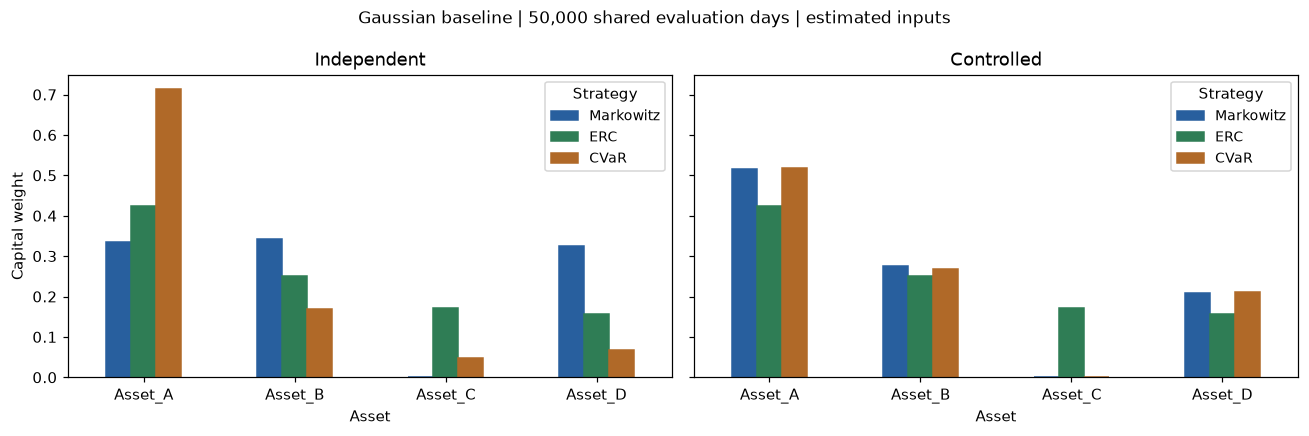

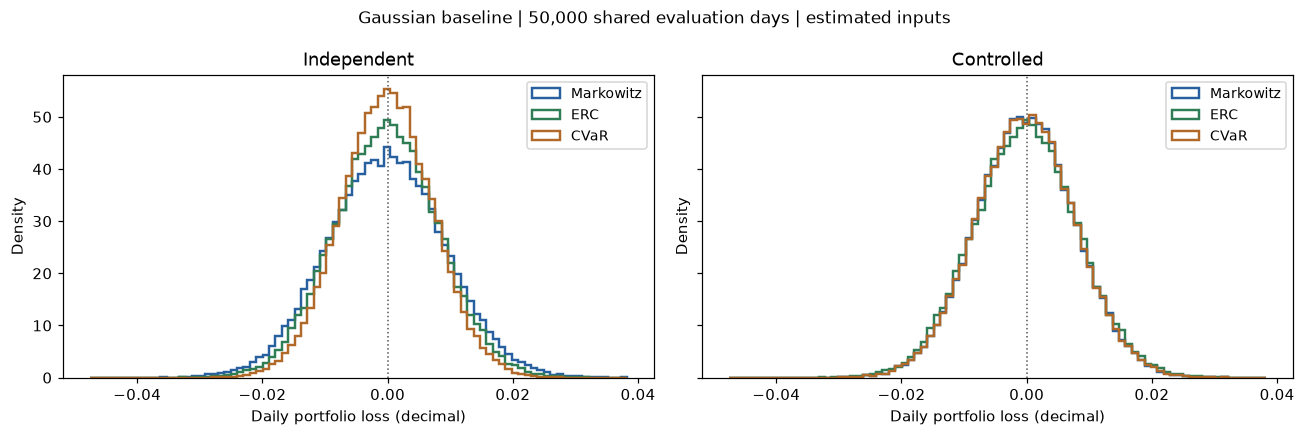

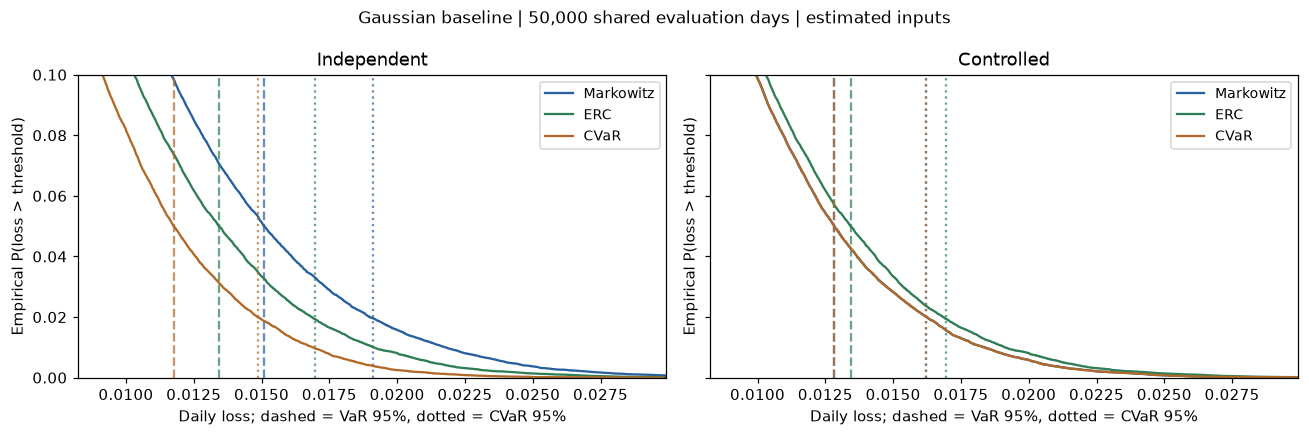

In [396]:
# 67.10. Check labels, legend placement and axis ranges for readability.
for ax in [*ax_losses, *ax_tail]:
    ax.legend(fontsize=9)
for fig in figures.values():
    display(fig)

#### Subtask 67.11 — Save figures with the run identifier and current information-regime label

We save figures with the run identifier and current information-regime label.

In [397]:
# 67.11. Save figures with the run identifier and current information-regime label.
run_id = config["name"] + "_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
run_dir = Path(config["output_root"]).resolve() / run_id
(run_dir / "figures").mkdir(parents=True, exist_ok=False)
for name, fig in figures.items():
    fig.savefig(run_dir / "figures" / f"{name}.png", bbox_inches="tight")
print("Figures saved in:", run_dir / "figures")

Figures saved in: /Users/morty/Documents/ChatGPT/Thesis Under Prof. Rubtsov/notebooks/milestone4_results/milestone4_gaussian_20261120T132115293121Z/figures


### Task 68 — Save results and run final numerical validation

Milestone 4 ends with persisted evidence and independent checks. For Gaussian portfolio losses, $VaR_\alpha=-\mu_p+\sigma_p z_\alpha$ and $CVaR_\alpha=-\mu_p+\sigma_p\phi(z_\alpha)/(1-\alpha)$. Additional fixed-weight simulations estimate sampling uncertainty; they do not re-fit portfolios or perform the later milestone's robustness experiments. A fresh Python process rebuilds the baseline using only configuration and function source.

#### Subtask 68.1 — Create a Stage 1 output location for the current run identifier

We create a Stage 1 output location for the current run identifier.

In [398]:
# 68.1. Create a Stage 1 output location for the current run identifier.
check("unique run output directory exists", run_dir.is_dir())
write_json(run_dir / "manifest.json", {"status": "in_progress", "milestone": 4, "run_id": run_id})

#### Subtask 68.2 — Save the complete configuration and return-unit conventions

We save the complete configuration and return-unit conventions.

In [399]:
# 68.2. Save the complete configuration and return-unit conventions.
write_json(run_dir / "resolved_config.json", config)
write_json(run_dir / "comparison_metadata.json", comparison_metadata)

#### Subtask 68.3 — Save asset ordering, mu_true, sigma_true, corr_true and cov_true

We save asset ordering, mu_true, sigma_true, corr_true and cov_true.

In [400]:
# 68.3. Save asset ordering, mu_true, sigma_true, corr_true and cov_true.
np.savez_compressed(
    run_dir / "population_parameters.npz",
    mu_true=mu_true,
    sigma_true=sigma_true,
    corr_true=corr_true,
    cov_true=cov_true,
)
write_json(run_dir / "asset_order.json", asset_names)

#### Subtask 68.4 — Save the information regime and actual optimization inputs or their file references

We save the information regime and actual optimization inputs or their file references.

In [401]:
# 68.4. Save the information regime and actual optimization inputs or their file references.
np.savez_compressed(
    run_dir / "fitting_inputs.npz",
    history=R_train,
    mu_opt=mu_opt,
    cov_opt=cov_opt,
    optimization_scenarios=R_opt,
)

#### Subtask 68.5 — Save random-stream identifiers and relevant dependency versions

We save random-stream identifiers and relevant dependency versions.

In [402]:
# 68.5. Save random-stream identifiers and relevant dependency versions.
versions = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "scipy": scipy.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
}
write_json(run_dir / "seeds.json", seed_metadata)
write_json(run_dir / "environment.json", versions)

#### Subtask 68.6 — Save validated weights, raw solver statuses and feasibility diagnostics

We save validated weights, raw solver statuses and feasibility diagnostics.

In [403]:
# 68.6. Save validated weights, raw solver statuses and feasibility diagnostics.
weights_table.to_csv(run_dir / "weights.csv", float_format="%.17g")
solver_records = {
    "Markowitz": markowitz_diagnostics,
    "ERC": {"success": True, "share_error": erc_max_share_error, "iterations": erc_result.nit},
    "CVaR": cvar_diagnostics,
    "controlled_Markowitz": {
        "success": bool(controlled_markowitz.success),
        "objective": float(controlled_markowitz.original_objective),
        "residuals": weight_residuals(controlled_markowitz.x, mu_opt, controlled_target),
    },
    "controlled_CVaR": {
        "success": bool(controlled_cvar.success),
        "objective": float(controlled_cvar.fun),
        "residuals": weight_residuals(controlled_cvar.x[:n_assets], mu_opt, controlled_target),
    },
}
write_json(run_dir / "optimizer_diagnostics.json", solver_records)

#### Subtask 68.7 — Save the comparison tables, thresholds, uncertainty summaries and figure paths

We save the comparison tables, thresholds, uncertainty summaries and figure paths.

In [404]:
# 68.7. Save the comparison tables, thresholds, uncertainty summaries and figure paths.
for name, table in {
    "comparison": comparison,
    "fit_objectives": fit_objectives,
    "means": mean_table,
    "volatilities": volatility_table,
    "VaR": var_table,
    "CVaR": cvar_table,
    "exceedances": exceedance_table,
    "concentration": concentration_table,
    "training_mean_diagnostics": mean_diagnostics,
    "training_covariance_diagnostics": cov_diagnostics,
}.items():
    table.to_csv(run_dir / f"{name}.csv", float_format="%.17g")
np.save(run_dir / "training_thresholds.npy", training_thresholds)

#### Subtask 68.8 — Save sample hashes or scenario artifacts sufficient for reproducibility

We save sample hashes or scenario artifacts sufficient for reproducibility.

In [405]:
# 68.8. Save sample hashes or scenario artifacts sufficient for reproducibility.
np.savez_compressed(
    run_dir / "evaluation.npz", asset_returns=R_eval, portfolio_returns=P_eval, weights=W
)
write_json(
    run_dir / "array_hashes.json",
    {
        "history": array_hash(R_train),
        "optimization": array_hash(R_opt),
        "evaluation": array_hash(R_eval),
        "weights": array_hash(W),
    },
)

#### Subtask 68.9 — For each fixed portfolio, calculate true mean mu_p and volatility sigma_p

This step handles a conditional case: For each fixed portfolio, calculate true mean mu_p and volatility sigma_p.

In [406]:
# 68.9. For each fixed portfolio, calculate true mean mu_p and volatility sigma_p.
analytic_mu = W.T @ mu_true
analytic_sigma = np.sqrt(np.maximum(np.einsum("ij,ik,kj->j", W, cov_true, W), 0))

#### Subtask 68.10 — For each confidence alpha, calculate the standard normal quantile z_alpha

This step handles a conditional case: For each confidence alpha, calculate the standard normal quantile z_alpha.

In [407]:
# 68.10. For each confidence alpha, calculate the standard normal quantile z_alpha.
z_alpha = stats.norm.ppf(reporting_alphas)

#### Subtask 68.11 — For positive sigma_p, calculate Gaussian VaR = -mu_p + sigma_p * z_alpha

This step handles a conditional case: For positive sigma_p, calculate Gaussian VaR = -mu_p + sigma_p * z_alpha.

In [408]:
# 68.11. For positive sigma_p, calculate Gaussian VaR = -mu_p + sigma_p * z_alpha.
analytic_var = -analytic_mu[:, None] + analytic_sigma[:, None] * z_alpha[None, :]

#### Subtask 68.12 — Calculate Gaussian CVaR = -mu_p + sigma_p * phi(z_alpha) / (1 - alpha)

We calculate Gaussian CVaR = -mu_p + sigma_p * phi(z_alpha) / (1 - alpha).

In [409]:
# 68.12. Calculate Gaussian CVaR = -mu_p + sigma_p * phi(z_alpha) / (1 - alpha).
# phi is the standard normal probability density function.
analytic_cvar = (
    -analytic_mu[:, None]
    + analytic_sigma[:, None] * stats.norm.pdf(z_alpha)[None, :] / (1 - reporting_alphas)[None, :]
)

#### Subtask 68.13 — For zero sigma_p, set both theoretical tail measures to the constant loss -mu_p

This step handles a conditional case: For zero sigma_p, set both theoretical tail measures to the constant loss -mu_p.

In [410]:
# 68.13. For zero sigma_p, set both theoretical tail measures to the constant loss -mu_p.
check("constant-loss analytical tail special case", near(-0.01 + 0 * z_alpha, -0.01))

#### Subtask 68.14 — Compare empirical VaR and CVaR with these analytical benchmarks

We compare empirical VaR and CVaR with these analytical benchmarks.

In [411]:
# 68.14. Compare empirical VaR and CVaR with these analytical benchmarks.
analytic_tail_table = pd.DataFrame(
    [
        {
            "mode": mode,
            "strategy": strategy,
            "alpha": a,
            "empirical_VaR": var_eval[j, k],
            "Gaussian_VaR": analytic_var[j, k],
            "empirical_CVaR": cvar_eval[j, k],
            "Gaussian_CVaR": analytic_cvar[j, k],
        }
        for j, (mode, strategy) in enumerate(portfolio_labels)
        for k, a in enumerate(reporting_alphas)
    ]
)
show(analytic_tail_table)

,mode,strategy,alpha,empirical_VaR,Gaussian_VaR,empirical_CVaR,Gaussian_CVaR
0,independent,Markowitz,0.95,0.0150972,0.0149846,0.0191283,0.0188756
1,independent,Markowitz,0.99,0.0217929,0.0213304,0.0249414,0.0244858
2,independent,ERC,0.95,0.0134352,0.0132995,0.0169608,0.0167559
3,independent,ERC,0.99,0.0191265,0.0189366,0.0221006,0.0217395
4,independent,CVaR,0.95,0.0117643,0.0117207,0.0148750,0.0147611
5,independent,CVaR,0.99,0.0168931,0.0166793,0.0191788,0.0191448
6,controlled,Markowitz,0.95,0.0128279,0.0127283,0.0162197,0.0160356
7,controlled,Markowitz,0.99,0.0183761,0.0181222,0.0210483,0.0208043
8,controlled,ERC,0.95,0.0134352,0.0132995,0.0169608,0.0167559
9,controlled,ERC,0.99,0.0191265,0.0189366,0.0221006,0.0217395


#### Subtask 68.15 — Use prespecified independent diagnostic batches to estimate tail sampling error

Thirty independent batches, each the same size as the evaluation sample, estimate the sampling variability of VaR and CVaR for fixed weights. No training observations or portfolio decisions are changed.

In [412]:
# 68.15. Use prespecified independent diagnostic batches to estimate tail sampling error.
B = config["diagnostic_batches"]
batch_var, batch_cvar = [], []
for b in range(B):
    # These are additional validation samples, not re-fitting or model sensitivity runs.
    batch_rng = rng_for(master_seed, stream_ids["diagnostics"], replication=b)
    batch_returns = batch_rng.standard_normal((n_eval, n_assets)) @ A.T + mu_true
    batch_losses = -(batch_returns @ W)
    v = np.quantile(batch_losses, reporting_alphas, axis=0, method="inverted_cdf").T
    c = np.array(
        [[tail_average(batch_losses[:, j], a) for a in reporting_alphas] for j in range(W.shape[1])]
    )
    batch_var.append(v)
    batch_cvar.append(c)
batch_var, batch_cvar = np.asarray(batch_var), np.asarray(batch_cvar)

#### Subtask 68.16 — Keep weights fixed while generating these batches from reserved diagnostic streams

We keep weights fixed while generating these batches from reserved diagnostic streams.

In [413]:
# 68.16. Keep weights fixed while generating these batches from reserved diagnostic streams.
check("diagnostics did not change fitted weights", array_hash(W) == weights_hash_before_evaluation)

#### Subtask 68.17 — Record uncertainty-scaled discrepancies instead of demanding exact agreement

Across-batch standard deviation estimates the uncertainty of one evaluation sample. Dividing it by the square root of the number of batches would instead estimate uncertainty of the batch average and would give the wrong tolerance here. These normal bands are diagnostic approximations, not exact simultaneous confidence guarantees.

In [414]:
# 68.17. Record uncertainty-scaled discrepancies instead of demanding exact agreement.
# Use across-batch SD for uncertainty of ONE evaluation estimate, not SD/sqrt(B).
tail_se_var, tail_se_cvar = batch_var.std(axis=0, ddof=1), batch_cvar.std(axis=0, ddof=1)
tail_critical = stats.norm.ppf(1 - family_error / (2 * 2 * analytic_var.size))
var_z_error = np.divide(
    var_eval - analytic_var, tail_se_var, out=np.zeros_like(var_eval), where=tail_se_var > 0
)
cvar_z_error = np.divide(
    cvar_eval - analytic_cvar, tail_se_cvar, out=np.zeros_like(cvar_eval), where=tail_se_cvar > 0
)
tail_flags = (np.abs(var_z_error) > tail_critical) | (np.abs(cvar_z_error) > tail_critical)
statistical_flags.append(
    {"diagnostic": "Gaussian tail benchmarks", "flagged": int(tail_flags.sum())}
)
analytic_tail_table["VaR_sampling_SD"] = tail_se_var.ravel()
analytic_tail_table["CVaR_sampling_SD"] = tail_se_cvar.ravel()
analytic_tail_table["VaR_z_error"] = var_z_error.ravel()
analytic_tail_table["CVaR_z_error"] = cvar_z_error.ravel()
show(analytic_tail_table)

,mode,strategy,alpha,empirical_VaR,Gaussian_VaR,empirical_CVaR,Gaussian_CVaR,VaR_sampling_SD,CVaR_sampling_SD,VaR_z_error,CVaR_z_error
0,independent,Markowitz,0.95,0.0150972,0.0149846,0.0191283,0.0188756,0.0000890,0.0001128,1.2650514,2.2407672
1,independent,Markowitz,0.99,0.0217929,0.0213304,0.0249414,0.0244858,0.0001887,0.0001999,2.4510415,2.2795796
2,independent,ERC,0.95,0.0134352,0.0132995,0.0169608,0.0167559,0.0001004,0.0001133,1.3510875,1.8088802
3,independent,ERC,0.99,0.0191265,0.0189366,0.0221006,0.0217395,0.0001579,0.0001818,1.2033515,1.9859796
4,independent,CVaR,0.95,0.0117643,0.0117207,0.0148750,0.0147611,0.0000744,0.0001022,0.5848273,1.1144732
5,independent,CVaR,0.99,0.0168931,0.0166793,0.0191788,0.0191448,0.0001702,0.0001622,1.2566502,0.2095847
6,controlled,Markowitz,0.95,0.0128279,0.0127283,0.0162197,0.0160356,0.0000892,0.0001016,1.1169977,1.8116712
7,controlled,Markowitz,0.99,0.0183761,0.0181222,0.0210483,0.0208043,0.0001466,0.0001504,1.7314893,1.6224826
8,controlled,ERC,0.95,0.0134352,0.0132995,0.0169608,0.0167559,0.0001004,0.0001133,1.3510875,1.8088802
9,controlled,ERC,0.99,0.0191265,0.0189366,0.0221006,0.0217395,0.0001579,0.0001818,1.2033515,1.9859796


#### Subtask 68.18 — Repeat moment diagnostics at prespecified sample sizes using diagnostic streams

This is the source document's Gaussian moment-recovery validation at three sample sizes. It is not a GARCH, copula, empirical or strategy-sensitivity milestone.

In [415]:
# 68.18. Repeat moment diagnostics at prespecified sample sizes using diagnostic streams.
convergence_rows = []
for N in config["diagnostic_sizes"]:
    mean_squared_errors, cov_squared_errors = [], []
    for b in range(B):
        # Recreate each stream so increasing N uses nested prefixes within a batch.
        rr = (
            rng_for(master_seed, stream_ids["convergence"], replication=b).standard_normal(
                (N, n_assets)
            )
            @ A.T
            + mu_true
        )
        mean_squared_errors.append(np.mean((rr.mean(axis=0) - mu_true) ** 2))
        cov_squared_errors.append(np.mean((np.cov(rr, rowvar=False, ddof=1) - cov_true) ** 2))
    convergence_rows.append(
        {
            "N": N,
            "mean_RMSE": np.sqrt(np.mean(mean_squared_errors)),
            "expected_mean_RMSE": np.sqrt(np.mean(np.diag(cov_true)) / N),
            "covariance_RMSE": np.sqrt(np.mean(cov_squared_errors)),
        }
    )
convergence_table = pd.DataFrame(convergence_rows)
show(convergence_table)

,N,mean_RMSE,expected_mean_RMSE,covariance_RMSE
0,1000,0.0004506,0.0004648,0.0000077
1,4000,0.0002295,0.0002324,0.0000044
2,16000,0.0001167,0.0001162,0.0000025


#### Subtask 68.19 — Check convergence in aggregate without requiring every error to decrease each time

We check convergence in aggregate without requiring every error to decrease each time.

In [416]:
# 68.19. Check convergence in aggregate without requiring every error to decrease each time.
convergence_table["mean_RMSE_times_sqrt_N"] = convergence_table["mean_RMSE"] * np.sqrt(
    convergence_table["N"]
)
print("Inspect the aggregate RMSE scale; individual random errors need not decrease monotonically.")
show(convergence_table)

Inspect the aggregate RMSE scale; individual random errors need not decrease monotonically.


,N,mean_RMSE,expected_mean_RMSE,covariance_RMSE,mean_RMSE_times_sqrt_N
0,1000,0.0004506,0.0004648,0.0000077,0.0142482
1,4000,0.0002295,0.0002324,0.0000044,0.0145142
2,16000,0.0001167,0.0001162,0.0000025,0.0147586


#### Subtask 68.20 — Run the matrix reconstruction and ERC contribution-sum identity checks

We run the matrix reconstruction and ERC contribution-sum identity checks.

In [417]:
# 68.20. Run the matrix reconstruction and ERC contribution-sum identity checks.
check("final covariance reconstruction", near(A @ A.T, cov_true))
check("final ERC Euler identity", near(erc_RC.sum(), erc_sigma))
check(
    "singular PSD factorization backstop",
    near(psd_factor(np.ones((2, 2))) @ psd_factor(np.ones((2, 2))).T, np.ones((2, 2))),
)
# A materially indefinite covariance must fail rather than be silently repaired.
try:
    psd_factor(np.array([[1.0, 2.0], [2.0, 1.0]]))
except ValueError:
    check("indefinite covariance rejected", True)
else:
    check("indefinite covariance rejected", False)

#### Subtask 68.21 — Run the declared constraint and finite-scenario CVaR identity checks

We run the declared constraint and finite-scenario CVaR identity checks.

In [418]:
# 68.21. Run the declared constraint and finite-scenario CVaR identity checks.
for j, label in enumerate(portfolio_labels):
    target = controlled_target if label[0] == "controlled" else None
    check(
        f"final feasible allocation {label}",
        max(weight_residuals(W[:, j], mu_opt, target).values()) <= feasibility_tol,
    )
check(
    "controlled CVaR scenario identity",
    near(
        controlled_cvar.fun,
        tail_average(portfolio_losses(R_opt, controlled_weights[2]), alpha_opt),
        atol=1e-8,
    ),
)
# Analytical allocations provide independent numerical backstops.
markowitz_hand = solve_markowitz(np.zeros(2), np.diag([1.0, 4.0]), gamma=2.0).x
check("Markowitz inverse-variance backstop", near(markowitz_hand, [0.8, 0.2], atol=1e-7))
cvar_hand = solve_cvar_lp(np.array([[-0.1, 0.1], [0.1, -0.1]]), 0.5).x[:2]
check("CVaR complementary-loss backstop", near(cvar_hand, [0.5, 0.5], atol=1e-7))

#### Subtask 68.22 — Reload saved tables and weights and compare them with in-memory values

We reload saved tables and weights and compare them with in-memory values.

In [419]:
# 68.22. Reload saved tables and weights and compare them with in-memory values.
reloaded_weights = pd.read_csv(run_dir / "weights.csv", header=[0, 1], index_col=0)
reloaded_comparison = pd.read_csv(run_dir / "comparison.csv", index_col=[0, 1])
check("saved weights reload faithfully", near(reloaded_weights.to_numpy(), W, atol=1e-14))
check(
    "saved comparison reloads faithfully",
    near(
        reloaded_comparison.select_dtypes(include="number").to_numpy(),
        comparison.select_dtypes(include="number").to_numpy(),
        atol=1e-14,
    ),
)
check(
    "saved configuration reloads faithfully",
    json.loads((run_dir / "resolved_config.json").read_text()) == config,
)

#### Subtask 68.23 — Reproduce the run from recorded settings in a clean execution state

A new interpreter receives source definitions and the configuration, but none of this kernel's arrays or fitted weights. It regenerates all three random streams, fits all portfolios and recomputes evaluation metrics. The standalone reproduction script is also saved with the run.

In [420]:
# 68.23. Reproduce the run from recorded settings in a clean execution state.
def replay_core(cfg):
    # Rebuild the whole numerical baseline from config, without notebook arrays.
    market = cfg["market"]
    mu = np.asarray(market["mean"])
    sigma = np.asarray(market["volatility"])
    cov = np.diag(sigma) @ np.asarray(market["correlation"]) @ np.diag(sigma)
    factor = psd_factor(cov)
    seed = cfg["seed"]
    n = len(mu)
    history = rng_for(seed, 0).standard_normal((cfg["history_observations"], n)) @ factor.T + mu
    mu_fit = history.mean(axis=0)
    cov_fit = np.cov(history, rowvar=False, ddof=1)
    # Fitted-model scenarios and true evaluation paths use distinct stream identities.
    scenarios = (
        rng_for(seed, 1).standard_normal((cfg["optimization_scenarios"], n)) @ psd_factor(cov_fit).T
        + mu_fit
    )
    evaluation = (
        rng_for(seed, 2).standard_normal((cfg["evaluation_observations"], n)) @ factor.T + mu
    )
    erc = solve_erc(cov_fit).x
    target = float(mu_fit @ erc)
    mw = solve_markowitz(mu_fit, cov_fit, cfg["risk_aversion"]).x
    cv = solve_cvar_lp(scenarios, cfg["confidence"]).x[:n]
    cmw = solve_markowitz(mu_fit, cov_fit, cfg["risk_aversion"], target).x
    ccv = solve_cvar_lp(scenarios, cfg["confidence"], mu_fit, target).x[:n]
    weights = np.column_stack([mw, erc, cv, cmw, erc, ccv])
    # Recompute risk, frozen thresholds and concentration from regenerated arrays.
    portfolio = evaluation @ weights
    losses = -portfolio
    alphas = np.asarray(cfg["reporting_confidences"])
    var = np.quantile(losses, alphas, axis=0, method="inverted_cdf").T
    cvar = np.array(
        [[tail_average(losses[:, j], a) for a in alphas] for j in range(weights.shape[1])]
    )
    thresholds = np.quantile(-history @ weights, alphas, axis=0, method="inverted_cdf").T
    rates = (losses[:, :, None] > thresholds[None, :, :]).mean(axis=0)
    return dict(
        history=history,
        scenarios=scenarios,
        evaluation=evaluation,
        weights=weights,
        portfolio_returns=portfolio,
        mean=portfolio.mean(axis=0),
        volatility=portfolio.std(axis=0, ddof=1),
        var=var,
        cvar=cvar,
        thresholds=thresholds,
        rates=rates,
        HHI=np.square(weights).sum(axis=0),
    )


# Transfer only function SOURCE and configuration to a new Python interpreter.
replay_functions = [
    rng_for,
    psd_factor,
    solve_markowitz,
    erc_objective,
    solve_erc,
    cvar_problem,
    solve_cvar_lp,
    tail_average,
    replay_core,
]
replay_source = "import numpy as np\nimport json\nfrom scipy import sparse\nfrom scipy.optimize import minimize, linprog, OptimizeResult\n"
replay_source += "\n\n".join(inspect.getsource(f) for f in replay_functions)
replay_source += "\nconfig=json.loads(" + repr(json.dumps(config)) + ")\n"
with tempfile.TemporaryDirectory(prefix="milestone4_replay_") as replay_tmp:
    replay_file = Path(replay_tmp) / "replay.npz"
    script = (
        replay_source
        + "\nnp.savez_compressed("
        + repr(str(replay_file))
        + ",**replay_core(config))\n"
    )
    completed = subprocess.run(
        [sys.executable, "-c", script], capture_output=True, text=True, timeout=180
    )
    check("fresh-process replay executes", completed.returncode == 0, completed.stderr[-2000:])
    with np.load(replay_file, allow_pickle=False) as replay_data:
        replay_arrays = {k: replay_data[k].copy() for k in replay_data.files}
(run_dir / "reproduce_baseline.py").write_text(
    replay_source + "\nnp.savez_compressed('replayed_baseline.npz',**replay_core(config))\n"
)

Out[420]: 11458


#### Subtask 68.24 — Compare reproduced artifacts within declared deterministic numerical tolerances

We compare reproduced artifacts within declared deterministic numerical tolerances.

In [421]:
# 68.24. Compare reproduced artifacts within declared deterministic numerical tolerances.
reference_arrays = {
    "history": R_train,
    "scenarios": R_opt,
    "evaluation": R_eval,
    "weights": W,
    "portfolio_returns": P_eval,
    "mean": mean_eval,
    "volatility": volatility_eval,
    "var": var_eval,
    "cvar": cvar_eval,
    "thresholds": training_thresholds,
    "rates": exceedance_rates,
    "HHI": herfindahl,
}
replay_report = []
for name, reference in reference_arrays.items():
    error = float(np.max(np.abs(replay_arrays[name] - reference)))
    passed = near(replay_arrays[name], reference, atol=1e-9, rtol=1e-7)
    check("fresh-process reproduction " + name, passed, error)
    replay_report.append({"array": name, "maximum_absolute_error": error, "passed": passed})
show(pd.DataFrame(replay_report))

,array,maximum_absolute_error,passed
0,history,0.0,True
1,scenarios,0.0,True
2,evaluation,0.0,True
3,weights,0.0,True
4,portfolio_returns,0.0,True
5,mean,0.0,True
6,volatility,0.0,True
7,var,0.0,True
8,cvar,0.0,True
9,thresholds,0.0,True


#### Subtask 68.25 — Save one validation report listing passes, statistical flags and unresolved failures

We save one validation report listing passes, statistical flags and unresolved failures.

In [422]:
# 68.25. Save one validation report listing passes, statistical flags and unresolved failures.
validation_report = {
    "milestone": 4,
    "deterministic_checks": checks,
    "statistical_diagnostics": statistical_flags,
    "replay": replay_report,
    "statistical_note": "Sampling-error flags require interpretation; they are not deterministic test failures.",
}
write_json(run_dir / "validation_report.json", validation_report)
analytic_tail_table.to_csv(
    run_dir / "analytical_tail_checks.csv", index=False, float_format="%.17g"
)
convergence_table.to_csv(run_dir / "moment_convergence.csv", index=False, float_format="%.17g")
np.savez_compressed(run_dir / "diagnostic_tail_batches.npz", var=batch_var, cvar=batch_cvar)

#### Subtask 68.26 — Mark Milestone 4 complete only when three valid portfolios and baseline outputs exist

Completion here means the Milestone 4 computation and its evidence are complete. Sampling flags remain visible, and this single synthetic experiment does not establish the thesis's final conclusions.

In [423]:
# 68.26. Mark Milestone 4 complete only when three valid portfolios and baseline outputs exist.
all_deterministic_pass = all(item["passed"] for item in checks)
flag_count = sum(item["flagged"] for item in statistical_flags)
check(
    "Milestone 4 computational outputs complete",
    all_deterministic_pass and len(portfolio_labels) == 6 and (run_dir / "comparison.csv").exists(),
)
# A completed computational run is distinct from approved final research conclusions.
status = "completed" if flag_count == 0 else "completed_with_statistical_flags"
artifact_hashes = {
    str(p.relative_to(run_dir)): hashlib.sha256(p.read_bytes()).hexdigest()
    for p in run_dir.rglob("*")
    if p.is_file() and p.name != "manifest.json"
}
write_json(
    run_dir / "manifest.json",
    {
        "status": status,
        "milestone": 4,
        "run_id": run_id,
        "deterministic_checks": len(checks),
        "statistical_flags": flag_count,
        "portfolios": len(portfolio_labels),
        "artifacts": artifact_hashes,
        "units": "daily decimal returns",
    },
)
# Include the completion assertion in the final report and refresh its manifest hash.
validation_report["deterministic_checks"] = checks
write_json(run_dir / "validation_report.json", validation_report)
manifest = json.loads((run_dir / "manifest.json").read_text())
manifest["artifacts"]["validation_report.json"] = hashlib.sha256(
    (run_dir / "validation_report.json").read_bytes()
).hexdigest()
write_json(run_dir / "manifest.json", manifest)
display(
    Markdown(
        f"**Core checkpoint saved; added checks and visual exports continue below.** {len(checks)} deterministic checks passed; {flag_count} sampling-error flags were recorded. Six portfolios represent three strategies in each of two comparison modes. Results are saved to `{run_dir}`."
    )
)

**Core checkpoint saved; added checks and visual exports continue below.** 179 deterministic checks passed; 0 sampling-error flags were recorded. Six portfolios represent three strategies in each of two comparison modes. Results are saved to `/Users/morty/Documents/ChatGPT/Thesis Under Prof. Rubtsov/notebooks/milestone4_results/milestone4_gaussian_20261120T132115293121Z`.

## Interpretation and limits of the completed baseline

The notebook reports the observed allocations and risk measures, verifies analytical identities, and distinguishes deterministic failures from sampling uncertainty. The controlled comparison holds fitted expected return constant; it does not force realized returns to agree. Equal capital weights, equal volatility contributions and equal tail-risk contributions are different concepts.

These results concern one synthetic Gaussian population and one historical fit. Conditional evaluation intervals and fixed-weight diagnostic batches do not capture uncertainty from new training histories. Constant covariance, normally distributed simple returns, zero costs and daily restoration of fixed weights are simplifying assumptions. The notebook records these limits without claiming a universal best strategy. Dynamic volatility, copulas, historical-market experiments and broad robustness analysis remain outside this milestone.

The output directory contains the complete configuration, arrays, six-portfolio comparison, training thresholds, uncertainty diagnostics, figures, solver diagnostics, validation report, checksums and a standalone `reproduce_baseline.py` script. Rerunning this notebook creates a fresh run directory and should reproduce scientific values within the declared tolerances.

<a id="part-g"></a>

## Part G — Explicit sanity checks

### Task 69 — Verify reproducibility with fixed seeds

Backstop: identical configuration, seed and environment must reproduce identical draws. Numerical solver replay uses the declared floating-point tolerances from Task 68.

#### Subtask 69.1 — Record the seed and reserve a stream for the reproducibility check

Record the seed and reserve a stream for the reproducibility check.

In [424]:
# 69.1. Record the seed and reserve a stream for the reproducibility check.
repro_seed, repro_stream = master_seed, 901
print({'seed': repro_seed, 'stream': repro_stream})

{'seed': 20261030, 'stream': 901}


#### Subtask 69.2 — Generate a small Gaussian sample from a newly initialized generator

Generate a small Gaussian sample from a newly initialized generator.

In [425]:
# 69.2. Generate a small Gaussian sample from a newly initialized generator.
repro_first = rng_for(repro_seed, repro_stream).standard_normal((1000, n_assets)) @ A.T + mu_true

#### Subtask 69.3 — Reinitialize the same generator and regenerate every observation

Reinitialize the same generator and regenerate every observation.

In [426]:
# 69.3. Reinitialize the same generator and regenerate every observation.
repro_second = rng_for(repro_seed, repro_stream).standard_normal((1000, n_assets)) @ A.T + mu_true

#### Subtask 69.4 — Assert exact equality and display the maximum absolute discrepancy

Assert exact equality and display the maximum absolute discrepancy.

In [427]:
# 69.4. Assert exact equality and display the maximum absolute discrepancy.
check('69 identical seeded samples', np.array_equal(repro_first, repro_second))
print('Maximum draw discrepancy:', np.max(np.abs(repro_first-repro_second)))

Maximum draw discrepancy: 0.0


#### Subtask 69.5 — Display the clean-process replay results and assert that every array passed

Display the clean-process replay results and assert that every array passed.

In [428]:
# 69.5. Display the clean-process replay results and assert that every array passed.
show(pd.DataFrame(replay_report))
check('69 complete baseline replay', all(row['passed'] for row in replay_report))

,array,maximum_absolute_error,passed
0,history,0.0,True
1,scenarios,0.0,True
2,evaluation,0.0,True
3,weights,0.0,True
4,portfolio_returns,0.0,True
5,mean,0.0,True
6,volatility,0.0,True
7,var,0.0,True
8,cvar,0.0,True
9,thresholds,0.0,True


### Task 70 — Check an analytically known portfolio variance

Backstop: two independent assets with variance $s^2$ and weights $(1/2,1/2)$ have $w^T\Sigma w=s^2/2$. Use absolute tolerance $10^{-12}$ and relative tolerance $10^{-10}$.

#### Subtask 70.1 — Set equal weights for two independent assets with equal variance

Set equal weights for two independent assets with equal variance.

In [429]:
# 70.1. Set equal weights for two independent assets with equal variance.
known_weights = np.array([0.5, 0.5])
known_asset_variance = 0.02**2

#### Subtask 70.2 — Construct the diagonal covariance matrix without cross covariance

Construct the diagonal covariance matrix without cross covariance.

In [430]:
# 70.2. Construct the diagonal covariance matrix without cross covariance.
known_covariance = np.eye(2) * known_asset_variance

#### Subtask 70.3 — Calculate portfolio variance through the production helper

Calculate portfolio variance through the production helper.

In [431]:
# 70.3. Calculate portfolio variance through the production helper.
known_result = portfolio_variance(known_weights, known_covariance)

#### Subtask 70.4 — Compare the computed variance with half the individual asset variance

Compare the computed variance with half the individual asset variance.

In [432]:
# 70.4. Compare the computed variance with half the individual asset variance.
known_expected = known_asset_variance / 2
check('70 equal independent variance', near(known_result, known_expected, atol=1e-12, rtol=1e-10))

#### Subtask 70.5 — Display the expected variance, computed variance and absolute error

Display the expected variance, computed variance and absolute error.

In [433]:
# 70.5. Display the expected variance, computed variance and absolute error.
show(pd.Series({'expected': known_expected, 'computed': known_result, 'absolute_error': abs(known_result-known_expected)}))

expected          0.0002
computed          0.0002
absolute_error    0.0000
dtype: float64

### Task 71 — Reject invalid portfolio inputs explicitly

Backstop: reject incompatible covariance dimensions, non-finite scenario returns and weights outside the long-only unit simplex. Each negative test must raise an informative ValueError.

#### Subtask 71.1 — Define a helper that records the expected validation error and fails if none occurs

Define a helper that records the expected validation error and fails if none occurs.

In [434]:
# 71.1. Define a helper that records the expected validation error and fails if none occurs.
def expect_value_error(name, operation):
    # Only the intended validation exception counts as a successful negative test.
    try:
        operation()
    except ValueError as exc:
        check(name, bool(str(exc)), str(exc))
        print(name + ': PASS — ' + str(exc))
    else:
        check(name, False, 'Expected an informative ValueError')

#### Subtask 71.2 — Pass an incorrectly sized covariance matrix to the Markowitz solver

Pass an incorrectly sized covariance matrix to the Markowitz solver.

In [435]:
# 71.2. Pass an incorrectly sized covariance matrix to the Markowitz solver.
expect_value_error('71 covariance dimensions', lambda: solve_markowitz(np.zeros(2), np.eye(3)))

71 covariance dimensions: PASS — Invalid Markowitz input dimensions or values


#### Subtask 71.3 — Pass a scenario containing a non-finite return to the portfolio-loss function

Pass a scenario containing a non-finite return to the portfolio-loss function.

In [436]:
# 71.3. Pass a scenario containing a non-finite return to the portfolio-loss function.
expect_value_error('71 non-finite returns', lambda: portfolio_losses(np.array([[np.nan, 0.01]]), known_weights))

71 non-finite returns: PASS — Scenario returns and portfolio weights must be finite


#### Subtask 71.4 — Pass portfolio weights whose sum is different from one

Pass portfolio weights whose sum is different from one.

In [437]:
# 71.4. Pass portfolio weights whose sum is different from one.
expect_value_error('71 invalid weight budget', lambda: portfolio_losses(np.zeros((2, 2)), np.array([0.2, 0.2])))

71 invalid weight budget: PASS — Portfolio weights must be nonnegative and sum to one


#### Subtask 71.5 — Pass incompatible scenario and weight dimensions

Pass incompatible scenario and weight dimensions.

In [438]:
# 71.5. Pass incompatible scenario and weight dimensions.
expect_value_error('71 scenario dimensions', lambda: portfolio_losses(np.zeros((2, 3)), known_weights))

71 scenario dimensions: PASS — Scenario columns must match the one-dimensional weight vector


#### Subtask 71.6 — Verify that valid inputs still produce the manually calculated losses

Verify that valid inputs still produce the manually calculated losses.

In [439]:
# 71.6. Verify that valid inputs still produce the manually calculated losses.
check('71 valid inputs preserved', near(portfolio_losses(np.array([[-0.02, 0.01]]), known_weights), [0.005]))

### Task 72 — Report recovery of theoretical Gaussian moments

Statistical sanity: $SE(\hat\mu_i)=\sigma_i/\sqrt{N}$ and $SE(\hat\Sigma_{ij})=\sqrt{(\Sigma_{ij}^2+\Sigma_{ii}\Sigma_{jj})/(N-1)}$. Reuse prespecified family-adjusted diagnostic bands. A statistical FLAG prompts investigation; it is not automatically a mathematical failure or a reason to change seeds.

#### Subtask 72.1 — Display the sample means, theoretical means and sampling-error diagnostics

Display the sample means, theoretical means and sampling-error diagnostics.

In [440]:
# 72.1. Display the sample means, theoretical means and sampling-error diagnostics.
show(mean_diagnostics)

,true_mean,sample_mean,error,standard_error,z_error,within_band
Asset_A,0.0002,0.0002796,0.0000796,0.00008,0.9952331,True
Asset_B,0.0003,0.0004705,0.0001705,0.00012,1.4208953,True
Asset_C,0.0004,0.0004925,0.0000925,0.00016,0.5779190,True
Asset_D,0.0005,0.0008668,0.0003668,0.00020,1.8338823,True


#### Subtask 72.2 — Display covariance errors in standard-error units and their acceptance bands

Display covariance errors in standard-error units and their acceptance bands.

In [441]:
# 72.2. Display covariance errors in standard-error units and their acceptance bands.
show(cov_diagnostics)
print('Covariance absolute z-score threshold:', moment_critical)

Covariance absolute z-score threshold: 3.384036251864579


,i,j,error,SE,z_error,within_band
0,0,0,-0.0000003,0.0000009,-0.3545354,True
1,0,1,-0.0000010,0.0000010,-0.9505526,True
2,0,2,-0.0000012,0.0000013,-0.8920485,True
3,0,3,0.0000006,0.0000016,0.3570401,True
4,1,1,0.0000014,0.0000020,0.7095320,True
5,1,2,0.0000020,0.0000021,0.9552896,True
6,1,3,-0.0000006,0.0000024,-0.2612816,True
7,2,2,0.0000073,0.0000036,2.0220240,True
8,2,3,0.0000038,0.0000036,1.0753942,True
9,3,3,0.0000066,0.0000057,1.1596839,True


#### Subtask 72.3 — Display Fisher-transform correlation diagnostics and the correlation threshold

Display Fisher-transform correlation diagnostics and the correlation threshold.

In [442]:
# 72.3. Display Fisher-transform correlation diagnostics and the correlation threshold.
show(pd.DataFrame(fisher_rows))
print('Correlation absolute z-score threshold:', correlation_critical)

Correlation absolute z-score threshold: 3.143980287069073


,pair,z_error,within_band
0,Asset_A / Asset_B,-1.1653238,True
1,Asset_A / Asset_C,-1.1738195,True
2,Asset_A / Asset_D,0.3038639,True
3,Asset_B / Asset_C,0.3016317,True
4,Asset_B / Asset_D,-0.5449627,True
5,Asset_C / Asset_D,0.1021893,True


#### Subtask 72.4 — Summarize moment checks as PASS or FLAG using the existing uncertainty bands

Summarize moment checks as PASS or FLAG using the existing uncertainty bands.

In [443]:
# 72.4. Summarize moment checks as PASS or FLAG using the existing uncertainty bands.
moment_status = 'PASS' if np.all(mean_pass) and np.all(covariance_pass) and all(row['within_band'] for row in fisher_rows) else 'FLAG'
print('Gaussian moment recovery:', moment_status)

Gaussian moment recovery: PASS


#### Subtask 72.5 — Display aggregate moment convergence across reserved sample sizes

Display aggregate moment convergence across reserved sample sizes.

In [444]:
# 72.5. Display aggregate moment convergence across reserved sample sizes.
show(convergence_table)
print('Expected mean-error scale: 1/sqrt(N); individual errors need not decrease monotonically.')

Expected mean-error scale: 1/sqrt(N); individual errors need not decrease monotonically.


,N,mean_RMSE,expected_mean_RMSE,covariance_RMSE,mean_RMSE_times_sqrt_N
0,1000,0.0004506,0.0004648,0.0000077,0.0142482
1,4000,0.0002295,0.0002324,0.0000044,0.0145142
2,16000,0.0001167,0.0001162,0.0000025,0.0147586


### Task 73 — Verify equal risk contributions and their sum

Backstop: $RC_i=w_i(\hat\Sigma w)_i/\sigma_p$, $\sum_i RC_i=\sigma_p$, and $RC_i/\sigma_p=1/n$. Evaluate equality on the fitted covariance used by ERC; population and evaluation estimates need not give exactly equal shares.

#### Subtask 73.1 — Select the ERC weights and the covariance used in their optimization

Select the ERC weights and the covariance used in their optimization.

In [445]:
# 73.1. Select the ERC weights and the covariance used in their optimization.
erc_column = portfolio_labels.index(('independent', 'ERC'))
erc_check_w = W[:, erc_column]

#### Subtask 73.2 — Compute portfolio volatility from the fitted covariance matrix

Compute portfolio volatility from the fitted covariance matrix.

In [446]:
# 73.2. Compute portfolio volatility from the fitted covariance matrix.
erc_check_sigma = np.sqrt(erc_check_w @ cov_opt @ erc_check_w)

#### Subtask 73.3 — Compute individual volatility contributions and normalize them into risk shares

Compute individual volatility contributions and normalize them into risk shares.

In [447]:
# 73.3. Compute individual volatility contributions and normalize them into risk shares.
erc_check_rc = erc_check_w * (cov_opt @ erc_check_w) / erc_check_sigma
erc_check_shares = erc_check_rc / erc_check_sigma

#### Subtask 73.4 — Assert that contributions sum to total volatility within numerical tolerance

Assert that contributions sum to total volatility within numerical tolerance.

In [448]:
# 73.4. Assert that contributions sum to total volatility within numerical tolerance.
check('73 Euler risk decomposition', near(erc_check_rc.sum(), erc_check_sigma, atol=1e-12, rtol=1e-10))

#### Subtask 73.5 — Assert equal risk shares using the configured ERC share tolerance

Assert equal risk shares using the configured ERC share tolerance.

In [449]:
# 73.5. Assert equal risk shares using the configured ERC share tolerance.
check('73 equal risk shares', np.max(np.abs(erc_check_shares-1/n_assets)) <= config['erc_share_tol'])

#### Subtask 73.6 — Display capital weights, volatility contributions and risk shares together

Display capital weights, volatility contributions and risk shares together.

In [450]:
# 73.6. Display capital weights, volatility contributions and risk shares together.
erc_check_table = pd.DataFrame({'weight': erc_check_w, 'volatility_contribution': erc_check_rc, 'risk_share': erc_check_shares}, index=asset_names)
show(erc_check_table)

,weight,volatility_contribution,risk_share
Asset_A,0.4232541,0.0020745,0.25
Asset_B,0.2496223,0.0020745,0.25
Asset_C,0.1710745,0.0020745,0.25
Asset_D,0.1560491,0.0020745,0.25


### Task 74 — Report empirical versus analytical Gaussian tail risk

Backstop and intuition: $VaR_\alpha=-\mu_p+\sigma_p z_\alpha$ and $CVaR_\alpha=-\mu_p+\sigma_p\phi(z_\alpha)/(1-\alpha)$. The identities are deterministic; comparison to simulated estimates is statistical. Use the SD across independent equal-size batches for one evaluation estimate, not SD divided by the square root of batch count.

#### Subtask 74.1 — Display analytical and empirical VaR and CVaR for every strategy and confidence level

Display analytical and empirical VaR and CVaR for every strategy and confidence level.

In [451]:
# 74.1. Display analytical and empirical VaR and CVaR for every strategy and confidence level.
show(analytic_tail_table)

,mode,strategy,alpha,empirical_VaR,Gaussian_VaR,empirical_CVaR,Gaussian_CVaR,VaR_sampling_SD,CVaR_sampling_SD,VaR_z_error,CVaR_z_error
0,independent,Markowitz,0.95,0.0150972,0.0149846,0.0191283,0.0188756,0.0000890,0.0001128,1.2650514,2.2407672
1,independent,Markowitz,0.99,0.0217929,0.0213304,0.0249414,0.0244858,0.0001887,0.0001999,2.4510415,2.2795796
2,independent,ERC,0.95,0.0134352,0.0132995,0.0169608,0.0167559,0.0001004,0.0001133,1.3510875,1.8088802
3,independent,ERC,0.99,0.0191265,0.0189366,0.0221006,0.0217395,0.0001579,0.0001818,1.2033515,1.9859796
4,independent,CVaR,0.95,0.0117643,0.0117207,0.0148750,0.0147611,0.0000744,0.0001022,0.5848273,1.1144732
5,independent,CVaR,0.99,0.0168931,0.0166793,0.0191788,0.0191448,0.0001702,0.0001622,1.2566502,0.2095847
6,controlled,Markowitz,0.95,0.0128279,0.0127283,0.0162197,0.0160356,0.0000892,0.0001016,1.1169977,1.8116712
7,controlled,Markowitz,0.99,0.0183761,0.0181222,0.0210483,0.0208043,0.0001466,0.0001504,1.7314893,1.6224826
8,controlled,ERC,0.95,0.0134352,0.0132995,0.0169608,0.0167559,0.0001004,0.0001133,1.3510875,1.8088802
9,controlled,ERC,0.99,0.0191265,0.0189366,0.0221006,0.0217395,0.0001579,0.0001818,1.2033515,1.9859796


#### Subtask 74.2 — Record the batch count, evaluation size and approximate family-adjusted threshold

Record the batch count, evaluation size and approximate family-adjusted threshold.

In [452]:
# 74.2. Record the batch count, evaluation size and approximate family-adjusted threshold.
print({'independent_batches': B, 'observations_per_batch': n_eval, 'absolute_z_threshold': tail_critical})

{'independent_batches': 30, 'observations_per_batch': 50000, 'absolute_z_threshold': np.float64(3.5292960888347347)}


#### Subtask 74.3 — Assign separate PASS or FLAG outcomes to VaR and CVaR discrepancies

Assign separate PASS or FLAG outcomes to VaR and CVaR discrepancies.

In [453]:
# 74.3. Assign separate PASS or FLAG outcomes to VaR and CVaR discrepancies.
tail_check_table = analytic_tail_table.copy()
tail_check_table['VaR_status'] = np.where(np.abs(var_z_error.ravel()) <= tail_critical, 'PASS', 'FLAG')
tail_check_table['CVaR_status'] = np.where(np.abs(cvar_z_error.ravel()) <= tail_critical, 'PASS', 'FLAG')

#### Subtask 74.4 — Check the constant-loss special case independently of random sampling

Check the constant-loss special case independently of random sampling.

In [454]:
# 74.4. Check the constant-loss special case independently of random sampling.
constant_losses = np.full(20, -0.01)
check('74 constant-loss VaR and CVaR', near(np.quantile(constant_losses, 0.95), -0.01) and near(tail_average(constant_losses, 0.95), -0.01))

#### Subtask 74.5 — Save the explicit tail-check results and display their status columns

Save the explicit tail-check results and display their status columns.

In [455]:
# 74.5. Save the explicit tail-check results and display their status columns.
tail_check_table.to_csv(run_dir/'tail_check_status.csv', index=False)
show(tail_check_table[['mode', 'strategy', 'alpha', 'VaR_status', 'CVaR_status']])

,mode,strategy,alpha,VaR_status,CVaR_status
0,independent,Markowitz,0.95,PASS,PASS
1,independent,Markowitz,0.99,PASS,PASS
2,independent,ERC,0.95,PASS,PASS
3,independent,ERC,0.99,PASS,PASS
4,independent,CVaR,0.95,PASS,PASS
5,independent,CVaR,0.99,PASS,PASS
6,controlled,Markowitz,0.95,PASS,PASS
7,controlled,Markowitz,0.99,PASS,PASS
8,controlled,ERC,0.95,PASS,PASS
9,controlled,ERC,0.99,PASS,PASS


<a id="part-h"></a>

## Part H — Final visual generation

### Task 75 — Prepare the final visual generation section

All figures below use this run's actual arrays. Keep fitted risk–return coordinates separate from independent evaluation outcomes. Use daily units, consistent strategy colors and explicit mode labels.

#### Subtask 75.1 — Create a registry for new figures and retain the existing strategy colors

Create a registry for new figures and retain the existing strategy colors.

In [456]:
# 75.1. Create a registry for new figures and retain the existing strategy colors.
extended_figures = {}
print(strategy_colors)

{'Markowitz': '#285F9E', 'ERC': '#2F7D55', 'CVaR': '#B06928'}


#### Subtask 75.2 — Define a reusable saver for PNG, PDF and SVG copies of each figure

Define a reusable saver for PNG, PDF and SVG copies of each figure.

In [457]:
# 75.2. Define a reusable saver for PNG, PDF and SVG copies of each figure.
def save_visual(stem, fig):
    # Export the same figure without altering the underlying numerical results.
    fig.tight_layout()
    for extension in ('png', 'pdf', 'svg'):
        fig.savefig(run_dir/'figures'/f'{stem}.{extension}', bbox_inches='tight')
    extended_figures[stem] = fig
    display(fig)
    plt.close(fig)

#### Subtask 75.3 — Calculate fitted risk and return coordinates for all six portfolios

Calculate fitted risk and return coordinates for all six portfolios.

In [458]:
# 75.3. Calculate fitted risk and return coordinates for all six portfolios.
fitted_means = mu_opt @ W
fitted_volatilities = np.sqrt(np.einsum("ij,ik,kj->j", W, cov_opt, W))

#### Subtask 75.4 — Create a caption identifying sample sizes, information regime and return period

Create a caption identifying sample sizes, information regime and return period.

In [459]:
# 75.4. Create a caption identifying sample sizes, information regime and return period.
visual_caption = f'Gaussian baseline | estimated inputs | daily returns | N evaluation = {n_eval:,}'
print(visual_caption)

Gaussian baseline | estimated inputs | daily returns | N evaluation = 50,000


### Task 76 — Generate the efficient frontier comparison

Solve $\min_w w^T\hat\Sigma w$ subject to $1^Tw=1$, $w\geq0$ and $\hat\mu^Tw=m$. Sweep from the global minimum-variance portfolio\'s mean to the maximum feasible asset mean. Plot all strategies using the same fitted moments as the frontier.

#### Subtask 76.1 — Solve for the global minimum-variance portfolio under the common constraints

Solve for the global minimum-variance portfolio under the common constraints.

In [460]:
# 76.1. Solve for the global minimum-variance portfolio under the common constraints.
gmv_w = solve_markowitz(np.zeros(n_assets), cov_opt, gamma=2.0).x
gmv_mean = float(mu_opt @ gmv_w)

#### Subtask 76.2 — Create a grid of feasible expected-return targets on the efficient branch

Create a grid of feasible expected-return targets on the efficient branch.

In [461]:
# 76.2. Create a grid of feasible expected-return targets on the efficient branch.
frontier_targets = np.linspace(gmv_mean, float(mu_opt.max()), 50)

#### Subtask 76.3 — Solve the minimum-variance problem at every target and store the weights

Solve the minimum-variance problem at every target and store the weights.

In [462]:
# 76.3. Solve the minimum-variance problem at every target and store the weights.
frontier_W = np.column_stack([solve_markowitz(mu_opt, cov_opt, target=float(target)).x for target in frontier_targets])

#### Subtask 76.4 — Assert budget, bounds and target feasibility for every frontier solution

Assert budget, bounds and target feasibility for every frontier solution.

In [463]:
# 76.4. Assert budget, bounds and target feasibility for every frontier solution.
check('76 frontier feasibility', np.allclose(frontier_W.sum(axis=0), 1, atol=1e-8) and frontier_W.min() >= -1e-8 and np.max(np.abs(mu_opt @ frontier_W-frontier_targets)) < 1e-8)

#### Subtask 76.5 — Calculate frontier coordinates and save them as a full-precision table

Calculate frontier coordinates and save them as a full-precision table.

In [464]:
# 76.5. Calculate frontier coordinates and save them as a full-precision table.
frontier_sd = np.sqrt(np.einsum('ij,ik,kj->j', frontier_W, cov_opt, frontier_W))
frontier_table = pd.DataFrame({'mean_daily': mu_opt @ frontier_W, 'volatility_daily': frontier_sd})
frontier_table.to_csv(run_dir/'efficient_frontier.csv', index=False, float_format='%.17g')

#### Subtask 76.6 — Define the risk–return panel with consistent strategy markers and units

Define the risk–return panel with consistent strategy markers and units.

In [465]:
# 76.6. Define the risk–return panel with consistent strategy markers and units.
def draw_frontier(ax, mode):
    ax.plot(frontier_sd*100, frontier_targets*100, color='#444444', label='Fitted efficient frontier')
    # A shared coordinate model makes the strategy and frontier positions comparable.
    for strategy, marker in zip(strategy_order, ('o', 's', '^')):
        j = portfolio_labels.index((mode, strategy))
        ax.scatter(fitted_volatilities[j]*100, fitted_means[j]*100, s=80,
                   marker=marker, color=strategy_colors[strategy], label=strategy, zorder=3)
    ax.set(xlabel='Fitted daily volatility (%)', ylabel='Fitted daily mean (%)', title=mode.title())
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

#### Subtask 76.7 — Draw both comparison modes and export the efficient frontier figure

Draw both comparison modes and export the efficient frontier figure.

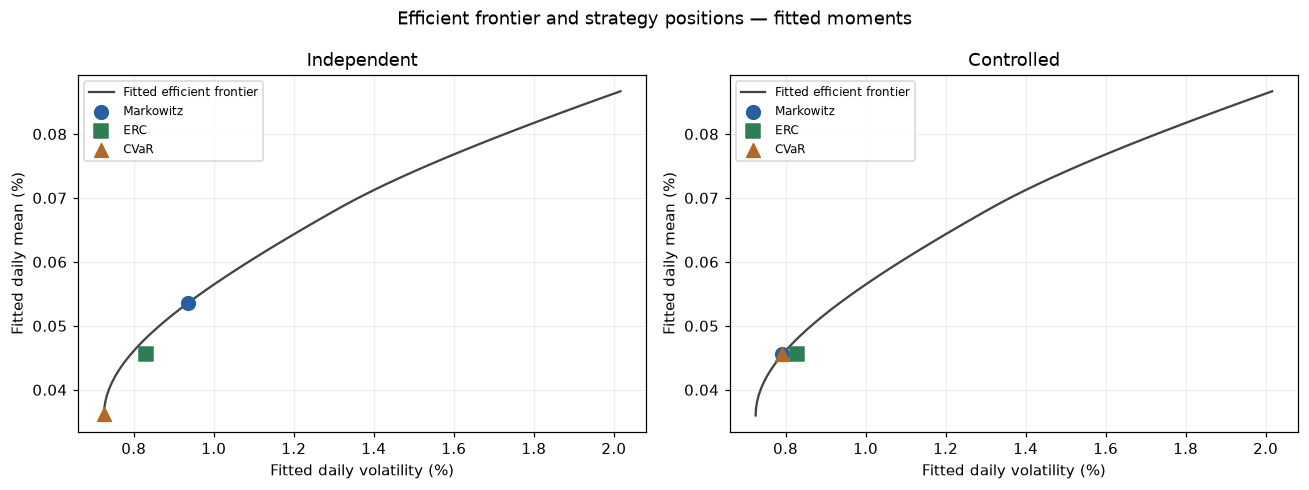

In [466]:
# 76.7. Draw both comparison modes and export the efficient frontier figure.
fig_frontier, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, mode in zip(axes, mode_order): draw_frontier(ax, mode)
fig_frontier.suptitle('Efficient frontier and strategy positions — fitted moments')
save_visual('efficient_frontier', fig_frontier)

### Task 77 — Generate the portfolio allocation comparison

Capital weights show where money is invested. They need not equal volatility contributions, even for ERC. Keep identical asset order, strategy colors and weight scales across modes.

#### Subtask 77.1 — Define the allocation panel using the saved weight table

Define the allocation panel using the saved weight table.

In [467]:
# 77.1. Define the allocation panel using the saved weight table.
def draw_allocations(ax, mode):
    weights_table[mode][strategy_order].plot.bar(ax=ax, rot=0,
        color=[strategy_colors[s] for s in strategy_order])
    ax.set(xlabel='Asset', ylabel='Capital weight', ylim=(0, 1), title=mode.title())
    ax.legend(fontsize=8)

#### Subtask 77.2 — Create separate allocation panels for independent and controlled portfolios

Create separate allocation panels for independent and controlled portfolios.

In [468]:
# 77.2. Create separate allocation panels for independent and controlled portfolios.
fig_allocation, allocation_axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

#### Subtask 77.3 — Populate each panel from the corresponding portfolio weights

Populate each panel from the corresponding portfolio weights.

In [469]:
# 77.3. Populate each panel from the corresponding portfolio weights.
for ax, mode in zip(allocation_axes, mode_order): draw_allocations(ax, mode)

#### Subtask 77.4 — Add the experiment caption and export the allocation figure

Add the experiment caption and export the allocation figure.

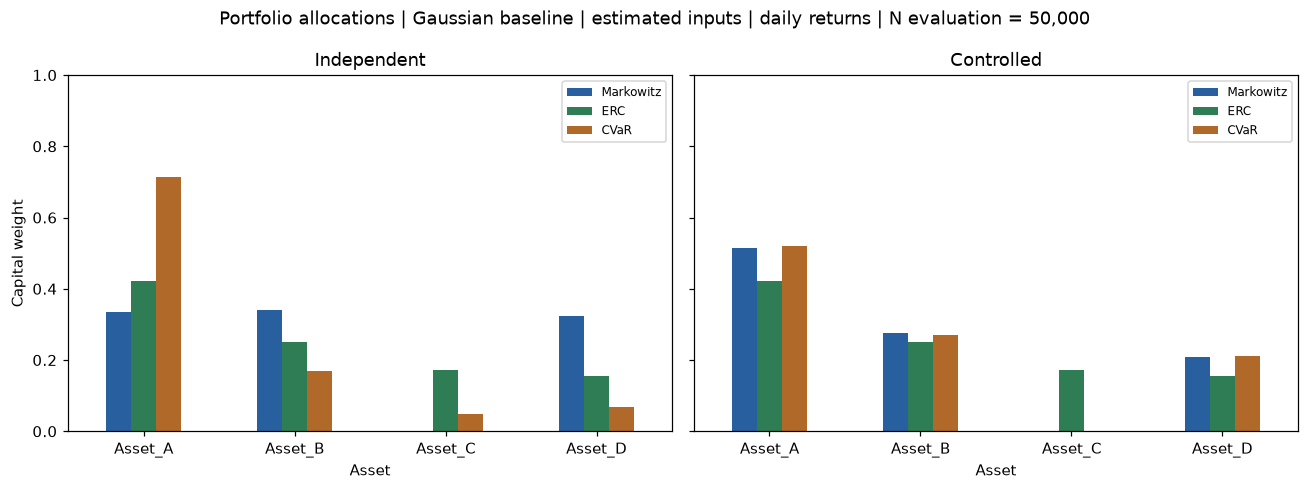

In [470]:
# 77.4. Add the experiment caption and export the allocation figure.
fig_allocation.suptitle('Portfolio allocations | ' + visual_caption)
save_visual('portfolio_allocations', fig_allocation)

### Task 78 — Generate Gaussian simulation diagnostics

Check normal marginals and dependence on the historical simulation used for moment diagnostics. Standardization uses population means and volatilities. A visual pattern is supporting evidence, not a substitute for the numerical uncertainty checks.

#### Subtask 78.1 — Standardize historical simulated asset returns with population parameters

Standardize historical simulated asset returns with population parameters.

In [471]:
# 78.1. Standardize historical simulated asset returns with population parameters.
standardized_history = (R_train-mu_true)/sigma_true

#### Subtask 78.2 — Choose the first two assets and a deterministic scatterplot subset

Choose the first two assets and a deterministic scatterplot subset.

In [472]:
# 78.2. Choose the first two assets and a deterministic scatterplot subset.
diagnostic_pair = (0, 1)
scatter_rows = np.arange(min(n_train, 3000))

#### Subtask 78.3 — Create four axes for the histogram, Q–Q plot, scatterplot and correlation errors

Create four axes for the histogram, Q–Q plot, scatterplot and correlation errors.

In [473]:
# 78.3. Create four axes for the histogram, Q–Q plot, scatterplot and correlation errors.
fig_simulation, sim_axes = plt.subplots(2, 2, figsize=(12, 9))

#### Subtask 78.4 — Overlay the first standardized marginal histogram with the standard normal density

Overlay the first standardized marginal histogram with the standard normal density.

In [474]:
# 78.4. Overlay the first standardized marginal histogram with the standard normal density.
normal_grid = np.linspace(-4, 4, 300)
sim_axes[0, 0].hist(standardized_history[:, 0], bins=60, density=True, alpha=0.55, label=asset_names[0])
sim_axes[0, 0].plot(normal_grid, stats.norm.pdf(normal_grid), color='black', label='N(0,1)')
sim_axes[0, 0].set(title='Gaussian marginal', xlabel='Standardized daily return', ylabel='Density')
sim_axes[0, 0].legend()

Out[474]: <matplotlib.legend.Legend at 0x118ad6e90>


#### Subtask 78.5 — Compare the first marginal quantiles with theoretical Gaussian quantiles

Compare the first marginal quantiles with theoretical Gaussian quantiles.

In [475]:
# 78.5. Compare the first marginal quantiles with theoretical Gaussian quantiles.
stats.probplot(standardized_history[:, 0], dist='norm', plot=sim_axes[0, 1])
sim_axes[0, 1].set(title='Gaussian Q–Q check: ' + asset_names[0])

Out[475]: [Text(0.5, 1.0, 'Gaussian Q–Q check: Asset_A')]


#### Subtask 78.6 — Plot paired asset observations and label their target and sample correlation

Plot paired asset observations and label their target and sample correlation.

In [476]:
# 78.6. Plot paired asset observations and label their target and sample correlation.
sim_axes[1, 0].scatter(standardized_history[scatter_rows, 0], standardized_history[scatter_rows, 1], s=4, alpha=0.25)
sim_axes[1, 0].set(xlabel=asset_names[0]+' standardized return', ylabel=asset_names[1]+' standardized return', title=f'Correlation: target {corr_true[0,1]:.3f}; sample {corr_hat[0,1]:.3f}')

Out[476]: 
[Text(0.5, 0, 'Asset_A standardized return'),
 Text(0, 0.5, 'Asset_B standardized return'),
 Text(0.5, 1.0, 'Correlation: target 0.300; sample 0.289')]


#### Subtask 78.7 — Define a labeled correlation-error heatmap centered on zero

Define a labeled correlation-error heatmap centered on zero.

In [477]:
# 78.7. Define a labeled correlation-error heatmap centered on zero.
def draw_correlation_errors(ax):
    limit = max(float(np.abs(correlation_errors).max()), 1e-6)
    image = ax.imshow(correlation_errors, cmap='RdBu_r', vmin=-limit, vmax=limit)
    ax.set_xticks(range(n_assets), asset_names, rotation=30, ha='right')
    ax.set_yticks(range(n_assets), asset_names)
    for i in range(n_assets):
        for j in range(n_assets):
            ax.text(j, i, f'{correlation_errors[i,j]:+.3f}', ha='center', va='center', fontsize=8,
                    color='white' if abs(correlation_errors[i,j]) > 0.6*limit else 'black')
    ax.set_title('Sample minus target correlation')
    ax.figure.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

#### Subtask 78.8 — Complete the dependence panel and export the simulation diagnostic figure

Complete the dependence panel and export the simulation diagnostic figure.

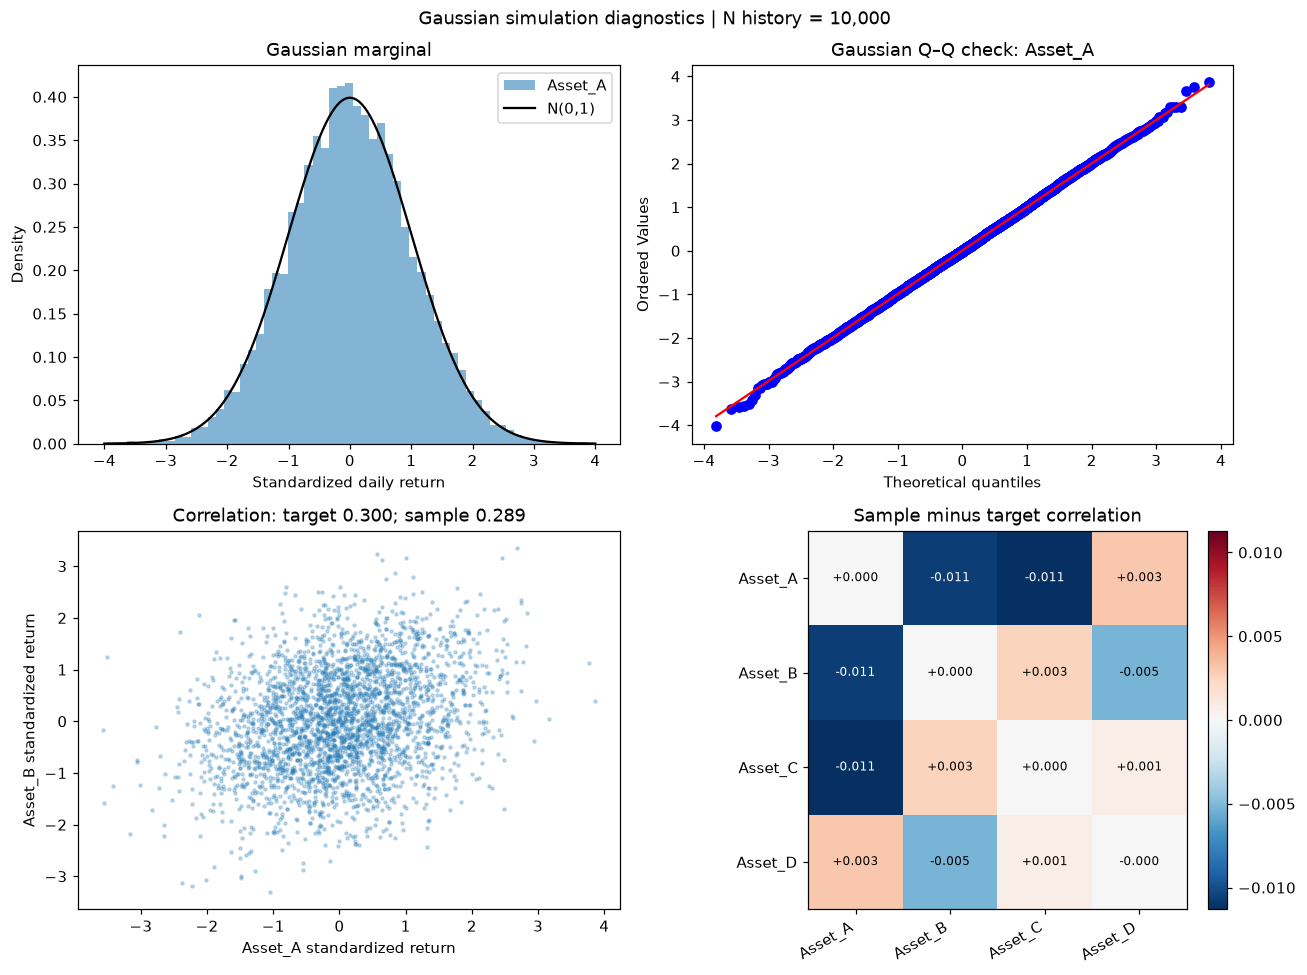

In [478]:
# 78.8. Complete the dependence panel and export the simulation diagnostic figure.
draw_correlation_errors(sim_axes[1, 1])
fig_simulation.suptitle(f'Gaussian simulation diagnostics | N history = {n_train:,}')
save_visual('gaussian_simulation_diagnostics', fig_simulation)

### Task 79 — Generate theoretical and simulated covariance heatmaps

Compare population covariance and sample covariance on the same color scale. A separate signed-error panel has its own symmetric scale. Values are daily decimal-return squared units.

#### Subtask 79.1 — Collect target, simulated and error covariance matrices in matching asset order

Collect target, simulated and error covariance matrices in matching asset order.

In [479]:
# 79.1. Collect target, simulated and error covariance matrices in matching asset order.
covariance_panels = [cov_true, cov_hat, cov_hat-cov_true]

#### Subtask 79.2 — Calculate shared limits for the first two heatmaps and symmetric limits for errors

Calculate shared limits for the first two heatmaps and symmetric limits for errors.

In [480]:
# 79.2. Calculate shared limits for the first two heatmaps and symmetric limits for errors.
cov_low, cov_high = min(cov_true.min(), cov_hat.min()), max(cov_true.max(), cov_hat.max())
cov_error_limit = max(float(np.abs(cov_hat-cov_true).max()), 1e-12)

#### Subtask 79.3 — Create three labeled covariance panels with numerical annotations

Create three labeled covariance panels with numerical annotations.

In [481]:
# 79.3. Create three labeled covariance panels with numerical annotations.
fig_covariance, covariance_axes = plt.subplots(1, 3, figsize=(15, 4.5))
for k, (ax, values, title) in enumerate(zip(covariance_axes, covariance_panels,
                                          ('Target covariance', 'Sample covariance', 'Sample minus target'))):
    limits = dict(vmin=cov_low, vmax=cov_high, cmap='YlGnBu') if k < 2 else dict(vmin=-cov_error_limit, vmax=cov_error_limit, cmap='RdBu_r')
    image = ax.imshow(values, **limits)
    ax.set_xticks(range(n_assets), asset_names, rotation=30, ha='right')
    ax.set_yticks(range(n_assets), asset_names)
    ax.set_title(title)
    for i in range(n_assets):
        for j in range(n_assets):
            ax.text(j, i, f'{values[i,j]:.1e}', ha='center', va='center', fontsize=7,
                    color='white' if (k < 2 and values[i,j] > (cov_low+cov_high)/2) or (k == 2 and abs(values[i,j]) > 0.6*cov_error_limit) else 'black')
    fig_covariance.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

#### Subtask 79.4 — Label the covariance units and export all three panels together

Label the covariance units and export all three panels together.

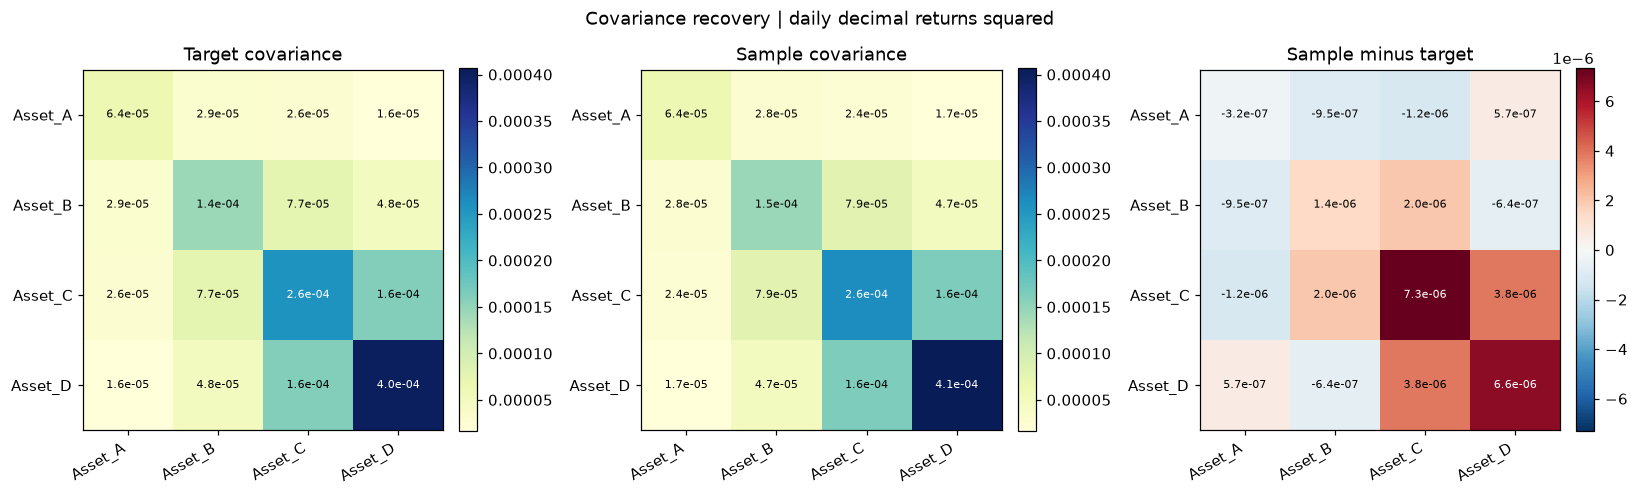

In [482]:
# 79.4. Label the covariance units and export all three panels together.
fig_covariance.suptitle('Covariance recovery | daily decimal returns squared')
save_visual('covariance_heatmaps', fig_covariance)

### Task 80 — Generate the ERC risk contribution figure

Show capital weights alongside fitted volatility risk shares. The equal-share line is 1/n. The underlying CSV also reports contributions in daily volatility units.

#### Subtask 80.1 — Create paired axes for capital weights and fitted volatility shares

Create paired axes for capital weights and fitted volatility shares.

In [483]:
# 80.1. Create paired axes for capital weights and fitted volatility shares.
fig_erc_check, erc_axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

#### Subtask 80.2 — Plot ERC capital weights in the original asset order

Plot ERC capital weights in the original asset order.

In [484]:
# 80.2. Plot ERC capital weights in the original asset order.
erc_axes[0].bar(asset_names, erc_check_w, color=strategy_colors['ERC'])
erc_axes[0].set(title='ERC capital weights', ylabel='Fraction', ylim=(0, 1))

Out[484]: [Text(0.5, 1.0, 'ERC capital weights'), Text(0, 0.5, 'Fraction'), (0.0, 1.0)]


#### Subtask 80.3 — Plot ERC volatility shares with the theoretical equal-share reference line

Plot ERC volatility shares with the theoretical equal-share reference line.

In [485]:
# 80.3. Plot ERC volatility shares with the theoretical equal-share reference line.
erc_axes[1].bar(asset_names, erc_check_shares, color=strategy_colors['ERC'])
erc_axes[1].axhline(1/n_assets, color='black', ls='--', label='Target 1/n')
erc_axes[1].set(title='ERC fitted volatility risk shares', ylabel='Fraction')
erc_axes[1].legend()

Out[485]: <matplotlib.legend.Legend at 0x118fa1450>


#### Subtask 80.4 — Save the numerical contributions and export the comparison figure

Save the numerical contributions and export the comparison figure.

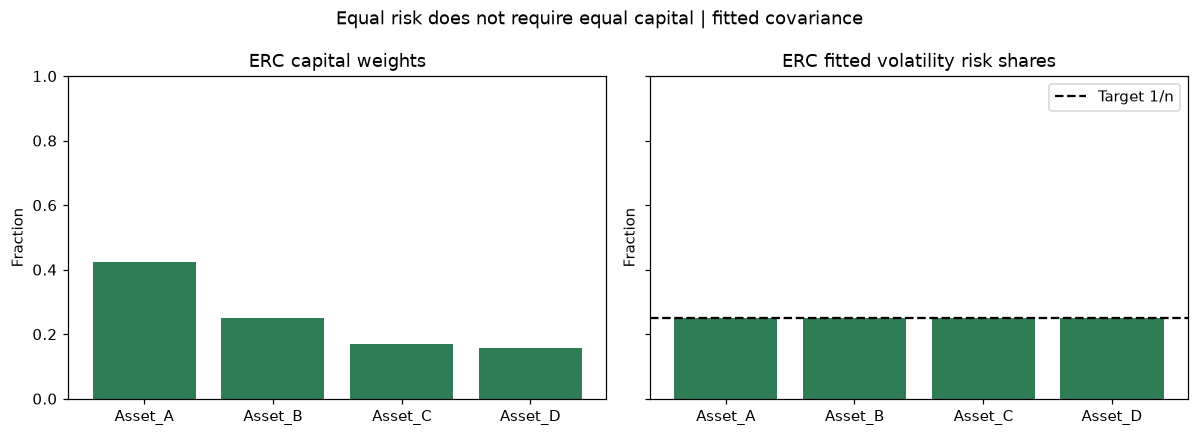

In [486]:
# 80.4. Save the numerical contributions and export the comparison figure.
erc_check_table.to_csv(run_dir/'erc_risk_contributions.csv', float_format='%.17g')
fig_erc_check.suptitle('Equal risk does not require equal capital | fitted covariance')
save_visual('erc_risk_contributions', fig_erc_check)

### Task 81 — Generate tail-loss distributions with VaR and CVaR markers

Loss is $L=-R_p$. Use common histogram bins and mark 95% evaluation VaR and CVaR. CVaR is an average of extreme losses, not a second quantile. Values at 99% remain in the comparison table.

#### Subtask 81.1 — Select the 95 percent reporting column and shared loss histogram bins

Select the 95 percent reporting column and shared loss histogram bins.

In [487]:
# 81.1. Select the 95 percent reporting column and shared loss histogram bins.
visual_alpha = 0.95
visual_alpha_index = int(np.flatnonzero(np.isclose(reporting_alphas, visual_alpha))[0])

#### Subtask 81.2 — Define a tail-distribution panel using consistent thresholds and strategy colors

Define a tail-distribution panel using consistent thresholds and strategy colors.

In [488]:
# 81.2. Define a tail-distribution panel using consistent thresholds and strategy colors.
def draw_tail_distribution(ax, mode):
    # All strategies use the same independent evaluation sample and bin edges.
    for strategy in strategy_order:
        j = portfolio_labels.index((mode, strategy))
        color = strategy_colors[strategy]
        ax.hist(L_eval[:, j]*100, bins=loss_bin_edges*100, density=True,
                histtype='step', color=color, label=strategy, linewidth=1.5)
        ax.axvline(var_eval[j, visual_alpha_index]*100, color=color, ls='--', alpha=0.8)
        ax.axvline(cvar_eval[j, visual_alpha_index]*100, color=color, ls=':', alpha=0.8)
    ax.axvline(0, color='#888888', linewidth=0.8)
    ax.set(xlabel='Daily loss (%)', ylabel='Density per percentage point',
           title=mode.title()+' | dashed VaR 95%; dotted CVaR 95%')
    ax.legend(fontsize=8)

#### Subtask 81.3 — Create distribution panels for both comparison modes

Create distribution panels for both comparison modes.

In [489]:
# 81.3. Create distribution panels for both comparison modes.
fig_tail_marked, marked_axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True, sharey=True)

#### Subtask 81.4 — Draw all strategies and add the common evaluation caption

Draw all strategies and add the common evaluation caption.

In [490]:
# 81.4. Draw all strategies and add the common evaluation caption.
for ax, mode in zip(marked_axes, mode_order): draw_tail_distribution(ax, mode)
fig_tail_marked.suptitle('Tail-loss distributions | ' + visual_caption)

Out[490]: Text(0.5, 0.98, 'Tail-loss distributions | Gaussian baseline | estimated inputs | daily returns | N evaluation = 50,000')


#### Subtask 81.5 — Export the marked loss distributions in all three figure formats

Export the marked loss distributions in all three figure formats.

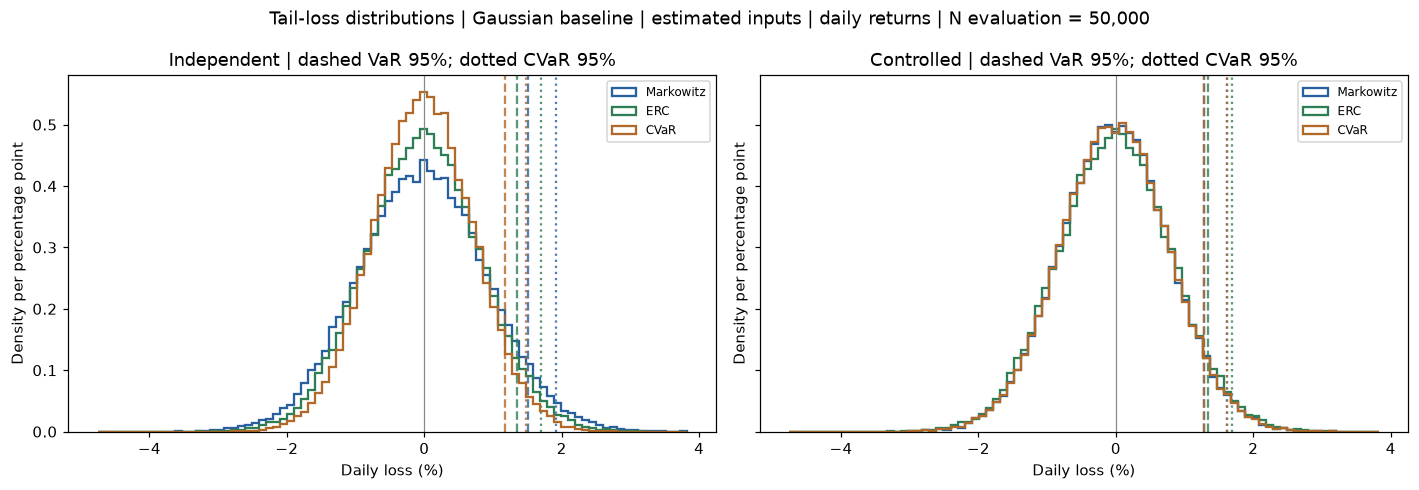

In [491]:
# 81.5. Export the marked loss distributions in all three figure formats.
save_visual('tail_loss_distributions', fig_tail_marked)

### Task 82 — Generate the performance comparison table

Report daily return, volatility, VaR, CVaR, tail frequency and capital concentration. Tail frequency uses frozen training VaR thresholds on independent evaluation data; it is not the almost-mechanical exceedance rate of an evaluation-sample quantile. HHI equals the sum of squared weights.

#### Subtask 82.1 — Select the requested risk, return, tail-frequency and concentration measures

Select the requested risk, return, tail-frequency and concentration measures.

In [492]:
# 82.1. Select the requested risk, return, tail-frequency and concentration measures.
performance_columns = ['mean_daily', 'volatility_daily', 'VaR_95%', 'CVaR_95%', 'VaR_99%', 'CVaR_99%', 'exceedance_rate_95%', 'exceedance_rate_99%', 'HHI']
performance_table = comparison[performance_columns].copy()

#### Subtask 82.2 — Save unrounded values before formatting the display table

Save unrounded values before formatting the display table.

In [493]:
# 82.2. Save unrounded values before formatting the display table.
performance_table.to_csv(run_dir/'performance_comparison.csv', float_format='%.17g')

#### Subtask 82.3 — Convert return and frequency columns to percentages while preserving unitless HHI

Convert return and frequency columns to percentages while preserving unitless HHI.

In [494]:
# 82.3. Convert return and frequency columns to percentages while preserving unitless HHI.
performance_display = performance_table.copy()
performance_display.loc[:, performance_columns[:-1]] *= 100
performance_display.index = [f'{mode} / {strategy}' for mode, strategy in performance_display.index]

#### Subtask 82.4 — Render both modes in a clearly labeled table figure

Render both modes in a clearly labeled table figure.

In [495]:
# 82.4. Render both modes in a clearly labeled table figure.
fig_performance, ax_performance = plt.subplots(figsize=(17, 4.6))
ax_performance.axis('off')
table_artist = ax_performance.table(
    cellText=[[f'{value:.4f}' for value in row] for row in performance_display.to_numpy()],
    rowLabels=performance_display.index,
    colLabels=['Mean %', 'Vol %', 'VaR95 %', 'CVaR95 %', 'VaR99 %', 'CVaR99 %', 'Exceed95 %', 'Exceed99 %', 'HHI'],
    cellLoc='center', loc='center')
table_artist.auto_set_font_size(False)
table_artist.set_fontsize(8)
table_artist.scale(1, 2)
for (row, col), cell in table_artist.get_celld().items():
    cell.set_edgecolor('#d9d9d9')
    if row == 0:
        cell.set_facecolor('#e8eef4')
    elif row % 2 == 0:
        cell.set_facecolor('#f5f5f5')

#### Subtask 82.5 — Add the units and frozen-threshold definition, display and export the table

Add the units and frozen-threshold definition, display and export the table.

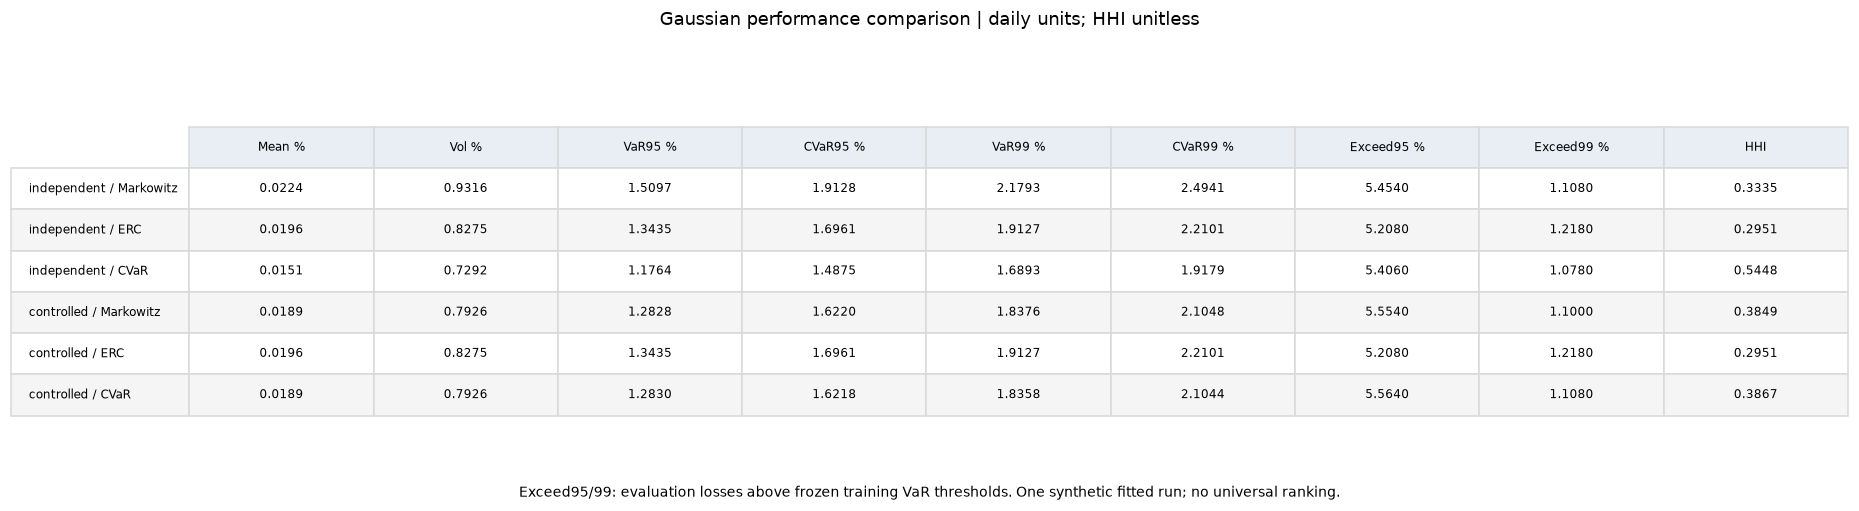

mean_daily  volatility_daily    VaR_95%   CVaR_95%  \
mode        strategy                                                        
independent Markowitz   0.0002237         0.0093164  0.0150972  0.0191283   
            ERC         0.0001961         0.0082750  0.0134352  0.0169608   
            CVaR        0.0001510         0.0072917  0.0117643  0.0148750   
controlled  Markowitz   0.0001888         0.0079265  0.0128279  0.0162197   
            ERC         0.0001961         0.0082750  0.0134352  0.0169608   
            CVaR        0.0001890         0.0079261  0.0128300  0.0162176   

                         VaR_99%   CVaR_99%  exceedance_rate_95%  \
mode        strategy                                               
independent Markowitz  0.0217929  0.0249414              0.05454   
            ERC        0.0191265  0.0221006              0.05208   
            CVaR       0.0168931  0.0191788              0.05406   
controlled  Markowitz  0.0183761  0.0210483              0.05554   
            ERC        0.0191265  0.0221006              0.05208   
            CVaR       0.0183577  0.0210440              0.05564   

                       exceedance_rate_99%        HHI  
mode        strategy                                   
independent Markowitz              0.01108  0.3334811  
            ERC                    0.01218  0.2950731  
            CVaR                   0.01078  0.5448384  
controlled  Markowitz              0.01100  0.3848516  
            ERC                    0.01218  0.2950731  
            CVaR                   0.01108  0.3867134

In [496]:
# 82.5. Add the units and frozen-threshold definition, display and export the table.
fig_performance.suptitle('Gaussian performance comparison | daily units; HHI unitless')
fig_performance.text(0.5, 0.02, 'Exceed95/99: evaluation losses above frozen training VaR thresholds. One synthetic fitted run; no universal ranking.', ha='center', fontsize=9)
save_visual('performance_comparison', fig_performance)
show(performance_table)

### Task 83 — Generate the four-panel Gaussian comparison dashboards

Combine the efficient frontier, allocations, correlation diagnostic and marked loss distributions. Save one dashboard for each mode. The first panel uses fitted moments; the loss panel uses independent evaluation data; the correlation panel uses historical simulated data.

#### Subtask 83.1 — Define the dashboard from the existing panel-drawing functions

Define the dashboard from the existing panel-drawing functions.

In [497]:
# 83.1. Define the dashboard from the existing panel-drawing functions.
def build_dashboard(mode):
    fig, axes = plt.subplots(2, 2, figsize=(15, 11))
    draw_frontier(axes[0, 0], mode)
    draw_allocations(axes[0, 1], mode)
    draw_correlation_errors(axes[1, 0])
    draw_tail_distribution(axes[1, 1], mode)
    fig.suptitle(f'Gaussian portfolio comparison — {mode}\n{visual_caption}', fontsize=14)
    return fig

#### Subtask 83.2 — Build the primary dashboard for independently optimized strategies

Build the primary dashboard for independently optimized strategies.

In [498]:
# 83.2. Build the primary dashboard for independently optimized strategies.
independent_dashboard = build_dashboard('independent')

#### Subtask 83.3 — Export the primary four-panel Gaussian dashboard

Export the primary four-panel Gaussian dashboard.

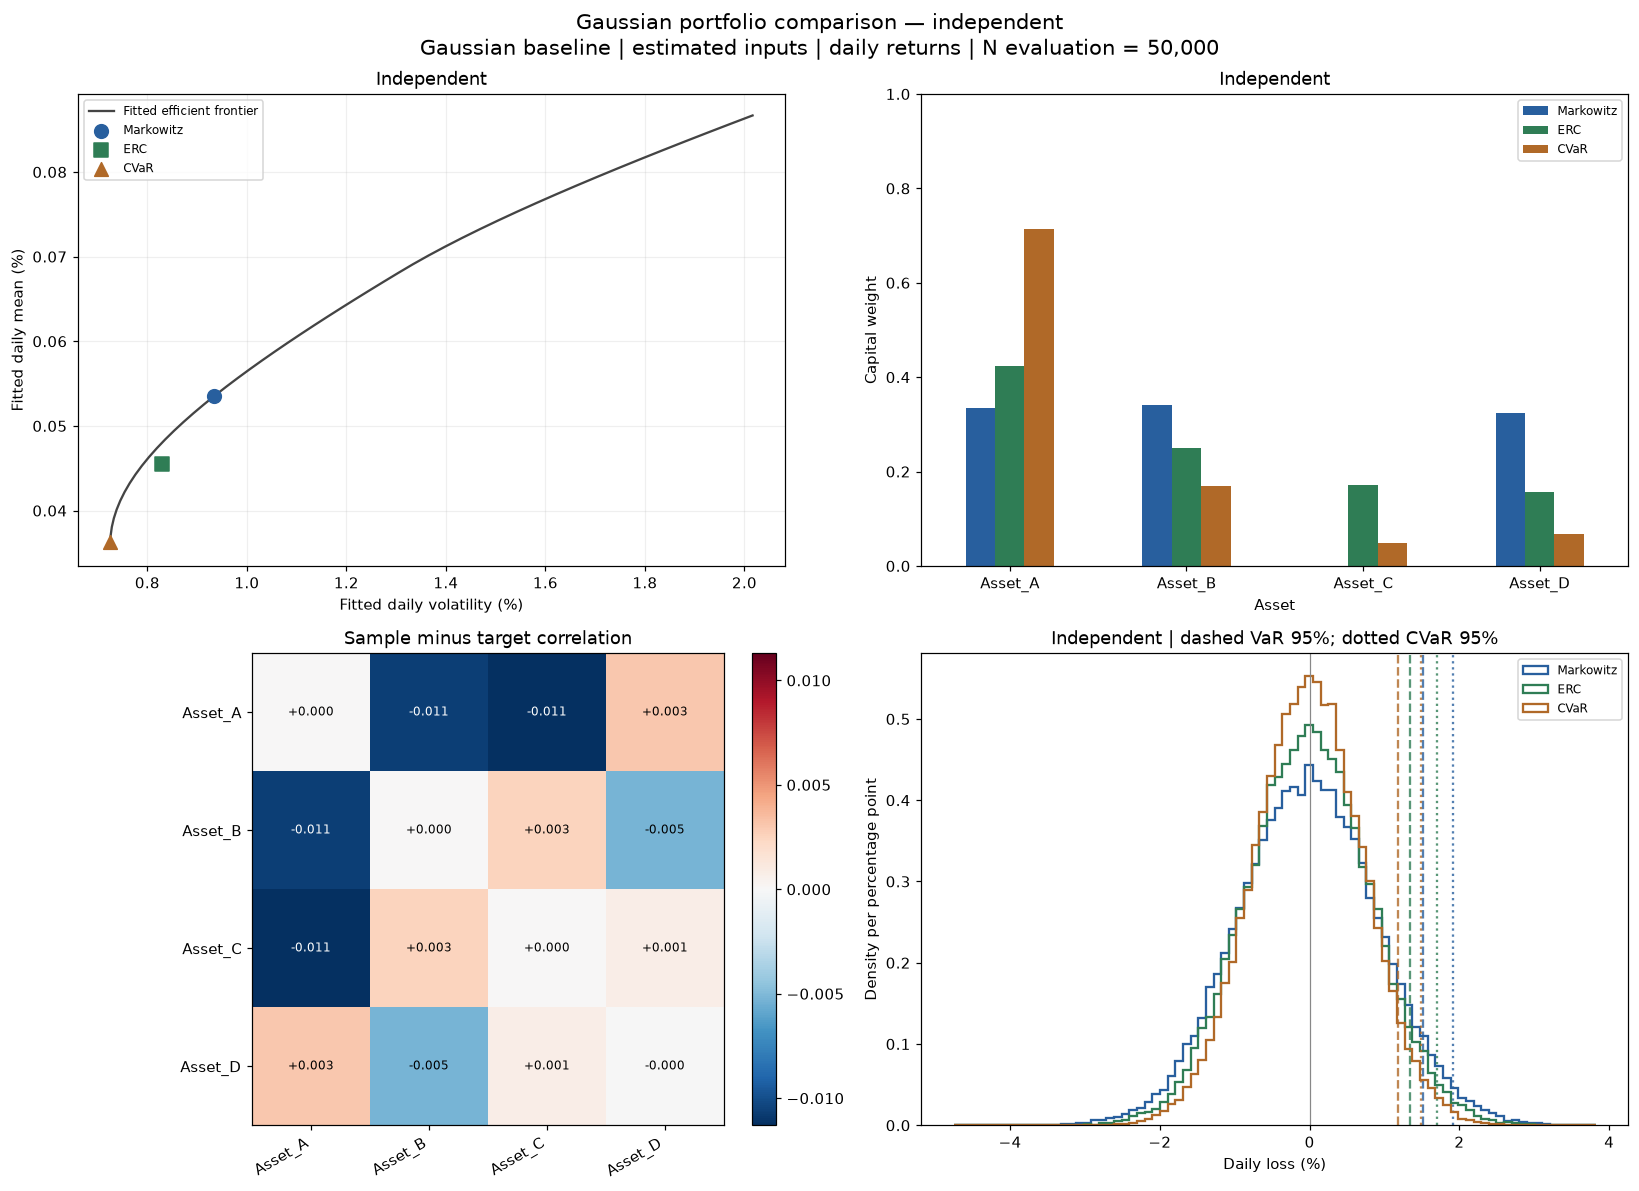

In [499]:
# 83.3. Export the primary four-panel Gaussian dashboard.
save_visual('gaussian_dashboard_independent', independent_dashboard)

#### Subtask 83.4 — Build the controlled dashboard with the common fitted-return comparison

Build the controlled dashboard with the common fitted-return comparison.

In [500]:
# 83.4. Build the controlled dashboard with the common fitted-return comparison.
controlled_dashboard = build_dashboard('controlled')

#### Subtask 83.5 — Export the controlled four-panel Gaussian dashboard

Export the controlled four-panel Gaussian dashboard.

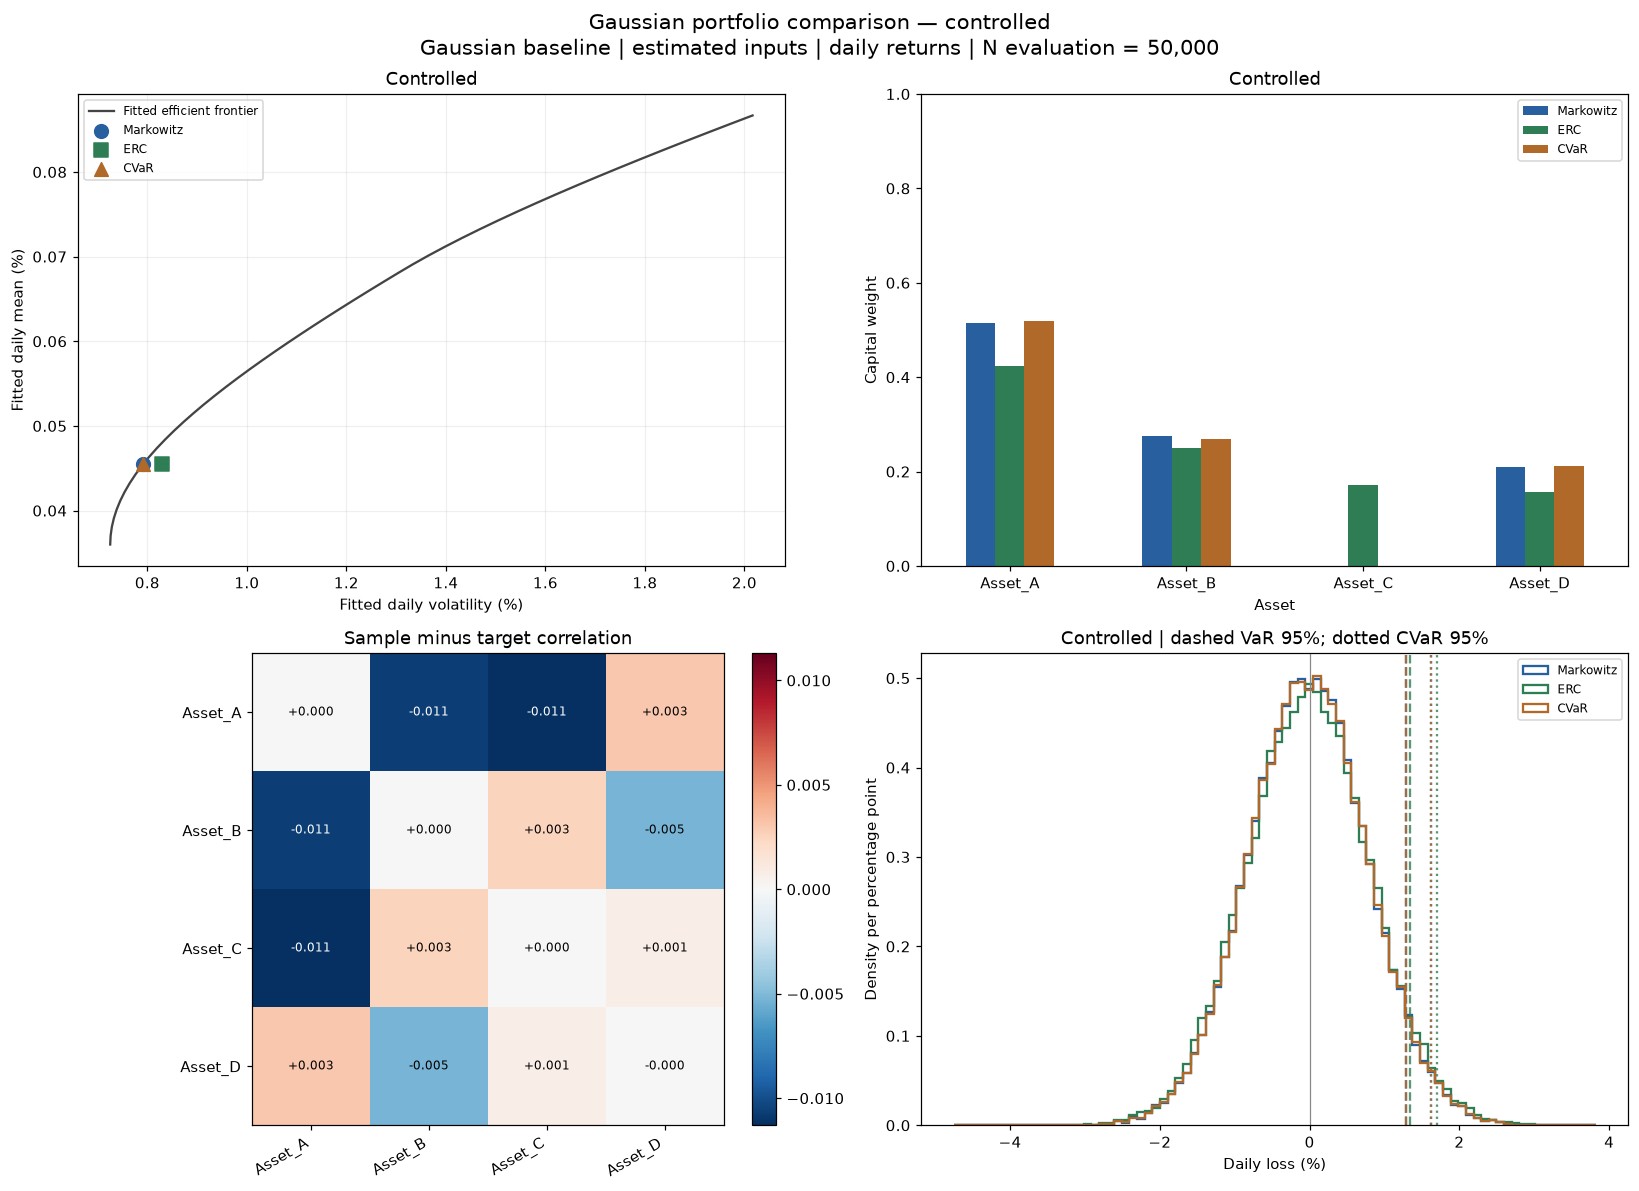

In [501]:
# 83.5. Export the controlled four-panel Gaussian dashboard.
save_visual('gaussian_dashboard_controlled', controlled_dashboard)

### Task 84 — Validate and register the completed visual outputs

Finalize only after every requested figure and supporting table exists. Record deterministic checks separately from statistical flags, refresh checksums and print the exact output folder.

#### Subtask 84.1 — List every new figure and verify nonempty PNG, PDF and SVG exports

List every new figure and verify nonempty PNG, PDF and SVG exports.

In [502]:
# 84.1. List every new figure and verify nonempty PNG, PDF and SVG exports.
expected_visuals = ['efficient_frontier', 'portfolio_allocations', 'gaussian_simulation_diagnostics', 'covariance_heatmaps', 'erc_risk_contributions', 'tail_loss_distributions', 'performance_comparison', 'gaussian_dashboard_independent', 'gaussian_dashboard_controlled']
check('84 all new visual exports', all((run_dir/'figures'/f'{name}.{ext}').is_file() and (run_dir/'figures'/f'{name}.{ext}').stat().st_size > 0 for name in expected_visuals for ext in ('png', 'pdf', 'svg')))

#### Subtask 84.2 — Save a visual index linking each output to its data source and notebook task

Save a visual index linking each output to its data source and notebook task.

In [503]:
# 84.2. Save a visual index linking each output to its data source and notebook task.
visual_index = pd.DataFrame({'figure': expected_visuals, 'task': [76, 77, 78, 79, 80, 81, 82, 83, 83], 'data_source': ['fitted moments', 'fitted weights', 'historical simulated returns', 'population and historical covariance', 'fitted ERC covariance', 'independent evaluation losses', 'independent evaluation and training thresholds', 'fitted, historical and evaluation panels', 'fitted, historical and evaluation panels']})
visual_index.to_csv(run_dir/'visual_index.csv', index=False)
show(visual_index)

,figure,task,data_source
0,efficient_frontier,76,fitted moments
1,portfolio_allocations,77,fitted weights
2,gaussian_simulation_diagnostics,78,historical simulated returns
3,covariance_heatmaps,79,population and historical covariance
4,erc_risk_contributions,80,fitted ERC covariance
5,tail_loss_distributions,81,independent evaluation losses
6,performance_comparison,82,independent evaluation and training thresholds
7,gaussian_dashboard_independent,83,"fitted, historical and evaluation panels"
8,gaussian_dashboard_controlled,83,"fitted, historical and evaluation panels"


#### Subtask 84.3 — Refresh the validation report with the added checks and explicit diagnostic statuses

Refresh the validation report with the added checks and explicit diagnostic statuses.

In [504]:
# 84.3. Refresh the validation report with the added checks and explicit diagnostic statuses.
validation_report.update({'deterministic_checks': checks, 'statistical_diagnostics': statistical_flags, 'moment_status': moment_status, 'tail_check_status_file': 'tail_check_status.csv'})
write_json(run_dir/'validation_report.json', validation_report)

#### Subtask 84.4 — Refresh the final manifest and include checksums for all added artifacts

Refresh the final manifest and include checksums for all added artifacts.

In [505]:
# 84.4. Refresh the final manifest and include checksums for all added artifacts.
manifest.update({'status': status, 'deterministic_checks': len(checks), 'visual_tasks': [75, 84], 'new_figures': expected_visuals})
manifest['artifacts'] = {str(p.relative_to(run_dir)): hashlib.sha256(p.read_bytes()).hexdigest() for p in run_dir.rglob('*') if p.is_file() and p.name != 'manifest.json'}
write_json(run_dir/'manifest.json', manifest)

#### Subtask 84.5 — Print the final figure folder and numerical validation summary

Print the final figure folder and numerical validation summary.

In [506]:
# 84.5. Print the final figure folder and numerical validation summary.
print(f'{len(checks)} deterministic checks passed; {flag_count} statistical flags.')
print('Diagrams saved to:', (run_dir/'figures').resolve())
print('Open gaussian_dashboard_independent.png for the primary four-panel overview.')

192 deterministic checks passed; 0 statistical flags.
Diagrams saved to: /Users/morty/Documents/ChatGPT/Thesis Under Prof. Rubtsov/notebooks/milestone4_results/milestone4_gaussian_20261120T132115293121Z/figures
Open gaussian_dashboard_independent.png for the primary four-panel overview.
